# Phase 2: named entity recognition — all original experiments


In [3]:
# MODEL D CONTROLS — edit these in this first code cell.
NOTEBOOK_VERSION = "ABC_OPTIONAL_D_V3_2026_10_11"
INCLUDE_MODEL_D = False  # False: five A/B/C experiments. True: also run D_lorma.
MODEL_D_CHECKPOINT = "/kaggle/input/models/ikrimabadr/modeld/pytorch/default/1"  # Actual saved D .pt path; leave empty while D is skipped.
RUN_WORKFLOW = True
ALLOW_PHASE1_DOWNLOADS = True

from pathlib import Path
import gc
import importlib.util
import json
import math
import os
import subprocess
import sys
import time

MAX_GPUS = 2
PREFLIGHT_COMPLETE = False
ROOT = (
    Path("/kaggle/working/cs781-phase2-longer1")
    if Path("/kaggle").is_dir()
    else Path.cwd() / "cs781-phase2-longer"
).resolve()
RUNTIME = (Path.cwd() / "phase2_runtime").resolve()
RUNTIME.mkdir(parents=True, exist_ok=True)
ROOT.mkdir(parents=True, exist_ok=True)
DATA_DIR = ROOT / "official_data"  # parent of Phase_2_LNER/
OUTPUT_DIR = ROOT / "results"

# Source paths taken from the uploaded notebooks. D deliberately has no guessed filename.
PHASE1_PATHS = {
    "A": "/kaggle/working/legal-lm-phase1-optimized/baseline_71m_200m_optimized_2gpu/checkpoint-00003051.pt",
    "B": "/kaggle/working/cs781-phase1-encdec-50m/encdec_5e5d_640_50m_2gpu/checkpoint-00000762.pt",
    "C": "/kaggle/working/cs781-phase1-model-c-gqa-200m/model_c_gqa_rope_72m_200m_2gpu/checkpoint-00003051.pt",
    "D": "/kaggle/working/cs781-phase1-model-d-prefixlm-75m/model_d_prefixlm_82m_75m_2gpu1",
}
CHECKPOINT_OVERRIDES = {}
# For D, use MODEL_D_CHECKPOINT at the top of this cell (or an explicit D override).
# Leave A/B/C unset to allow their own authenticated backup fallback.

DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATASET_REVISION = "89edba6a44d6bb9593fd13b6895b5cd3b06eb82e"
SPLIT_JSON = None  # Optional JSON object: {"train_ids": [...], "dev_ids": [...]}.
SEED = 42
DEV_FRACTION = 0.20
WINDOW_TOKENS = 512
OVERLAP_TOKENS = 64
EPOCHS = 25
PATIENCE = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.05
MAX_GRAD_NORM = 1.0
MICRO_BATCH_PER_GPU = 16
EFFECTIVE_BATCH_WINDOWS = 32
EVAL_BATCH_SIZE = 32
WORKERS_PER_RANK = 1
CPU_THREADS_PER_RANK = 2
COMPILE_MODEL = False  # Optional; compilation startup can outweigh savings for short runs.
LOG_EVERY_STEPS = 10
print("Output folder:", ROOT)
print("NOTEBOOK VERSION:", NOTEBOOK_VERSION)
print("Real training enabled:", RUN_WORKFLOW)
print("Model D included:", INCLUDE_MODEL_D)
print("Default plan:", "A/B/C + D LoRMA+" if INCLUDE_MODEL_D else "Five A/B/C experiments; D skipped")


Output folder: /kaggle/working/cs781-phase2-longer1
NOTEBOOK VERSION: ABC_OPTIONAL_D_V3_2026_10_11
Real training enabled: True
Model D included: False
Default plan: Five A/B/C experiments; D skipped


## Configuration and original paths


In [4]:
# Keep Kaggle's installed PyTorch/CUDA. Install only small missing helper packages.
from importlib.metadata import version, PackageNotFoundError
requirements = []
try:
    if version("tokenizers") != "0.21.2": requirements.append("tokenizers==0.21.2")
except PackageNotFoundError:
    requirements.append("tokenizers==0.21.2")
try:
    hub_version = tuple(int(x) for x in version("huggingface_hub").split(".")[:2])
    if not (hub_version >= (0, 34) and hub_version < (1, 0)):
        requirements.append("huggingface_hub>=0.34,<1")
except PackageNotFoundError:
    requirements.append("huggingface_hub>=0.34,<1")
if importlib.util.find_spec("matplotlib") is None: requirements.append("matplotlib>=3.8,<4")
if requirements:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requirements], check=True)
import torch
torch_version = tuple(int(x) for x in torch.__version__.split("+")[0].split(".")[:2])
if torch_version < (2, 3): raise RuntimeError("Use a runtime with PyTorch 2.3+ and its matching CUDA installation.")
print("PyTorch:", torch.__version__, "CUDA GPUs:", torch.cuda.device_count())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.3 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires tokenizers<0.24.0,>=0.23.1, but you have tokenizers 0.21.2 which is incompatible.


PyTorch: 2.11.0+cu128 CUDA GPUs: 2


## Backbones and task modules


In [5]:
%%writefile phase2_runtime/legal_encdec_model.py
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


def parameter_counts(model):
    seen = set(); total = 0; trainable = 0
    for p in model.parameters():
        if id(p) in seen:
            continue
        seen.add(id(p)); total += p.numel()
        if p.requires_grad:
            trainable += p.numel()
    return {"total": total, "trainable": trainable}


def seq2seq_loss(logits, labels):
    if logits.ndim != 3 or labels.ndim != 2 or logits.shape[:2] != labels.shape:
        raise ValueError("Expected logits [B,T,V] and labels [B,T]")
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1))


def initialize_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Embedding):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
    elif isinstance(module, nn.LayerNorm):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc1 = nn.Linear(cfg["d_model"], cfg["d_ff"])
        self.fc2 = nn.Linear(cfg["d_ff"], cfg["d_model"])
        self.dropout = nn.Dropout(cfg["dropout"])

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return self.dropout(x)


class EncoderSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.d_model = cfg["d_model"]
        self.n_heads = cfg["n_heads"]
        if self.d_model % self.n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.head_dim = self.d_model // self.n_heads
        self.dropout_p = float(cfg["dropout"])
        self.qkv = nn.Linear(self.d_model, 3 * self.d_model)
        self.out = nn.Linear(self.d_model, self.d_model)
        self.out_dropout = nn.Dropout(cfg["dropout"])

    def forward(self, x):
        B, S, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, S, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, S, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, S, self.n_heads, self.head_dim).transpose(1, 2)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=False,
        )
        y = y.transpose(1, 2).contiguous().view(B, S, D)
        return self.out_dropout(self.out(y))


class DecoderSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.d_model = cfg["d_model"]
        self.n_heads = cfg["n_heads"]
        if self.d_model % self.n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.head_dim = self.d_model // self.n_heads
        self.dropout_p = float(cfg["dropout"])
        self.qkv = nn.Linear(self.d_model, 3 * self.d_model)
        self.out = nn.Linear(self.d_model, self.d_model)
        self.out_dropout = nn.Dropout(cfg["dropout"])

    def _shape(self, x, B, T):
        return x.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = self._shape(q, B, T); k = self._shape(k, B, T); v = self._shape(v, B, T)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=True,
        )
        y = y.transpose(1, 2).contiguous().view(B, T, D)
        return self.out_dropout(self.out(y))

    def step(self, x, past_kv=None):
        # x: [B,1,D]. There are no future keys in the cache, so no causal mask is needed.
        B, T, D = x.shape
        if T != 1:
            raise ValueError("DecoderSelfAttention.step expects one token")
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = self._shape(q, B, 1); k = self._shape(k, B, 1); v = self._shape(v, B, 1)
        if past_kv is not None:
            pk, pv = past_kv
            k = torch.cat((pk, k), dim=-2)
            v = torch.cat((pv, v), dim=-2)
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=False)
        y = y.transpose(1, 2).contiguous().view(B, 1, D)
        return self.out(y), (k, v)


class CrossAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.d_model = cfg["d_model"]
        self.n_heads = cfg["n_heads"]
        if self.d_model % self.n_heads:
            raise ValueError("d_model must be divisible by n_heads")
        self.head_dim = self.d_model // self.n_heads
        self.dropout_p = float(cfg["dropout"])
        self.q_proj = nn.Linear(self.d_model, self.d_model)
        self.kv_proj = nn.Linear(self.d_model, 2 * self.d_model)
        self.out = nn.Linear(self.d_model, self.d_model)
        self.out_dropout = nn.Dropout(cfg["dropout"])

    def _shape(self, x, B, L):
        return x.view(B, L, self.n_heads, self.head_dim).transpose(1, 2)

    def project_kv(self, memory):
        B, S, _ = memory.shape
        k, v = self.kv_proj(memory).chunk(2, dim=-1)
        return self._shape(k, B, S), self._shape(v, B, S)

    def forward_projected(self, x, projected_kv):
        B, T, D = x.shape
        k, v = projected_kv
        q = self._shape(self.q_proj(x), B, T)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=False,
        )
        y = y.transpose(1, 2).contiguous().view(B, T, D)
        return self.out_dropout(self.out(y))

    def forward(self, x, memory):
        return self.forward_projected(x, self.project_kv(memory))


class EncoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]; eps = cfg["norm_epsilon"]
        self.norm1 = nn.LayerNorm(d, eps=eps)
        self.self_attention = EncoderSelfAttention(cfg)
        self.norm2 = nn.LayerNorm(d, eps=eps)
        self.ffn = FeedForward(cfg)

    def forward(self, x):
        x = x + self.self_attention(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]; eps = cfg["norm_epsilon"]
        self.norm1 = nn.LayerNorm(d, eps=eps)
        self.self_attention = DecoderSelfAttention(cfg)
        self.norm2 = nn.LayerNorm(d, eps=eps)
        self.cross_attention = CrossAttention(cfg)
        self.norm3 = nn.LayerNorm(d, eps=eps)
        self.ffn = FeedForward(cfg)

    def forward(self, x, memory):
        x = x + self.self_attention(self.norm1(x))
        x = x + self.cross_attention(self.norm2(x), memory)
        x = x + self.ffn(self.norm3(x))
        return x

    def prepare_cross(self, memory):
        return self.cross_attention.project_kv(memory)

    def step(self, x, past_kv, cross_kv):
        sa, new_kv = self.self_attention.step(self.norm1(x), past_kv)
        x = x + sa
        x = x + self.cross_attention.forward_projected(self.norm2(x), cross_kv)
        x = x + self.ffn(self.norm3(x))
        return x, new_kv


class EncoderDecoderLegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        required = (
            "vocab_size", "source_length", "target_length", "d_model", "n_heads",
            "n_encoder_layers", "n_decoder_layers", "d_ff", "dropout",
            "norm_epsilon", "tie_embeddings",
        )
        for key in required:
            if key not in cfg:
                raise ValueError(f"Missing config field: {key}")
        if cfg["d_model"] % cfg["n_heads"]:
            raise ValueError("d_model must be divisible by n_heads")
        if min(cfg["source_length"], cfg["target_length"], cfg["n_encoder_layers"], cfg["n_decoder_layers"]) <= 0:
            raise ValueError("Lengths/layer counts must be positive")

        self.token_embedding = nn.Embedding(cfg["vocab_size"], cfg["d_model"])
        self.encoder_positions = nn.Embedding(cfg["source_length"], cfg["d_model"])
        self.decoder_positions = nn.Embedding(cfg["target_length"], cfg["d_model"])
        self.embedding_dropout = nn.Dropout(cfg["dropout"])
        self.encoder_blocks = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg["n_encoder_layers"])])
        self.decoder_blocks = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg["n_decoder_layers"])])
        self.encoder_norm = nn.LayerNorm(cfg["d_model"], eps=cfg["norm_epsilon"])
        self.decoder_norm = nn.LayerNorm(cfg["d_model"], eps=cfg["norm_epsilon"])
        self.lm_head = nn.Linear(cfg["d_model"], cfg["vocab_size"], bias=False)
        self.apply(initialize_weights)
        if cfg["tie_embeddings"]:
            self.lm_head.weight = self.token_embedding.weight

    def encode(self, source_ids):
        if source_ids.ndim != 2:
            raise ValueError("source_ids must be [B,S]")
        B, S = source_ids.shape
        if not 0 < S <= self.cfg["source_length"]:
            raise ValueError("Invalid source length")
        pos = torch.arange(S, device=source_ids.device)
        x = self.token_embedding(source_ids) + self.encoder_positions(pos)[None, :, :]
        x = self.embedding_dropout(x)
        for block in self.encoder_blocks:
            x = block(x)
        return self.encoder_norm(x)

    def decode(self, decoder_input_ids, memory):
        if decoder_input_ids.ndim != 2:
            raise ValueError("decoder_input_ids must be [B,T]")
        B, T = decoder_input_ids.shape
        if not 0 < T <= self.cfg["target_length"]:
            raise ValueError("Invalid decoder length")
        if memory.ndim != 3 or memory.shape[0] != B:
            raise ValueError("Invalid encoder memory")
        pos = torch.arange(T, device=decoder_input_ids.device)
        x = self.token_embedding(decoder_input_ids) + self.decoder_positions(pos)[None, :, :]
        x = self.embedding_dropout(x)
        for block in self.decoder_blocks:
            x = block(x, memory)
        return self.decoder_norm(x)

    def forward(self, source_ids, decoder_input_ids):
        if source_ids.shape[0] != decoder_input_ids.shape[0]:
            raise ValueError("Batch mismatch")
        memory = self.encode(source_ids)
        return self.lm_head(self.decode(decoder_input_ids, memory))

    @torch.inference_mode()
    def prepare_generation(self, source_ids):
        was_training = self.training
        self.eval()
        memory = self.encode(source_ids)
        cross_cache = [block.prepare_cross(memory) for block in self.decoder_blocks]
        if was_training:
            self.train()
        return cross_cache

    @torch.inference_mode()
    def generation_step(self, token_ids, position, cross_cache, self_cache=None):
        # token_ids: [B,1], position is the absolute decoder position of token_ids.
        if token_ids.ndim != 2 or token_ids.shape[1] != 1:
            raise ValueError("generation_step expects [B,1]")
        if not 0 <= int(position) < self.cfg["target_length"]:
            raise ValueError("Decoder position outside trained range")
        was_training = self.training
        self.eval()
        B = token_ids.shape[0]
        pos = torch.tensor([int(position)], device=token_ids.device)
        x = self.token_embedding(token_ids) + self.decoder_positions(pos)[None, :, :]
        # dropout is disabled in eval
        if self_cache is None:
            self_cache = [None] * len(self.decoder_blocks)
        if len(self_cache) != len(self.decoder_blocks) or len(cross_cache) != len(self.decoder_blocks):
            raise ValueError("Cache length mismatch")
        new_cache = []
        for i, block in enumerate(self.decoder_blocks):
            x, kv = block.step(x, self_cache[i], cross_cache[i])
            new_cache.append(kv)
        logits = self.lm_head(self.decoder_norm(x))
        if was_training:
            self.train()
        return logits, new_cache

Writing phase2_runtime/legal_encdec_model.py


In [6]:
%%writefile phase2_runtime/legal_gqa_model.py
from __future__ import annotations
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def parameter_counts(model):
    seen = set()
    total = trainable = 0
    for p in model.parameters():
        if id(p) in seen:
            continue
        seen.add(id(p))
        total += p.numel()
        if p.requires_grad:
            trainable += p.numel()
    return {"total": total, "trainable": trainable}


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = float(eps)

    def forward(self, x):
        dtype = x.dtype
        y = x.float()
        y = y * torch.rsqrt(y.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return y.to(dtype) * self.weight


class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_seq_len, theta=10000.0):
        super().__init__()
        if head_dim % 2:
            raise ValueError("RoPE head_dim must be even")
        inv = 1.0 / (
            float(theta) ** (torch.arange(0, head_dim, 2, dtype=torch.float32) / head_dim)
        )
        positions = torch.arange(max_seq_len, dtype=torch.float32)
        freqs = torch.outer(positions, inv)
        self.register_buffer("cos_cached", freqs.cos(), persistent=False)
        self.register_buffer("sin_cached", freqs.sin(), persistent=False)
        self.max_seq_len = int(max_seq_len)

    def forward(self, x, offset=0):
        # x: [B,H,T,head_dim]
        T = x.shape[-2]
        end = int(offset) + T
        if end > self.max_seq_len:
            raise ValueError(f"RoPE position {end} exceeds {self.max_seq_len}")
        cos = self.cos_cached[offset:end].to(device=x.device, dtype=x.dtype)[None, None]
        sin = self.sin_cached[offset:end].to(device=x.device, dtype=x.dtype)[None, None]
        even, odd = x[..., 0::2], x[..., 1::2]
        rotated = torch.stack((even * cos - odd * sin, even * sin + odd * cos), dim=-1)
        return rotated.flatten(-2)


class GroupedQueryAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D = int(cfg["d_model"])
        H = int(cfg["n_heads"])
        K = int(cfg["n_kv_heads"])
        if D % H:
            raise ValueError("d_model must be divisible by n_heads")
        if H % K:
            raise ValueError("n_heads must be divisible by n_kv_heads")
        self.d_model = D
        self.n_heads = H
        self.n_kv_heads = K
        self.head_dim = D // H
        self.groups = H // K
        self.dropout_p = float(cfg["dropout"])

        self.q_proj = nn.Linear(D, H * self.head_dim, bias=False)
        self.k_proj = nn.Linear(D, K * self.head_dim, bias=False)
        self.v_proj = nn.Linear(D, K * self.head_dim, bias=False)
        self.o_proj = nn.Linear(H * self.head_dim, D, bias=False)
        self.resid_dropout = nn.Dropout(self.dropout_p)
        self.rope = RotaryEmbedding(
            self.head_dim, int(cfg["context_length"]), float(cfg["rope_theta"])
        )

    def forward(self, x, past_kv=None, use_cache=False):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)

        past_len = 0 if past_kv is None else int(past_kv[0].shape[-2])
        q = self.rope(q, past_len)
        k = self.rope(k, past_len)

        if past_kv is not None:
            pk, pv = past_kv
            k = torch.cat((pk, k), dim=-2)
            v = torch.cat((pv, v), dim=-2)

        present = (k, v) if use_cache else None

        # Explicit expansion is maximally compatible across Kaggle PyTorch builds.
        # The stored/projection K/V tensors still use only n_kv_heads=2.
        k_attn = k.repeat_interleave(self.groups, dim=1)
        v_attn = v.repeat_interleave(self.groups, dim=1)

        # Full-sequence training is causal. Cached generation feeds one new token;
        # every cache key is past/current, so that one-token query needs no mask.
        causal = past_kv is None and T > 1
        a = F.scaled_dot_product_attention(
            q,
            k_attn,
            v_attn,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=causal,
        )
        a = a.transpose(1, 2).contiguous().view(B, T, self.d_model)
        return self.resid_dropout(self.o_proj(a)), present


class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, Ff = int(cfg["d_model"]), int(cfg["d_ff"])
        self.gate = nn.Linear(D, Ff, bias=False)
        self.up = nn.Linear(D, Ff, bias=False)
        self.down = nn.Linear(Ff, D, bias=False)
        self.dropout = nn.Dropout(float(cfg["dropout"]))

    def forward(self, x):
        return self.dropout(self.down(F.silu(self.gate(x)) * self.up(x)))


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, eps = int(cfg["d_model"]), float(cfg["norm_epsilon"])
        self.attn_norm = RMSNorm(D, eps)
        self.attn = GroupedQueryAttention(cfg)
        self.ffn_norm = RMSNorm(D, eps)
        self.ffn = SwiGLU(cfg)

    def forward(self, x, past_kv=None, use_cache=False):
        a, present = self.attn(self.attn_norm(x), past_kv=past_kv, use_cache=use_cache)
        x = x + a
        x = x + self.ffn(self.ffn_norm(x))
        return x, present


class EfficientGQALegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        required = (
            "vocab_size", "context_length", "d_model", "n_layers", "n_heads",
            "n_kv_heads", "d_ff", "dropout", "norm_epsilon", "rope_theta",
            "tie_embeddings",
        )
        for key in required:
            if key not in cfg:
                raise ValueError(f"Missing config field: {key}")
        if cfg["d_model"] % cfg["n_heads"]:
            raise ValueError("d_model/n_heads mismatch")
        if cfg["n_heads"] % cfg["n_kv_heads"]:
            raise ValueError("n_heads/n_kv_heads mismatch")

        self.token_embedding = nn.Embedding(int(cfg["vocab_size"]), int(cfg["d_model"]))
        self.embedding_dropout = nn.Dropout(float(cfg["dropout"]))
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(int(cfg["n_layers"]))])
        self.final_norm = RMSNorm(int(cfg["d_model"]), float(cfg["norm_epsilon"]))
        self.lm_head = nn.Linear(int(cfg["d_model"]), int(cfg["vocab_size"]), bias=False)

        self.apply(self._init_weights)
        residual_scale = 1.0 / math.sqrt(2.0 * int(cfg["n_layers"]))
        for block in self.blocks:
            block.attn.o_proj.weight.data.mul_(residual_scale)
            block.ffn.down.weight.data.mul_(residual_scale)

        if bool(cfg["tie_embeddings"]):
            self.lm_head.weight = self.token_embedding.weight

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, past_key_values=None, use_cache=False, loss_only=False):
        if input_ids.ndim != 2:
            raise ValueError("input_ids must be [B,T]")
        _, T = input_ids.shape
        if T <= 0:
            raise ValueError("Empty input")

        if past_key_values is None:
            past_key_values = [None] * len(self.blocks)
            past_len = 0
        else:
            if len(past_key_values) != len(self.blocks):
                raise ValueError("Bad KV cache length")
            past_len = 0 if past_key_values[0] is None else int(past_key_values[0][0].shape[-2])

        if past_len + T > int(self.cfg["context_length"]):
            raise ValueError("Context length exceeded")
        if loss_only and past_len:
            raise ValueError("loss_only does not support cached input")

        x = self.embedding_dropout(self.token_embedding(input_ids))
        presents = []
        for block, pkv in zip(self.blocks, past_key_values):
            x, present = block(x, past_kv=pkv, use_cache=use_cache)
            if use_cache:
                presents.append(present)

        x = self.final_norm(x)
        logits = self.lm_head(x)

        if loss_only:
            if T < 2:
                raise ValueError("Need >=2 tokens for next-token loss")
            loss = F.cross_entropy(
                logits[:, :-1, :].contiguous().view(-1, logits.shape[-1]),
                input_ids[:, 1:].contiguous().view(-1),
            )
            # A length-1 tensor gathers cleanly under DataParallel; caller takes mean().
            return loss.view(1)

        return (logits, presents) if use_cache else logits

Writing phase2_runtime/legal_gqa_model.py


In [7]:
%%writefile phase2_runtime/legal_manual_model.py
"""Optimized manual decoder for CS781 Phase 1.

The architecture remains a manually implemented dense causal Transformer baseline.
Optimizations are kernel/implementation changes: fused QKV projection, PyTorch SDPA,
fused layer_norm primitive, optional activation checkpointing, and KV-cached generation.
No pretrained language-model weights are used.
"""
import contextlib
import math
import re
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint


class TokenEmbedding(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.table = nn.Embedding(cfg["vocab_size"], cfg["d_model"])

    def forward(self, ids):
        return self.table(ids)


class LearnedPositions(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg["position"] == "learned"
        self.table = nn.Embedding(cfg["context_length"], cfg["d_model"])
        self.register_buffer(
            "position_ids",
            torch.arange(cfg["context_length"], dtype=torch.long),
            persistent=False,
        )

    def forward(self, x, offset=0):
        end = offset + x.shape[1]
        assert end <= self.table.num_embeddings
        pos = self.position_ids[offset:end]
        return x + self.table(pos)[None, :, :]


class CausalAttention(nn.Module):
    """Manual MHA projections + optimized scaled-dot-product attention kernel."""

    def __init__(self, cfg):
        super().__init__()
        d = cfg["d_model"]
        self.heads = cfg["n_heads"]
        assert d % self.heads == 0
        self.head_dim = d // self.heads

        # One projection instead of three separate GEMMs; parameter count is unchanged.
        self.qkv = nn.Linear(d, 3 * d)
        self.out = nn.Linear(d, d)
        self.attn_dropout = float(cfg["dropout"])

    def _project(self, x):
        B, T, D = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.heads, self.head_dim)
        q, k, v = qkv.unbind(dim=2)
        return (
            q.transpose(1, 2),  # [B,H,T,h]
            k.transpose(1, 2),
            v.transpose(1, 2),
        )

    def forward(self, x, past_kv=None, use_cache=False):
        q, k, v = self._project(x)

        if past_kv is None:
            # Training and prompt prefill: ordinary causal self-attention.
            is_causal = True
        else:
            # Cached generation only feeds one new token at a time.
            assert q.shape[-2] == 1, "Cached continuation expects one token per step."
            past_k, past_v = past_kv
            k = torch.cat((past_k, k), dim=-2)
            v = torch.cat((past_v, v), dim=-2)
            # All keys are past/current; there are no future keys to mask.
            is_causal = False

        y = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=None,
            dropout_p=self.attn_dropout if self.training else 0.0,
            is_causal=is_causal,
        )
        B, H, T, h = y.shape
        y = y.transpose(1, 2).contiguous().view(B, T, H * h)
        y = self.out(y)

        if use_cache:
            return y, (k, v)
        return y


class Normalization(nn.Module):
    """Learned LayerNorm parameters with PyTorch's fused layer_norm primitive."""

    def __init__(self, cfg):
        super().__init__()
        assert cfg["normalization"] == "layernorm"
        d = cfg["d_model"]
        self.weight = nn.Parameter(torch.ones(d))
        self.bias = nn.Parameter(torch.zeros(d))
        self.eps = cfg["norm_epsilon"]

    def forward(self, x):
        return F.layer_norm(
            x,
            (x.shape[-1],),
            self.weight,
            self.bias,
            self.eps,
        )


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg["activation"] == "gelu"
        self.up = nn.Linear(cfg["d_model"], cfg["d_ff"])
        self.down = nn.Linear(cfg["d_ff"], cfg["d_model"])
        self.dropout = nn.Dropout(cfg["dropout"])

    def forward(self, x):
        return self.down(self.dropout(F.gelu(self.up(x))))


class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = Normalization(cfg)
        self.norm2 = Normalization(cfg)
        self.attention = CausalAttention(cfg)
        self.mlp = FeedForward(cfg)
        self.dropout = nn.Dropout(cfg["dropout"])
        self.placement = cfg["norm_placement"]
        assert self.placement in ("pre", "post")

    def forward(self, x, past_kv=None, use_cache=False):
        if self.placement == "pre":
            h = self.norm1(x)
            if use_cache:
                attn, new_kv = self.attention(h, past_kv=past_kv, use_cache=True)
            else:
                attn = self.attention(h)
            x = x + self.dropout(attn)
            x = x + self.dropout(self.mlp(self.norm2(x)))
        else:
            if use_cache:
                attn, new_kv = self.attention(x, past_kv=past_kv, use_cache=True)
            else:
                attn = self.attention(x)
            x = self.norm1(x + self.dropout(attn))
            x = self.norm2(x + self.dropout(self.mlp(x)))

        if use_cache:
            return x, new_kv
        return x


def initialize_weights(module):
    if isinstance(module, (nn.Linear, nn.Embedding)):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, Normalization):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


class LegalLanguageModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        assert cfg["d_model"] % cfg["n_heads"] == 0

        self.tokens = TokenEmbedding(cfg)
        self.positions = LearnedPositions(cfg)
        self.dropout = nn.Dropout(cfg["dropout"])
        self.blocks = nn.ModuleList(
            [DecoderBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = Normalization(cfg)
        self.lm_head = nn.Linear(
            cfg["d_model"],
            cfg["vocab_size"],
            bias=False,
        )

        self.apply(initialize_weights)
        if cfg["tie_embeddings"]:
            self.lm_head.weight = self.tokens.table.weight

    def forward(self, ids, past_key_values=None, use_cache=False):
        assert ids.ndim == 2 and 0 < ids.shape[1] <= self.cfg["context_length"]

        if past_key_values is None:
            offset = 0
            if use_cache:
                past_key_values = [None] * len(self.blocks)
        else:
            assert use_cache
            assert len(past_key_values) == len(self.blocks)
            offset = past_key_values[0][0].shape[-2]

        assert offset + ids.shape[1] <= self.cfg["context_length"]

        x = self.tokens(ids)
        x = self.positions(x, offset=offset)
        x = self.dropout(x)

        if use_cache:
            new_cache = []
            for i, block in enumerate(self.blocks):
                x, kv = block(
                    x,
                    past_kv=past_key_values[i],
                    use_cache=True,
                )
                new_cache.append(kv)
            logits = self.lm_head(self.final_norm(x))
            return logits, new_cache

        for block in self.blocks:
            if self.training and self.cfg["activation_checkpointing"]:
                x = checkpoint(block, x, use_reentrant=False)
            else:
                x = block(x)

        return self.lm_head(self.final_norm(x))


def parameter_counts(model):
    seen = set()
    total = 0
    for p in model.parameters():
        if id(p) not in seen:
            total += p.numel()
            seen.add(id(p))
    return {
        "total": total,
        "trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
    }


def causal_loss(logits, ids):
    """logits[:,i] predicts ids[:,i+1]. Autocast handles CE precision safely."""
    return F.cross_entropy(
        logits[:, :-1].reshape(-1, logits.shape[-1]),
        ids[:, 1:].reshape(-1),
    )


def _inference_precision(device, requested="auto"):
    if device.type != "cuda":
        return "fp32"
    if requested == "auto":
        return "bf16" if torch.cuda.is_bf16_supported() else "fp16"
    return requested


def _amp_context(device, precision):
    if precision == "fp32":
        return contextlib.nullcontext()
    dtype = torch.bfloat16 if precision == "bf16" else torch.float16
    return torch.autocast(device_type=device.type, dtype=dtype)


@torch.inference_mode()
def generate_tokens(
    model,
    tokenizer,
    prompt,
    max_new_tokens=512,
    temperature=0.8,
    top_p=0.95,
    seed=42,
    precision="auto",
    stop_after_words=None,
):
    """KV-cached autoregressive generation.

    The full prompt is evaluated once. Every later step evaluates only the new token.
    """
    assert max_new_tokens > 0
    assert temperature >= 0
    assert 0 < top_p <= 1

    ids = tokenizer.encode(
        prompt,
        add_special_tokens=False,
        split_special_tokens=True,
    )
    assert ids, "Supply a nonempty prompt."
    assert len(ids) + max_new_tokens <= model.cfg["context_length"], (
        "Prompt + max_new_tokens exceeds model context."
    )

    device = next(model.parameters()).device
    precision = _inference_precision(device, precision)
    rng = torch.Generator(device=device).manual_seed(seed)

    was_training = model.training
    model.eval()
    generated = []

    try:
        x = torch.tensor([ids], dtype=torch.long, device=device)
        with _amp_context(device, precision):
            logits, cache = model(x, use_cache=True)

        for step in range(max_new_tokens):
            next_logits = logits[0, -1].float()

            for special in (
                tokenizer.pad_token_id,
                tokenizer.bos_token_id,
                tokenizer.unk_token_id,
            ):
                if special is not None:
                    next_logits[special] = float("-inf")

            if temperature == 0:
                next_id = int(next_logits.argmax())
            else:
                sorted_logits, order = torch.sort(
                    next_logits / temperature,
                    descending=True,
                )
                probs = sorted_logits.softmax(-1)
                remove = probs.cumsum(-1) - probs > top_p
                sorted_logits[remove] = float("-inf")
                next_id = int(
                    order[
                        torch.multinomial(
                            sorted_logits.softmax(-1),
                            1,
                            generator=rng,
                        )
                    ]
                )

            if next_id == tokenizer.eos_token_id:
                break

            generated.append(next_id)

            # Check words every 8 generated tokens; avoids generating hundreds of
            # unnecessary extra tokens once the required 128 words are available.
            if (
                stop_after_words is not None
                and (len(generated) % 8 == 0 or step + 1 == max_new_tokens)
            ):
                partial = tokenizer.decode(
                    generated,
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
                if len(re.findall(r"\S+", partial)) >= stop_after_words:
                    break

            x = torch.tensor([[next_id]], dtype=torch.long, device=device)
            with _amp_context(device, precision):
                logits, cache = model(
                    x,
                    past_key_values=cache,
                    use_cache=True,
                )

        return tokenizer.decode(
            generated,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )
    finally:
        model.train(was_training)


def continuation_words(
    model,
    tokenizer,
    prompt,
    words=128,
    max_new_tokens=512,
    **kwargs,
):
    text = generate_tokens(
        model,
        tokenizer,
        prompt,
        max_new_tokens=max_new_tokens,
        stop_after_words=words,
        **kwargs,
    )
    spans = list(re.finditer(r"\S+", text))
    if len(spans) < words:
        raise ValueError(
            f"Only {len(spans)} words generated; need {words}. "
            "Review EOS/token/context limits."
        )
    return text[: spans[words - 1].end()].strip()


Writing phase2_runtime/legal_manual_model.py


In [8]:
%%writefile phase2_runtime/legal_prefix_model.py
from __future__ import annotations
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def parameter_counts(model):
    seen = set()
    total = trainable = 0
    for p in model.parameters():
        if id(p) in seen:
            continue
        seen.add(id(p))
        total += p.numel()
        if p.requires_grad:
            trainable += p.numel()
    return {"total": total, "trainable": trainable}


def sinusoidal_positions(max_len, dim):
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    div = torch.exp(
        torch.arange(0, dim, 2, dtype=torch.float32)
        * (-math.log(10000.0) / dim)
    )
    table = torch.zeros(max_len, dim, dtype=torch.float32)
    table[:, 0::2] = torch.sin(pos * div)
    table[:, 1::2] = torch.cos(pos * div)
    return table


def prefix_lm_mask(q_len, k_len, past_len, prefix_length, device):
    """Boolean SDPA mask: True means this query/key pair may attend."""
    q = torch.arange(past_len, past_len + q_len, device=device)[:, None]
    k = torch.arange(k_len, device=device)[None, :]
    prefix_q = q < int(prefix_length)
    return torch.where(prefix_q, k < int(prefix_length), k <= q)


class PrefixSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, H = int(cfg["d_model"]), int(cfg["n_heads"])
        if D % H:
            raise ValueError("d_model must be divisible by n_heads")
        self.d_model = D
        self.n_heads = H
        self.head_dim = D // H
        self.dropout_p = float(cfg["dropout"])
        self.qkv = nn.Linear(D, 3 * D, bias=True)
        self.out = nn.Linear(D, D, bias=True)
        self.resid_dropout = nn.Dropout(self.dropout_p)

    def forward(self, x, attn_mask=None, past_kv=None, use_cache=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        if past_kv is not None:
            pk, pv = past_kv
            k = torch.cat((pk, k), dim=-2)
            v = torch.cat((pv, v), dim=-2)

        present = (k, v) if use_cache else None
        a = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=attn_mask,
            dropout_p=self.dropout_p if self.training else 0.0,
            is_causal=False,
        )
        a = a.transpose(1, 2).contiguous().view(B, T, D)
        return self.resid_dropout(self.out(a)), present


class GEGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, Ff = int(cfg["d_model"]), int(cfg["d_ff"])
        self.gate = nn.Linear(D, Ff, bias=True)
        self.up = nn.Linear(D, Ff, bias=True)
        self.down = nn.Linear(Ff, D, bias=True)
        self.dropout = nn.Dropout(float(cfg["dropout"]))

    def forward(self, x):
        return self.dropout(
            self.down(F.gelu(self.gate(x), approximate="tanh") * self.up(x))
        )


class PrefixBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        D, eps = int(cfg["d_model"]), float(cfg["norm_epsilon"])
        self.norm1 = nn.LayerNorm(D, eps=eps)
        self.attn = PrefixSelfAttention(cfg)
        self.norm2 = nn.LayerNorm(D, eps=eps)
        self.ffn = GEGLU(cfg)

    def forward(self, x, attn_mask=None, past_kv=None, use_cache=False):
        a, present = self.attn(
            self.norm1(x), attn_mask=attn_mask, past_kv=past_kv, use_cache=use_cache
        )
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x, present


class PrefixLMLegalModel(nn.Module):
    """Single-stack hybrid Prefix-LM / UniLM-style legal language model.

    Prefix positions attend bidirectionally inside the prefix. Suffix positions attend
    to the whole prefix plus their causal suffix history. Training scores only suffix
    targets; generation treats the entire official prompt as the bidirectional prefix.
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        required = (
            "vocab_size", "context_length", "train_prefix_length", "d_model",
            "n_layers", "n_heads", "d_ff", "dropout", "norm_epsilon",
            "tie_embeddings",
        )
        for key in required:
            if key not in cfg:
                raise ValueError(f"Missing config field: {key}")

        C, P = int(cfg["context_length"]), int(cfg["train_prefix_length"])
        D, H = int(cfg["d_model"]), int(cfg["n_heads"])
        if not (1 <= P < C):
            raise ValueError("train_prefix_length must be inside context")
        if D % H:
            raise ValueError("d_model must be divisible by n_heads")

        self.token_embedding = nn.Embedding(int(cfg["vocab_size"]), D)
        self.register_buffer(
            "position_table", sinusoidal_positions(C, D), persistent=False
        )
        # Precompute the only large mask used in production training.
        self.register_buffer(
            "train_attention_mask",
            prefix_lm_mask(C, C, 0, P, torch.device("cpu")),
            persistent=False,
        )
        self.embedding_dropout = nn.Dropout(float(cfg["dropout"]))
        self.blocks = nn.ModuleList(
            [PrefixBlock(cfg) for _ in range(int(cfg["n_layers"]))]
        )
        self.final_norm = nn.LayerNorm(D, eps=float(cfg["norm_epsilon"]))
        self.lm_head = nn.Linear(D, int(cfg["vocab_size"]), bias=False)

        self.apply(self._init_weights)
        residual_scale = 1.0 / math.sqrt(2.0 * int(cfg["n_layers"]))
        for block in self.blocks:
            block.attn.out.weight.data.mul_(residual_scale)
            block.ffn.down.weight.data.mul_(residual_scale)

        if bool(cfg["tie_embeddings"]):
            self.lm_head.weight = self.token_embedding.weight

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(
        self,
        input_ids,
        prefix_length=None,
        past_key_values=None,
        use_cache=False,
        loss_only=False,
    ):
        if input_ids.ndim != 2:
            raise ValueError("input_ids must be [B,T]")
        _, T = input_ids.shape
        if T <= 0:
            raise ValueError("Empty input")

        if past_key_values is None:
            past_key_values = [None] * len(self.blocks)
            past_len = 0
        else:
            if len(past_key_values) != len(self.blocks):
                raise ValueError("Bad KV cache length")
            past_len = (
                0 if past_key_values[0] is None
                else int(past_key_values[0][0].shape[-2])
            )

        total_len = past_len + T
        if total_len > int(self.cfg["context_length"]):
            raise ValueError("Context length exceeded")

        if prefix_length is None:
            prefix_length = int(self.cfg["train_prefix_length"])
        prefix_length = int(prefix_length)
        if not (1 <= prefix_length <= total_len):
            raise ValueError("Invalid prefix_length")
        if loss_only:
            if past_len:
                raise ValueError("loss_only does not support cached input")
            if prefix_length >= T:
                raise ValueError("Need suffix target tokens for Prefix-LM loss")

        tok = self.token_embedding(input_ids)
        pos = self.position_table[past_len:total_len].to(
            device=input_ids.device, dtype=tok.dtype
        )
        x = self.embedding_dropout(tok + pos.unsqueeze(0))

        # Build/share one attention mask for all blocks. During one-token cached
        # generation the query is a suffix position and every cached key is legal.
        if past_len and T == 1 and past_len >= prefix_length:
            attn_mask = None
        elif (
            past_len == 0
            and T == int(self.cfg["context_length"])
            and prefix_length == int(self.cfg["train_prefix_length"])
        ):
            attn_mask = self.train_attention_mask
        elif past_len == 0 and prefix_length == T:
            # Entire sequence is the bidirectional prompt prefix.
            attn_mask = None
        else:
            attn_mask = prefix_lm_mask(
                T, total_len, past_len, prefix_length, input_ids.device
            )

        presents = []
        for block, pkv in zip(self.blocks, past_key_values):
            x, present = block(
                x, attn_mask=attn_mask, past_kv=pkv, use_cache=use_cache
            )
            if use_cache:
                presents.append(present)

        x = self.final_norm(x)

        if loss_only:
            # Prefix raw positions: [0, P-1]. Score raw targets [P, T-1].
            # Logit at P-1 predicts first suffix token P. Project only the
            # supervised half, which substantially reduces training memory.
            start = prefix_length - 1
            pred_hidden = x[:, start:-1, :].contiguous()
            target = input_ids[:, prefix_length:].contiguous()
            if pred_hidden.shape[:2] != target.shape:
                raise RuntimeError("Prefix-LM target shape mismatch")
            pred = self.lm_head(pred_hidden)
            loss = F.cross_entropy(
                pred.view(-1, pred.shape[-1]), target.view(-1)
            )
            # Length-1 tensors gather cleanly under DataParallel.
            return loss.view(1)

        logits = self.lm_head(x)
        return (logits, presents) if use_cache else logits

Writing phase2_runtime/legal_prefix_model.py


In [9]:
%%writefile phase2_runtime/phase2_checks.py
"""Ancillary checks for CS781 Phase 2; no model, optimizer or training code.

The span schema and metric follow the supplied capstone and organizer evaluator.
Token IDs remain unchanged. Offset trimming operates only on metadata.
"""
from __future__ import annotations

from collections import Counter, defaultdict
from pathlib import Path
import hashlib
import json
import os
import re
import zipfile

CAPSTONE_LABELS = (
    "APP", "RESP", "A.COUNSEL", "R.COUNSEL", "JUDGE", "WIT",
    "AUTH", "COURT", "STAT", "PREC", "DATE", "CASENO",
)
TOKENIZER_FILES = ("tokenizer.json", "tokenizer_config.json", "special_tokens_map.json")
EXPECTED_TOKENIZER_SHA256 = "3163063597ba6358484fc37200c76f548040a2a58186862b519904ba427deb2b"


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def tokenizer_identity(folder):
    hashes = {name: file_sha256(Path(folder) / name) for name in TOKENIZER_FILES}
    raw = json.dumps(hashes, sort_keys=True, ensure_ascii=False, separators=(",", ":"))
    return {"files": hashes, "sha256": hashlib.sha256(raw.encode()).hexdigest()}


def _unique_pairs(pairs):
    result = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key: {key!r}")
        result[key] = value
    return result


def _reject_constant(value):
    raise ValueError(f"Non-standard JSON constant: {value}")


def read_json(path):
    # JSON escapes preserve CRLF inside each document string.
    with Path(path).open(encoding="utf-8") as f:
        return json.load(f, object_pairs_hook=_unique_pairs, parse_constant=_reject_constant)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".partial")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)
    return path


def validate_labels(labels):
    if not isinstance(labels, (list, tuple)) or len(labels) != 12:
        raise ValueError("Expected the 12 labels from the official labels.txt.")
    if any(not isinstance(label, str) or not label for label in labels):
        raise ValueError("Labels must be non-empty strings.")
    if len(set(labels)) != len(labels):
        raise ValueError("Duplicate entity labels.")
    if set(labels) != set(CAPSTONE_LABELS):
        raise ValueError("Label names differ from the 12 Phase 2 labels in the supplied capstone.")
    return tuple(labels)


def read_labels(path):
    return validate_labels([line.strip() for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()])


def validate_documents(documents):
    if not isinstance(documents, dict) or not documents:
        raise ValueError("Documents must be a non-empty object mapping string IDs to original text.")
    if any(not isinstance(key, str) or not key or not isinstance(text, str) for key, text in documents.items()):
        raise ValueError("Document IDs and texts must be strings; do not cast IDs to integers.")
    return documents


def validate_spans(documents, annotations, labels, *, verify_entity_text=True):
    """Validate both the organizer schema and offsets against original documents."""
    validate_documents(documents)
    labels = set(validate_labels(labels))
    if not isinstance(annotations, dict):
        raise ValueError("Annotations must be a document-ID object.")
    missing = set(documents) - set(annotations)
    extra = set(annotations) - set(documents)
    if missing or extra:
        raise ValueError(f"ID mismatch: missing={len(missing)}, extra={len(extra)}")
    canonical = {}
    for document_id, text in documents.items():
        entities = annotations[document_id]
        if not isinstance(entities, list):
            raise ValueError(f"{document_id}: entities must be a list, including [] when none.")
        seen = set()
        normalized = []
        for index, item in enumerate(entities):
            if not isinstance(item, list) or len(item) not in (3, 4):
                raise ValueError(f"{document_id}/{index}: expected [start,end,label,(text)].")
            start, end, label = item[:3]
            if type(start) is not int or type(end) is not int:
                raise ValueError(f"{document_id}/{index}: integer offsets required; bool/float rejected.")
            if not 0 <= start < end <= len(text):
                raise ValueError(f"{document_id}/{index}: offset outside original document.")
            if not isinstance(label, str) or label not in labels:
                raise ValueError(f"{document_id}/{index}: unknown label {label!r}.")
            key = (start, end, label)
            if key in seen:
                raise ValueError(f"{document_id}/{index}: duplicate span {key}.")
            seen.add(key)
            if len(item) == 4:
                if not isinstance(item[3], str):
                    raise ValueError("Optional entity_text must be a string.")
                if verify_entity_text and item[3] != text[start:end]:
                    raise ValueError(f"{document_id}/{index}: entity_text differs from text[start:end].")
            normalized.append([start, end, label])
        canonical[document_id] = normalized
    return canonical


def duplicate_groups(documents, *, comparison_whitespace=False):
    """Fingerprint only; never change the text fed to the model or its offsets."""
    groups = defaultdict(list)
    for document_id, original in validate_documents(documents).items():
        comparison = re.sub(r"\s+", " ", original).strip() if comparison_whitespace else original
        groups[hashlib.sha256(comparison.encode("utf-8")).hexdigest()].append(document_id)
    return [ids for ids in groups.values() if len(ids) > 1]


def assert_disjoint_documents(train, dev):
    """Reject shared IDs and exact/whitespace-equivalent documents across splits."""
    if set(train) & set(dev):
        raise ValueError("A document ID appears in both training and development.")
    combined = {**train, **dev}
    for mode in (False, True):
        for group in duplicate_groups(combined, comparison_whitespace=mode):
            if set(group) & set(train) and set(group) & set(dev):
                raise ValueError("Duplicate-case leakage across splits: " + repr(group))


def content_offsets(text, offsets):
    """Trim surrounding whitespace on each token's original character range.

    No token is added, removed or re-encoded. Whitespace-only tokens become empty
    ranges and are unsuitable as entity boundaries, but remain context tokens.
    Unicode byte-level tokens may legitimately share the same character range.
    """
    result = []
    for start, end in offsets:
        if not 0 <= start <= end <= len(text):
            raise ValueError("Tokenizer offset is outside the original text.")
        while start < end and text[start].isspace():
            start += 1
        while end > start and text[end - 1].isspace():
            end -= 1
        result.append((start, end))
    return result


def exact_token_ranges(offsets, start, end):
    """All token ranges with these exact endpoints; token end is exclusive.

    Endpoint-compatible ranges are an upper bound on token-head reachability.
    Shared Unicode offsets and overlapping gold annotations need further checks
    before claiming that a single-label BIO sequence can represent all entities.
    """
    starts = [i for i, (a, b) in enumerate(offsets) if a == start and a < b]
    ends = [j for j, (a, b) in enumerate(offsets) if b == end and a < b]
    return [(i, j + 1) for i in starts for j in ends if i <= j]


def make_windows(token_count, max_tokens, overlap_tokens):
    """Pure indexing helper; the user chooses training window settings."""
    if type(token_count) is not int or token_count < 0:
        raise ValueError("token_count must be a non-negative integer.")
    if type(max_tokens) is not int or type(overlap_tokens) is not int:
        raise ValueError("Window settings must be integers.")
    if not 0 <= overlap_tokens < max_tokens:
        raise ValueError("Require 0 <= overlap_tokens < max_tokens.")
    if token_count == 0:
        return []
    windows = []
    first = 0
    while first < token_count:
        end = min(first + max_tokens, token_count)
        windows.append((first, end))
        if end == token_count:
            break
        first = end - overlap_tokens
    return windows


def containing_windows(windows, token_start, token_end):
    if not 0 <= token_start < token_end:
        raise ValueError("A non-empty token range is required.")
    return [i for i, (first, end) in enumerate(windows) if first <= token_start and token_end <= end]


def alignment_audit(documents, gold, labels, tokenizer, *, max_tokens=None, overlap_tokens=None):
    """Report facts about alignability/coverage; do not create training labels."""
    canonical = validate_spans(documents, gold, labels)
    if (max_tokens is None) != (overlap_tokens is None):
        raise ValueError("Provide both window settings or neither.")
    totals = {label: Counter() for label in labels}
    doc_rows, failures = [], []
    for document_id, text in documents.items():
        encoded = tokenizer.encode(text, add_special_tokens=False)
        raw = encoded.offsets
        adjusted = content_offsets(text, raw)
        if len(raw) != len(encoded.ids):
            raise ValueError("One offset entry is required for every token ID.")
        windows = make_windows(len(encoded.ids), max_tokens, overlap_tokens) if max_tokens is not None else None
        entities = canonical[document_id]
        overlapping = 0
        ordered = sorted(entities)
        for i, (start, end, _) in enumerate(ordered):
            overlapping += sum(start < other_end and other_start < end for other_start, other_end, _ in ordered[:i])
        doc_rows.append({"id": document_id, "characters": len(text), "tokens": len(encoded.ids),
                         "entities": len(entities), "overlapping_entity_pairs": overlapping,
                         "windows": None if windows is None else len(windows),
                         "shared_character_offsets": len([x for x in raw if x[0] < x[1]]) - len({x for x in raw if x[0] < x[1]})})
        for start, end, label in entities:
            stats = totals[label]
            stats["gold_entities"] += 1
            raw_ranges = exact_token_ranges(raw, start, end)
            adjusted_ranges = exact_token_ranges(adjusted, start, end)
            stats["raw_endpoint_compatible"] += bool(raw_ranges)
            stats["trimmed_endpoint_compatible"] += bool(adjusted_ranges)
            stats["boundary_whitespace_in_gold"] += text[start:end] != text[start:end].strip()
            covered = None if windows is None else any(containing_windows(windows, a, b) for a, b in adjusted_ranges)
            if covered is not None:
                stats["fully_contained_in_a_window"] += covered
            if not adjusted_ranges or covered is False:
                failures.append({"document_id": document_id, "start": start, "end": end, "label": label,
                                 "reason": "unalignable endpoints" if not adjusted_ranges else "not contained in any window"})
    return {"per_label": {label: dict(totals[label]) for label in labels},
            "documents": doc_rows, "failures": failures,
            "window_settings": {"max_tokens": max_tokens, "overlap_tokens": overlap_tokens},
            "scope": "Endpoint and coverage audit, not a measured NER score or a complete BIO representability proof."}


def strict_metrics(documents, truth, prediction, labels):
    """Exact spans + labels; macro averages all twelve classes, as the organizer does."""
    labels = validate_labels(labels)
    truth = validate_spans(documents, truth, labels)
    prediction = validate_spans(documents, prediction, labels, verify_entity_text=False)
    rows = []
    for label in labels:
        tp = fp = fn = 0
        for document_id in documents:
            g = {tuple(item) for item in truth[document_id] if item[2] == label}
            p = {tuple(item) for item in prediction[document_id] if item[2] == label}
            tp += len(g & p)
            fp += len(p - g)
            fn += len(g - p)
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
        rows.append({"label": label, "tp": tp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1})
    return {"strict_macro_f1": sum(row["f1"] for row in rows) / 12,
            "strict_macro_precision": sum(row["precision"] for row in rows) / 12,
            "strict_macro_recall": sum(row["recall"] for row in rows) / 12,
            "per_label": rows}


def export_submission(documents, prediction, labels, output_folder):
    """Only packages real predictions supplied by the caller; never invents missing IDs."""
    canonical = validate_spans(documents, prediction, labels)
    output_folder = Path(output_folder)
    path = write_json(output_folder / "prediction.json", canonical)
    archive = output_folder / "submission.zip"
    temporary = archive.with_name(archive.name + ".partial")
    with zipfile.ZipFile(temporary, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(path, arcname="prediction.json")
    os.replace(temporary, archive)
    with zipfile.ZipFile(archive) as z:
        if z.namelist() != ["prediction.json"]:
            raise ValueError("ZIP must contain prediction.json directly at the root.")
        restored = json.loads(z.read("prediction.json"), object_pairs_hook=_unique_pairs, parse_constant=_reject_constant)
        if restored != canonical:
            raise ValueError("ZIP round-trip changed the predictions.")
    return {"prediction_json": str(path.resolve()), "submission_zip": str(archive.resolve()),
            "documents": len(canonical), "entities": sum(map(len, canonical.values())),
            "prediction_sha256": file_sha256(path)}


def inspect_own_checkpoint(path, tokenizer_folder, expected_family):
    """Read the user's own Phase 1 checkpoint; do not call this on unknown .pt files.

    The supplied checkpoints contain NumPy RNG state, so a weights-only loader
    cannot read every field. mmap avoids eagerly reading optimizer tensor bytes.
    No optimizer state is reused for Phase 2.
    """
    import torch
    path = Path(path)
    checkpoint = torch.load(path, map_location="cpu", weights_only=False, mmap=True)
    identity = checkpoint.get("identity", {})
    config = identity.get("model")
    if not isinstance(config, dict) or not isinstance(checkpoint.get("model"), dict):
        raise ValueError("Expected the original checkpoint with model, state and identity.model fields.")
    family = "C" if "n_kv_heads" in config else "D" if "train_prefix_length" in config else "B" if "n_encoder_layers" in config else "A" if "position" in config else None
    if family != expected_family:
        raise ValueError(f"Checkpoint family {family!r} differs from requested {expected_family!r}.")
    tokenizer_hash = tokenizer_identity(tokenizer_folder)["sha256"]
    if identity.get("tokenizer") != tokenizer_hash:
        raise ValueError("Checkpoint/tokenizer identity mismatch. Restore the checkpoint's own tokenizer.")
    state = checkpoint.get("state", {})
    if int(state.get("step", 0)) <= 0:
        raise ValueError("No evidence of completed pretraining optimizer steps in this checkpoint.")
    weights = checkpoint["model"]
    embedding_key = "tokens.table.weight" if family == "A" else "token_embedding.weight"
    expected_shape = (int(config["vocab_size"]), int(config["d_model"]))
    if embedding_key not in weights or tuple(weights[embedding_key].shape) != expected_shape:
        raise ValueError("Embedding shape does not match checkpoint config.")
    if config.get("tie_embeddings"):
        if "lm_head.weight" not in weights or not torch.equal(weights[embedding_key], weights["lm_head.weight"]):
            raise ValueError("Checkpoint does not preserve the declared tied LM embedding values.")
    return {"file": str(path.resolve()), "family": family, "model_config": config,
            "tokenizer_sha256": tokenizer_hash, "optimizer_steps": int(state["step"]),
            "training_counters": {key: state[key] for key in ("tokens", "raw_tokens", "scored_tokens", "target_tokens") if key in state},
            "requested_raw_token_budget": identity.get("training", {}).get("train_raw_token_budget", identity.get("training", {}).get("train_token_budget")),
            "state_dict_entries": len(weights),
            "note": "Config/identity checks passed; strict original-class loading and task training are separate checks."}



Writing phase2_runtime/phase2_checks.py


In [10]:
%%writefile phase2_runtime/evaluate_phase2.py
#!/usr/bin/env python3
"""Local evaluator for Phase 2.

Usage:
  python evaluate_phase2.py --truth truth.json --prediction prediction.json --labels labels.txt
"""
import argparse, json, sys

class DuplicateJSONKeyError(ValueError): pass
def reject_constant(v): raise ValueError(f"Non-standard JSON numeric value '{v}' is not allowed.")
def pairs_no_duplicates(pairs):
    out={}; dup=[]
    for k,v in pairs:
        if k in out: dup.append(k)
        out[k]=v
    if dup: raise DuplicateJSONKeyError(f"Duplicate JSON object keys detected: {list(dict.fromkeys(dup))[:10]}.")
    return out
def load_json(path):
    with open(path,encoding='utf-8') as f:
        try: return json.load(f, object_pairs_hook=pairs_no_duplicates, parse_constant=reject_constant)
        except json.JSONDecodeError as e: raise ValueError(f"Invalid JSON in {path} at line {e.lineno}, column {e.colno}: {e.msg}") from e
def labels(path):
    with open(path,encoding='utf-8') as f: xs=[x.strip() for x in f if x.strip()]
    if not xs: raise ValueError('labels.txt is empty.')
    if len(xs)!=12: raise ValueError(f'Expected 12 labels, found {len(xs)}.')
    if len(set(xs))!=len(xs): raise ValueError('labels.txt contains duplicate labels.')
    return xs
def spans(x, allowed, where):
    if x is None: return set()
    if not isinstance(x,list): raise ValueError(f'{where}: expected a list of entities.')
    out=set()
    for j,s in enumerate(x):
        if not isinstance(s,list) or len(s) not in (3,4): raise ValueError(f'{where}, entity {j}: expected [start,end,label] or [start,end,label,entity_text].')
        a,b,l=s[:3]
        if isinstance(a,bool) or not isinstance(a,int) or isinstance(b,bool) or not isinstance(b,int): raise ValueError(f'{where}, entity {j}: start/end must be integers.')
        if a<0 or b<=a: raise ValueError(f'{where}, entity {j}: require 0 <= start < end.')
        if not isinstance(l,str) or l not in allowed: raise ValueError(f'{where}, entity {j}: invalid label {l!r}.')
        if len(s)==4 and not isinstance(s[3],str): raise ValueError(f'{where}, entity {j}: entity_text must be a string.')
        t=(a,b,l)
        if t in out: raise ValueError(f'{where}, entity {j}: duplicate span {t}.')
        out.add(t)
    return out

def main():
    ap=argparse.ArgumentParser(description='Evaluate Phase 2 entity predictions on your own held-out split.')
    ap.add_argument('--truth',required=True); ap.add_argument('--prediction',required=True); ap.add_argument('--labels',required=True)
    args=ap.parse_args(); truth=load_json(args.truth); pred=load_json(args.prediction); labs=labels(args.labels)
    if not isinstance(truth,dict) or not truth or not isinstance(pred,dict) or not pred: raise ValueError('Truth and prediction must be non-empty JSON objects.')
    if set(truth)!=set(pred): raise ValueError(f"ID mismatch: missing={len(set(truth)-set(pred))}, extra={len(set(pred)-set(truth))}")
    stats={l:[0,0,0] for l in labs}; allowed=set(labs)
    for did in truth:
        g=spans(truth[did],allowed,f'truth[{did}]'); p=spans(pred[did],allowed,f'prediction[{did}]')
        for l in labs:
            gs={x for x in g if x[2]==l}; ps={x for x in p if x[2]==l}
            stats[l][0]+=len(gs&ps); stats[l][1]+=len(ps-gs); stats[l][2]+=len(gs-ps)
    precisions=[]; recalls=[]; f1s=[]
    print(f'Examples: {len(truth)}')
    for l in labs:
        tp,fp,fn=stats[l]; pr=tp/(tp+fp) if tp+fp else 0; rc=tp/(tp+fn) if tp+fn else 0; f=2*pr*rc/(pr+rc) if pr+rc else 0
        precisions.append(pr); recalls.append(rc); f1s.append(f)
        print(f'{l}: P={pr:.6f} R={rc:.6f} F1={f:.6f}')
    print(f'Strict Macro-F1:        {sum(f1s)/len(f1s):.6f}')
    print(f'Strict Macro-Precision: {sum(precisions)/len(precisions):.6f}')
    print(f'Strict Macro-Recall:    {sum(recalls)/len(recalls):.6f}')
if __name__=='__main__':
    try: main()
    except Exception as e: print(f'EVALUATION FAILED: {e}',file=sys.stderr); sys.exit(1)


Writing phase2_runtime/evaluate_phase2.py


In [11]:
%%writefile phase2_runtime/verify_checks.py
"""Contract checks with the user's tokenizer and the unmodified organizer metric.

Synthetic sentences below are software test fixtures, not training examples.
Run: python verify_checks.py --tokenizer phase1_tokenizer --evaluator evaluate_phase2.py
"""
from __future__ import annotations
import argparse
import copy
import json
from pathlib import Path
import re
import subprocess
import sys
import tempfile
import zipfile
from tokenizers import Tokenizer
import phase2_checks as checks


def rejects(function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except ValueError:
        return
    raise AssertionError(f"Expected validation failure from {function.__name__}")


def organizer_comparison(evaluator, docs, truth, prediction, root):
    checks.write_json(root / "truth.json", truth)
    checks.write_json(root / "prediction.json", prediction)
    (root / "labels.txt").write_text("\n".join(checks.CAPSTONE_LABELS) + "\n", encoding="utf-8")
    result = subprocess.run([sys.executable, str(evaluator), "--truth", str(root / "truth.json"),
                             "--prediction", str(root / "prediction.json"),
                             "--labels", str(root / "labels.txt")], text=True, capture_output=True, check=True)
    own = checks.strict_metrics(docs, truth, prediction, checks.CAPSTONE_LABELS)
    for printed, key in (("F1", "strict_macro_f1"), ("Precision", "strict_macro_precision"), ("Recall", "strict_macro_recall")):
        match = re.search(rf"Strict Macro-{printed}:\s+([0-9.]+)", result.stdout)
        assert match, result.stdout
        assert abs(float(match.group(1)) - own[key]) <= 0.00000051, (key, result.stdout, own)
    for row in own["per_label"]:
        match = re.search(rf"^{re.escape(row['label'])}: P=([0-9.]+) R=([0-9.]+) F1=([0-9.]+)$", result.stdout, re.M)
        assert match, result.stdout
        for printed_value, key in zip(match.groups(), ("precision", "recall", "f1")):
            assert abs(float(printed_value) - row[key]) <= 0.00000051
    return own


def run_checks(tokenizer_folder, evaluator):
    completed = []
    identity = checks.tokenizer_identity(tokenizer_folder)
    assert identity["sha256"] == checks.EXPECTED_TOKENIZER_SHA256
    tokenizer = Tokenizer.from_file(str(Path(tokenizer_folder) / "tokenizer.json"))
    assert tokenizer.get_vocab_size() == 32000
    special = checks.read_json(Path(tokenizer_folder) / "special_tokens_map.json")
    assert [tokenizer.token_to_id(special[x]["content"]) for x in ("pad_token", "unk_token", "bos_token", "eos_token")] == [0, 1, 2, 3]
    completed.append("Phase 1 tokenizer hash, vocabulary and special-token IDs")

    text = "Justice Rao met Rao."
    encoded = tokenizer.encode(text, add_special_tokens=False)
    adjusted = checks.content_offsets(text, encoded.offsets)
    assert not checks.exact_token_ranges(encoded.offsets, 8, 11)
    assert checks.exact_token_ranges(adjusted, 8, 11)
    assert checks.exact_token_ranges(adjusted, 16, 19)
    assert checks.exact_token_ranges(encoded.offsets, 7, 11)
    assert not checks.exact_token_ranges(adjusted, 7, 11)
    assert encoded.ids == tokenizer.encode(text, add_special_tokens=False).ids
    gold = {"0007": [[8, 11, "JUDGE", "Rao"], [16, 19, "JUDGE", "Rao"]]}
    audit = checks.alignment_audit({"0007": text}, gold, checks.CAPSTONE_LABELS, tokenizer)
    assert audit["per_label"]["JUDGE"]["raw_endpoint_compatible"] == 0
    assert audit["per_label"]["JUDGE"]["trimmed_endpoint_compatible"] == 2
    completed.append("Repeated names, leading-space offsets and whitespace-inclusive gold")

    unicode_text = "Café naïve — अदालत ₹10."
    u = tokenizer.encode(unicode_text, add_special_tokens=False)
    assert len(u.offsets) == len(u.ids)
    assert all(0 <= a <= b <= len(unicode_text) for a, b in u.offsets)
    assert sum(tuple(x) == (7, 8) for x in u.offsets) >= 2
    # An entity beginning inside a tokenizer token is a genuine boundary limitation.
    bad_gold = {"x": [[1, 7, "JUDGE", "ustice"]]}
    assert checks.alignment_audit({"x": text}, bad_gold, checks.CAPSTONE_LABELS, tokenizer)["failures"]
    completed.append("Unicode coincident character ranges and unavailable internal-token boundaries")

    for token_count in (0, 1, 9, 10, 33, 101):
        windows = checks.make_windows(token_count, 9, 4)
        assert set(i for a, b in windows for i in range(a, b)) == set(range(token_count))
        assert all(0 <= a < b <= token_count and b - a <= 9 for a, b in windows)
    windows = checks.make_windows(33, 9, 4)
    assert checks.containing_windows(windows, 7, 11)
    assert not checks.containing_windows(windows, 0, 10)
    rejects(checks.make_windows, 8, 9, 9)
    completed.append("Window coverage, overlap, final windows and entities longer than a window")

    with tempfile.TemporaryDirectory(prefix="phase2-contract-") as temporary:
        root = Path(temporary)
        original = {"0007": "  Supreme Court\r\nheld: अदालत.  "}
        checks.write_json(root / "documents.json", original)
        assert checks.read_json(root / "documents.json") == original
        (root / "duplicate.json").write_text('{"0007": [], "0007": []}')
        rejects(checks.read_json, root / "duplicate.json")
        (root / "nonstandard.json").write_text('{"x": NaN}')
        rejects(checks.read_json, root / "nonstandard.json")
        for invalid in ({}, {"wrong": []}, {"0007": [[True, 11, "JUDGE"]]},
                        {"0007": [[8.0, 11, "JUDGE"]]}, {"0007": [[8, 999, "JUDGE"]]},
                        {"0007": [[8, 11, "UNKNOWN"]]}, {"0007": [[8, 11, "JUDGE", "Wrong"]]},
                        {"0007": [[8, 11, "JUDGE"], [8, 11, "JUDGE"]]}):
            rejects(checks.validate_spans, {"0007": text}, invalid, checks.CAPSTONE_LABELS)
        completed.append("Original CRLF/Unicode JSON round-trip and malformed prediction rejection")

        checks.assert_disjoint_documents({"a": "first case"}, {"b": "second case"})
        rejects(checks.assert_disjoint_documents, {"a": "same case"}, {"a": "different"})
        rejects(checks.assert_disjoint_documents, {"a": "same case"}, {"b": "same case"})
        rejects(checks.assert_disjoint_documents, {"a": "same\n case"}, {"b": "same case"})
        completed.append("ID, exact-document and whitespace-equivalent split leakage")

        docs = {f"{i:03}": f"{label} marker tail" for i, label in enumerate(checks.CAPSTONE_LABELS)}
        truth = {did: [[0, len(label), label, label]] for (did, _), label in zip(docs.items(), checks.CAPSTONE_LABELS)}
        perfect = organizer_comparison(evaluator, docs, truth, truth, root)
        assert perfect["strict_macro_f1"] == 1.0
        shifted = copy.deepcopy(truth)
        shifted["000"][0] = [0, len(checks.CAPSTONE_LABELS[0]) + 1, checks.CAPSTONE_LABELS[0]]
        score = organizer_comparison(evaluator, docs, truth, shifted, root)
        assert abs(score["strict_macro_f1"] - 11 / 12) < 1e-12
        mixed = copy.deepcopy(truth)
        mixed["000"] = []
        mixed["001"].append([len(checks.CAPSTONE_LABELS[1]) + 1, len(checks.CAPSTONE_LABELS[1]) + 7, "JUDGE"])
        organizer_comparison(evaluator, docs, truth, mixed, root)
        lone_docs = {"0007": text}
        lone = organizer_comparison(evaluator, lone_docs, gold, gold, root)
        assert abs(lone["strict_macro_f1"] - 1 / 12) < 1e-12
        completed.append("Organizer parity for perfect, shifted, mixed and absent-class exact-span metrics")

        exported = checks.export_submission(docs, truth, checks.CAPSTONE_LABELS, root / "software-test-only")
        with zipfile.ZipFile(exported["submission_zip"]) as z:
            assert z.namelist() == ["prediction.json"]
            restored = json.loads(z.read("prediction.json"))
            assert "000" in restored and "0" not in restored
            assert restored == checks.validate_spans(docs, truth, checks.CAPSTONE_LABELS)
        completed.append("Root prediction.json ZIP round-trip, complete IDs and leading-zero preservation")

    return {"status": "passed", "contract_groups": len(completed), "checks": completed,
            "tokenizer_sha256": identity["sha256"],
            "organizer_evaluator_sha256": checks.file_sha256(evaluator),
            "scope": "Synthetic software contracts only; official data, GPU execution and model quality were not tested."}


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--tokenizer", required=True)
    parser.add_argument("--evaluator", required=True)
    parser.add_argument("--output")
    args = parser.parse_args()
    report = run_checks(Path(args.tokenizer), Path(args.evaluator).resolve())
    if args.output:
        checks.write_json(args.output, report)
    print(json.dumps(report, ensure_ascii=False, indent=2))


Writing phase2_runtime/verify_checks.py


In [12]:
%%writefile phase2_runtime/phase2_io.py
"""Checkpoint provenance, exact-text data caches and document splits."""
from __future__ import annotations
from collections import defaultdict
from pathlib import Path
import hashlib
import json
import os
import random
import re
import numpy as np
from phase2_checks import (CAPSTONE_LABELS, EXPECTED_TOKENIZER_SHA256, file_sha256,
                           read_json, write_json, read_labels, validate_documents,
                           validate_spans, content_offsets, make_windows,
                           tokenizer_identity, assert_disjoint_documents)

PHASE1_SOURCES = {
    "A": {"notebook": "MODEL A.ipynb", "run_dir": "/kaggle/working/legal-lm-phase1-optimized/baseline_71m_200m_optimized_2gpu",
          "checkpoint": "checkpoint-00003051.pt", "checkpoint_evidence": "Filename appears in backup-download output; verify the actual checkpoint state.",
          "hf_repo": "I-230482/cs781-phase1-71m-checkpoints"},
    "B": {"notebook": "Model B.ipynb", "run_dir": "/kaggle/working/cs781-phase1-encdec-50m/encdec_5e5d_640_50m_2gpu",
          "checkpoint": "checkpoint-00000762.pt", "checkpoint_evidence": "Completed-run and submission output.",
          "hf_repo": "I-230482/cs781-encdec-50m"},
    "C": {"notebook": "MODEL C.ipynb", "run_dir": "/kaggle/working/cs781-phase1-model-c-gqa-200m/model_c_gqa_rope_72m_200m_2gpu",
          "checkpoint": "checkpoint-00003051.pt", "checkpoint_evidence": "Completed-run and submission output.",
          "hf_repo": "I-230482/cs781-phase1-model-c-gqa-200m"},
    "D": {"notebook": "MODEL D.ipynb", "run_dir": "/kaggle/working/cs781-phase1-model-d-prefixlm-75m/model_d_prefixlm_82m_75m_2gpu1",
          "checkpoint": None, "checkpoint_evidence": "Only the run directory is verified; no completed checkpoint filename in attached outputs.",
          "hf_repo": None},
}
DATA_FILES = ["Phase_2_LNER/Train/" + x for x in
              ("fold1-text.json", "fold1-gold.json", "fold2-text.json", "fold2-gold.json", "labels.txt")]
DATA_FILES += ["Phase_2_LNER/Test/fold3-text.json"]

def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest()

def checkpoint_family(cfg):
    return "C" if "n_kv_heads" in cfg else "D" if "train_prefix_length" in cfg else "B" if "n_encoder_layers" in cfg else "A" if "position" in cfg else None

def checkpoint_step(path):
    found = re.search(r"checkpoint-(\d+)\.pt$", str(path))
    return int(found.group(1)) if found else -1

def checkpoint_candidates(folder):
    folder = Path(folder)
    if folder.is_file():
        return [folder]
    if not folder.is_dir():
        return []
    return sorted(folder.rglob("checkpoint-*.pt"), key=checkpoint_step, reverse=True)

def get_hf_token(required=False):
    token = None
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        token = os.environ.get("HF_TOKEN")
    if required and not token:
        raise RuntimeError("Configure HF_TOKEN in Kaggle Secrets for your accepted dataset access and private Phase 1 backups.")
    return token

def own_checkpoint_metadata(path, tokenizer_folder, expected_family, *, hash_file=True):
    # The user's own .pt files contain NumPy RNG state; full loading is intentional.
    import torch
    path = Path(path).resolve()
    checkpoint = torch.load(path, map_location="cpu", weights_only=False, mmap=True)
    cfg = checkpoint.get("identity", {}).get("model", {})
    if checkpoint_family(cfg) != expected_family:
        raise ValueError("Wrong checkpoint family for " + expected_family)
    token_hash = tokenizer_identity(tokenizer_folder)["sha256"]
    if checkpoint.get("identity", {}).get("tokenizer") != token_hash:
        raise ValueError("Checkpoint tokenizer does not match your restored Phase 1 tokenizer.")
    state = checkpoint.get("state", {})
    if int(state.get("step", 0)) <= 0:
        raise ValueError("Checkpoint has no completed Phase 1 optimizer steps.")
    weights = checkpoint.get("model")
    if not isinstance(weights, dict):
        raise ValueError("Expected checkpoint['model'] state dictionary.")
    embedding = "tokens.table.weight" if expected_family == "A" else "token_embedding.weight"
    if embedding not in weights or tuple(weights[embedding].shape) != (cfg["vocab_size"], cfg["d_model"]):
        raise ValueError("Checkpoint embedding shape/config mismatch.")
    if cfg.get("tie_embeddings") and not torch.equal(weights[embedding], weights.get("lm_head.weight")):
        raise ValueError("Declared embedding tie does not match checkpoint tensors.")
    info = {"path": str(path), "family": expected_family, "model_config": cfg,
            "tokenizer_sha256": token_hash, "pretraining_step": int(state["step"]),
            "pretraining_counters": {k: state[k] for k in ("tokens", "raw_tokens", "target_tokens", "scored_tokens") if k in state},
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path) if hash_file else None}
    del weights, checkpoint
    return info

def resolve_checkpoints(tokenizer_folder, output_dir, *, overrides=None, allow_download=True, scan_kaggle=True, families="ABCD"):
    """Resolve actual files; never return a guessed path or random initialization."""
    families = tuple(families)
    if not families or len(set(families)) != len(families) or any(f not in PHASE1_SOURCES for f in families):
        raise ValueError("families must contain unique names from A/B/C/D.")
    overrides = overrides or {}
    output_dir = Path(output_dir); output_dir.mkdir(parents=True, exist_ok=True)
    attached = list(Path("/kaggle/input").rglob("checkpoint-*.pt")) if scan_kaggle and Path("/kaggle/input").is_dir() else []
    results, failures = {}, {}
    # D is checked first only when requested; the A/B/C plan never inspects D.
    for family in (f for f in ("D", "A", "B", "C") if f in families):
        source = PHASE1_SOURCES[family]
        candidates = []
        if overrides.get(family):
            candidates = checkpoint_candidates(overrides[family])
            if not candidates:
                failures[family] = "The explicit override contains no checkpoint file."
                write_json(output_dir / "checkpoint_resolution.json", {"resolved": results, "pending": failures})
                raise RuntimeError("CHECKPOINT_OVERRIDES['" + family + "'] contains no checkpoint file. "
                                   "Correct the path before downloading backups or starting training.")
        else:
            expected = Path(source["run_dir"]) / source["checkpoint"] if source["checkpoint"] else None
            candidates = [expected] if expected is not None and expected.is_file() else checkpoint_candidates(source["run_dir"])
            if not candidates:
                # Directory naming is evidence only; the metadata is checked below.
                hint = source["run_dir"].split("/")[-2].replace("-", "").replace("_", "")
                candidates = [p for p in attached if hint in str(p).replace("-", "").replace("_", "")]
                if not candidates:
                    candidates = attached
        valid = []
        for path in candidates:
            try:
                info = own_checkpoint_metadata(path, tokenizer_folder, family, hash_file=False)
                valid.append(info)
            except (ValueError, KeyError, TypeError):
                continue
        if valid:
            newest = max(x["pretraining_step"] for x in valid)
            newest_files = [x for x in valid if x["pretraining_step"] == newest]
            if len(newest_files) > 1:
                raise RuntimeError("Ambiguous attached checkpoints for " + family + "; set CHECKPOINT_OVERRIDES explicitly.")
            info = newest_files[0]
            info["sha256"] = file_sha256(info["path"])
            results[family] = info
            print(f"{family}: verified {info['path']} (pretraining step {info['pretraining_step']})", flush=True)
            continue
        if allow_download and source["hf_repo"] and not overrides.get(family):
            from huggingface_hub import HfApi, hf_hub_download
            token = get_hf_token(required=True)
            try:
                api = HfApi(token=token)
                repo = api.model_info(source["hf_repo"])
                filenames = api.list_repo_files(source["hf_repo"], repo_type="model", revision=repo.sha)
                files = [name for name in filenames if re.search(r"checkpoint-\d+\.pt$", name)]
                if not files:
                    raise ValueError("Backup has no checkpoint-*.pt files.")
                best_step = max(checkpoint_step(name) for name in files)
                best = [name for name in files if checkpoint_step(name) == best_step]
                if len(best) != 1:
                    raise ValueError("Backup has ambiguous latest checkpoint files.")
                downloaded = hf_hub_download(repo_id=source["hf_repo"], repo_type="model", revision=repo.sha,
                                             filename=best[0], local_dir=str(output_dir / family), token=token)
                info = own_checkpoint_metadata(downloaded, tokenizer_folder, family)
                info.update({"hf_repo": source["hf_repo"], "hf_revision": repo.sha, "hf_filename": best[0]})
                results[family] = info
                print(f"{family}: verified one checkpoint from your backup (step {info['pretraining_step']})", flush=True)
            except Exception as error:
                failures[family] = type(error).__name__ + "; check private-repository access and the saved checkpoint."
            finally:
                del token
        else:
            failures[family] = "Attach the Phase 1 saved output or set an explicit local .pt override. D has no configured backup." if family == "D" else "No matching local checkpoint."
        if family == "D" and family in failures:
            write_json(output_dir / "checkpoint_resolution.json", {"resolved": results, "pending": failures})
            raise RuntimeError("D's pretrained checkpoint is unavailable. Attach its saved Kaggle output or set CHECKPOINT_OVERRIDES['D']. "
                               "Its verified run directory is " + source["run_dir"] + ". No large backup downloads or training were started.")
    write_json(output_dir / "checkpoint_resolution.json", {"resolved": results, "pending": failures})
    if failures:
        raise RuntimeError("Phase 1 checkpoint preflight incomplete: " + json.dumps(failures) +
                           ". No model training was started. /kaggle/working paths do not persist across new sessions.")
    return results

def download_official(data_dir, repo, revision):
    data_dir = Path(data_dir)
    missing = [x for x in DATA_FILES if not (data_dir / x).is_file()]
    if not missing:
        return
    from huggingface_hub import hf_hub_download
    token = get_hf_token(required=True)
    try:
        for filename in missing:
            hf_hub_download(repo_id=repo, repo_type="dataset", revision=revision,
                            filename=filename, local_dir=str(data_dir), token=token)
    except Exception as error:
        raise RuntimeError("Official data download failed (" + type(error).__name__ +
                           "). Verify accepted dataset access, HF_TOKEN and notebook internet.") from None
    finally:
        del token

def load_official(data_dir):
    root = Path(data_dir) / "Phase_2_LNER"
    labels = read_labels(root / "Train/labels.txt")
    docs, gold = {}, {}
    for fold in (1, 2):
        part = validate_documents(read_json(root / f"Train/fold{fold}-text.json"))
        part_gold = validate_spans(part, read_json(root / f"Train/fold{fold}-gold.json"), labels)
        if set(docs) & set(part):
            raise ValueError("Duplicate document IDs across official public folds.")
        docs.update(part); gold.update(part_gold)
    test = validate_documents(read_json(root / "Test/fold3-text.json"))
    if set(docs) & set(test):
        raise ValueError("Training/test document IDs overlap.")
    return docs, gold, test, labels

def make_document_split(docs, gold, labels, *, dev_fraction, seed, explicit=None):
    """Fixed group split; covers every document once before any windowing."""
    if explicit:
        split = read_json(explicit)
        train_ids, dev_ids = split["train_ids"], split["dev_ids"]
    else:
        if not 0 < dev_fraction < 1:
            raise ValueError("dev_fraction must be inside (0,1).")
        groups = defaultdict(list)
        for did, text in docs.items():
            # Fingerprints only. Stored text and offsets remain unchanged.
            key = hashlib.sha256(re.sub(r"\s+", " ", text).strip().encode()).hexdigest()
            groups[key].append(did)
        ordered = list(groups.values()); random.Random(seed).shuffle(ordered)
        if len(ordered) < 2:
            raise ValueError("At least two independent document groups are required.")
        target = max(1, round(len(docs) * dev_fraction))
        dev_ids = []
        for group in ordered[:-1]:
            if len(dev_ids) >= target:
                break
            dev_ids.extend(group)
        dev_set = set(dev_ids)
        train_ids = [did for did in docs if did not in dev_set]
    if not train_ids or not dev_ids or len(train_ids) != len(set(train_ids)) or len(dev_ids) != len(set(dev_ids)):
        raise ValueError("Split must have unique, non-empty train/dev ID lists.")
    if set(train_ids) & set(dev_ids) or set(train_ids) | set(dev_ids) != set(docs):
        raise ValueError("Split must cover all public documents exactly once.")
    assert_disjoint_documents({x: docs[x] for x in train_ids}, {x: docs[x] for x in dev_ids})
    supports = {name: {label: sum(item[2] == label for did in ids for item in gold[did]) for label in labels}
                for name, ids in (("train", train_ids), ("dev", dev_ids))}
    return {"train_ids": train_ids, "dev_ids": dev_ids, "seed": seed,
            "entity_support": supports, "absent_dev_labels": [label for label in labels if supports["dev"][label] == 0]}

def align_bio(text, offsets, entities, labels):
    """Exact-endpoint BIO supervision; report and mask unrepresentable gold."""
    offsets = [tuple(x) for x in offsets]
    starts, ends = defaultdict(list), defaultdict(list)
    for i, (a, b) in enumerate(offsets):
        if a < b:
            starts[a].append(i); ends[b].append(i)
    encoded = np.zeros(len(offsets), dtype=np.int64)
    occupied = np.zeros(len(offsets), dtype=bool)
    ranges, failures = [], []
    for start, end, label in sorted(entities):
        first, last = starts.get(start), ends.get(end)
        if not first or not last or first[0] > last[-1]:
            failures.append({"span": [start, end, label], "reason": "not exactly representable by content offsets"})
            # Do not teach O on the gold entity merely because a boundary is internal to a token.
            for i, (a, b) in enumerate(offsets):
                if a < end and start < b:
                    encoded[i] = -100; occupied[i] = True
            continue
        a, b = first[0], last[-1] + 1
        if occupied[a:b].any():
            encoded[a:b] = -100; occupied[a:b] = True
            failures.append({"span": [start, end, label], "reason": "overlapping/coincident annotations cannot share one BIO sequence"})
            continue
        tag = 1 + 2 * labels.index(label)
        encoded[a] = tag; encoded[a + 1:b] = tag + 1
        occupied[a:b] = True; ranges.append((a, b))
    return encoded, ranges, failures

def prepare_cache(data_dir, tokenizer_dir, cache_dir, *, window_tokens, overlap_tokens, dev_fraction, seed, split_file=None):
    from tokenizers import Tokenizer
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)
    tok_hash = tokenizer_identity(tokenizer_dir)["sha256"]
    if tok_hash != EXPECTED_TOKENIZER_SHA256:
        raise ValueError("Phase 1 tokenizer identity mismatch.")
    source = {name: file_sha256(Path(data_dir) / name) for name in DATA_FILES}
    cache_identity = {"data": source, "tokenizer": tok_hash, "window": window_tokens, "overlap": overlap_tokens,
                      "dev_fraction": dev_fraction, "seed": seed, "split_file": file_sha256(split_file) if split_file else None,
                      "implementation": file_sha256(__file__),
                      "checks_implementation": file_sha256(Path(__file__).with_name("phase2_checks.py"))}
    key = fingerprint(cache_identity)
    folder = cache_dir / key
    if (folder / "complete.json").is_file():
        print("Reusing exact tokenization/window cache:", key[:12], flush=True)
        return folder
    folder.mkdir(parents=True, exist_ok=True)
    docs, gold, test, labels = load_official(data_dir)
    split = make_document_split(docs, gold, labels, dev_fraction=dev_fraction, seed=seed, explicit=split_file)
    tokenizer = Tokenizer.from_file(str(Path(tokenizer_dir) / "tokenizer.json")); tokenizer.no_truncation(); tokenizer.no_padding()
    all_docs = {**docs, **test}; tokens, offsets, tags, ranges = {}, {}, {}, {}
    failures = []
    for did, text in all_docs.items():
        encoding = tokenizer.encode(text, add_special_tokens=False)
        tokens[did] = np.asarray(encoding.ids, dtype=np.int64)
        offsets[did] = np.asarray(content_offsets(text, encoding.offsets), dtype=np.int64).reshape(-1, 2)
        if did in gold:
            tags[did], ranges[did], bad = align_bio(text, offsets[did], gold[did], list(labels))
            failures.extend({"document_id": did, **item} for item in bad)
    manifest = {"cache_key": key, "identity": cache_identity, "labels": list(labels), "split": split,
                "public_ids": list(docs), "test_ids": list(test), "documents": {}, "windows": {},
                "alignment_failures": failures}
    for index, did in enumerate(all_docs):
        stem = f"document-{index:06}"
        np.save(folder / (stem + "-ids.npy"), tokens[did], allow_pickle=False)
        np.save(folder / (stem + "-offsets.npy"), offsets[did], allow_pickle=False)
        if did in tags:
            np.save(folder / (stem + "-tags.npy"), tags[did], allow_pickle=False)
        manifest["documents"][did] = {"stem": stem, "tokens": len(tokens[did]), "gold_token_ranges": ranges.get(did, [])}
    for name, ids in (("train", split["train_ids"]), ("dev", split["dev_ids"]), ("test", list(test))):
        manifest["windows"][name] = [{"document_id": did, "start": a, "end": b}
                    for did in ids for a, b in make_windows(len(tokens[did]), window_tokens, overlap_tokens)]
    uncovered = []
    for did in docs:
        document_windows = make_windows(len(tokens[did]), window_tokens, overlap_tokens)
        for a, b in ranges[did]:
            if not any(first <= a and b <= end for first, end in document_windows):
                first_character, last_character = int(offsets[did][a, 0]), int(offsets[did][b - 1, 1])
                uncovered.append({"document_id": did, "token_start": a, "token_end": b,
                                  "character_span": [first_character, last_character],
                                  "labels": [g[2] for g in gold[did] if g[0] == first_character and g[1] == last_character]})
    manifest["representable_gold_without_complete_window"] = uncovered
    # Actual gold remains complete for strict scoring, including unrepresentable spans.
    write_json(folder / "public_text.json", docs); write_json(folder / "public_gold.json", gold)
    write_json(folder / "test_text.json", test); write_json(folder / "manifest.json", manifest)
    write_json(folder / "complete.json", {"cache_key": key})
    print("Created shared cache:", {k: len(v) for k, v in manifest["windows"].items()}, flush=True)
    print("Unrepresentable/overlapping gold entities:", len(failures), "; inspect manifest; no gold is removed from evaluation.", flush=True)
    print("Representable gold without a complete window:", len(uncovered), flush=True)
    if split["absent_dev_labels"]:
        print("Development labels with no support:", split["absent_dev_labels"], "; official macro metric still includes them.", flush=True)
    return folder


Writing phase2_runtime/phase2_io.py


In [13]:
%%writefile phase2_runtime/phase2_adaptation.py
"""Task/adaptation glue around the user's unchanged Phase 1 model classes.

No foreign pretrained models. All original backbones are strictly restored before
the LM output path is replaced by the task projection. Defaults are explicit
baseline settings, not a hyperparameter search or a claim of optimality.
"""
from __future__ import annotations
import importlib
from pathlib import Path
import types
import math
import torch
from torch import nn
import torch.nn.functional as F
from phase2_io import checkpoint_family

ORIGINAL_CLASSES = {
    "A": ("legal_manual_model", "LegalLanguageModel"),
    "B": ("legal_encdec_model", "EncoderDecoderLegalLM"),
    "C": ("legal_gqa_model", "EfficientGQALegalLM"),
    "D": ("legal_prefix_model", "PrefixLMLegalModel"),
}

def parameter_counts(module):
    values = list(module.parameters())
    return {"total": sum(x.numel() for x in values), "trainable": sum(x.numel() for x in values if x.requires_grad)}

def load_original(info, *, software_smoke=False):
    checkpoint = torch.load(info["path"], map_location="cpu", weights_only=False, mmap=True)
    cfg = checkpoint["identity"]["model"]
    if checkpoint_family(cfg) != info["family"]:
        raise ValueError("Phase 1 config family mismatch.")
    if checkpoint.get("software_test_fixture") and not software_smoke:
        raise ValueError("A software-test checkpoint is forbidden in the real experiment workflow.")
    module_name, class_name = ORIGINAL_CLASSES[info["family"]]
    constructor = getattr(importlib.import_module(module_name), class_name)
    backbone = constructor(cfg)
    backbone.load_state_dict(checkpoint["model"], strict=True, assign=True)
    if cfg.get("tie_embeddings"):
        embedding = backbone.tokens.table if info["family"] == "A" else backbone.token_embedding
        backbone.lm_head.weight = embedding.weight
    count = parameter_counts(backbone)["total"]
    if not software_smoke and not 50_000_000 <= count <= 300_000_000:
        raise ValueError("Original foundation model is outside the capstone's 50M–300M bound.")
    del checkpoint
    return backbone

class LoRALinear(nn.Module):
    def __init__(self, base, rank, alpha):
        super().__init__(); self.base = base; self.scale = alpha / rank
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        for p in base.parameters(): p.requires_grad_(False)
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(x, self.A), self.B)

class LoRMAQKV(nn.Module):
    """LoRMA+ on independent Q and V slices of the original fused projection.

    W_eff = (I + alpha/r * B A) W0; frozen bias is outside the transform.
    Computes on activations; no dense out×out update matrix is constructed.
    """
    def __init__(self, base, rank, alpha):
        super().__init__(); self.base = base; self.scale = alpha / rank
        self.dim = base.out_features // 3
        if base.out_features != 3 * base.in_features:
            raise ValueError("Expected the original square Q/K/V slices in a fused projection.")
        self.A_q = nn.Parameter(torch.zeros(rank, self.dim))
        self.B_q = nn.Parameter(torch.empty(self.dim, rank))
        self.A_v = nn.Parameter(torch.zeros(rank, self.dim))
        self.B_v = nn.Parameter(torch.empty(self.dim, rank))
        nn.init.kaiming_uniform_(self.B_q, a=math.sqrt(5)); nn.init.kaiming_uniform_(self.B_v, a=math.sqrt(5))
        for p in base.parameters(): p.requires_grad_(False)
    def forward(self, x):
        projected = F.linear(x, self.base.weight, None)
        q, k, v = projected.split(self.dim, dim=-1)
        q = q + self.scale * F.linear(F.linear(q, self.A_q), self.B_q)
        v = v + self.scale * F.linear(F.linear(v, self.A_v), self.B_v)
        y = torch.cat((q, k, v), dim=-1)
        return y if self.base.bias is None else y + self.base.bias.to(y.dtype)

class BottleneckAdapter(nn.Module):
    def __init__(self, dim, bottleneck):
        super().__init__()
        self.down = nn.Linear(dim, bottleneck); self.up = nn.Linear(bottleneck, dim)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x):
        return x + self.up(F.gelu(self.down(x)))

def _adapter_output(block, inputs, output):
    if isinstance(output, tuple):
        return (block.phase2_adapter(output[0]), *output[1:])
    return block.phase2_adapter(output)

def _encoder_attention_with_padding(self, x):
    # Same projections and SDPA as the original encoder; add valid-key masking.
    B, T, D = x.shape
    q, k, v = self.qkv(x).chunk(3, dim=-1)
    q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    y = F.scaled_dot_product_attention(q, k, v, attn_mask=self._phase2_key_mask,
            dropout_p=self.dropout_p if self.training else 0.0, is_causal=False)
    y = y.transpose(1, 2).contiguous().view(B, T, D)
    return self.out_dropout(self.out(y))

def _prefix_padding_hook(attention, args, kwargs):
    key_mask = attention._phase2_key_mask
    old = kwargs.get("attn_mask")
    kwargs["attn_mask"] = key_mask if old is None else old & key_mask
    return args, kwargs

class LegalNER(nn.Module):
    def __init__(self, backbone, family, labels, experiment):
        super().__init__()
        self.backbone = backbone; self.family = family; self.labels = list(labels)
        self.original_lm_parameters = parameter_counts(backbone)["total"]
        self.method = experiment["method"]
        for p in backbone.parameters(): p.requires_grad_(False)
        if family in ("A", "C", "D"):
            # Tied embedding is still owned by the input path; avoid vocabulary logits.
            backbone.lm_head = nn.Identity()
        self.head = nn.Linear(backbone.cfg["d_model"], 1 + 2 * len(labels))
        nn.init.normal_(self.head.weight, std=0.02); nn.init.zeros_(self.head.bias)
        if self.method in ("full", "kd"):
            if family == "B":
                raise ValueError("Full/KD B is not configured; the workflow uses B's encoder with partial fine-tuning.")
            for p in backbone.parameters(): p.requires_grad_(True)
        elif self.method == "partial":
            blocks = backbone.encoder_blocks if family == "B" else backbone.blocks
            number = int(experiment["partial_layers"])
            if not 1 <= number <= len(blocks): raise ValueError("Invalid number of partial layers.")
            for block in list(blocks)[-number:]:
                for p in block.parameters(): p.requires_grad_(True)
            norm = backbone.encoder_norm if family == "B" else backbone.final_norm
            for p in norm.parameters(): p.requires_grad_(True)
        elif self.method == "lora":
            if family != "C": raise ValueError("This declared LoRA experiment targets C's separate Q/V projections.")
            for block in backbone.blocks:
                block.attn.q_proj = LoRALinear(block.attn.q_proj, experiment["rank"], experiment["alpha"])
                block.attn.v_proj = LoRALinear(block.attn.v_proj, experiment["rank"], experiment["alpha"])
        elif self.method == "lorma":
            if family != "D": raise ValueError("This declared LoRMA+ experiment targets D's independent fused Q/V slices.")
            for block in backbone.blocks:
                block.attn.qkv = LoRMAQKV(block.attn.qkv, experiment["rank"], experiment["alpha"])
        elif self.method == "adapter":
            for block in backbone.blocks:
                block.add_module("phase2_adapter", BottleneckAdapter(backbone.cfg["d_model"], experiment["bottleneck"]))
                block.register_forward_hook(_adapter_output)
        else:
            raise ValueError("Unknown method: " + str(self.method))
        if family == "B":
            for block in backbone.encoder_blocks:
                block.self_attention._phase2_key_mask = None
                block.self_attention.forward = types.MethodType(_encoder_attention_with_padding, block.self_attention)
        if family == "D":
            for block in backbone.blocks:
                block.attn._phase2_key_mask = None
                block.attn.register_forward_pre_hook(_prefix_padding_hook, with_kwargs=True)

    def forward(self, input_ids, attention_mask):
        # Collator right-pads. Real A/C positions see no future padding causally.
        if self.family in ("B", "D"):
            key_mask = attention_mask[:, None, None, :].bool()
            blocks = self.backbone.encoder_blocks if self.family == "B" else self.backbone.blocks
            for block in blocks:
                attention = block.self_attention if self.family == "B" else block.attn
                attention._phase2_key_mask = key_mask
        if self.family == "B": hidden = self.backbone.encode(input_ids)
        elif self.family == "D": hidden = self.backbone(input_ids, prefix_length=input_ids.shape[1])
        else: hidden = self.backbone(input_ids)
        return self.head(hidden)

def create_task_model(info, labels, experiment, *, software_smoke=False):
    return LegalNER(load_original(info, software_smoke=software_smoke), info["family"], labels, experiment)

def unwrap(module):
    if hasattr(module, "module"): module = module.module
    if hasattr(module, "_orig_mod"): module = module._orig_mod
    return module

def trainable_state(module):
    return {name: p.detach().cpu().clone() for name, p in unwrap(module).named_parameters() if p.requires_grad}

def restore_trainable(module, state):
    expected = {name: p for name, p in unwrap(module).named_parameters() if p.requires_grad}
    if set(expected) != set(state):
        raise ValueError("Task checkpoint trainable-key set differs from this declared adaptation.")
    with torch.no_grad():
        for name, value in state.items():
            if expected[name].shape != value.shape: raise ValueError("Task checkpoint parameter shape mismatch.")
            expected[name].copy_(value)


Writing phase2_runtime/phase2_adaptation.py


In [14]:
%%writefile phase2_runtime/phase2_runner.py
"""Train one declared Phase 2 experiment, evaluate exact spans and export.

Run through the notebook's sequential launcher (torchrun for multiple GPUs).
All foundation classes are the unchanged modules from the user's Phase 1 files.
"""
from __future__ import annotations
import argparse
from contextlib import nullcontext
from datetime import timedelta
import csv
import gc
import json
import math
import os
from pathlib import Path
import random
import time
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel
from torch.utils.data import Dataset, DataLoader, DistributedSampler
from phase2_checks import (read_json, write_json, file_sha256, strict_metrics,
                           export_submission, validate_spans)
from phase2_io import fingerprint
from phase2_adaptation import (create_task_model, parameter_counts, unwrap,
                               trainable_state, restore_trainable)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def amp_context(device, precision):
    if device.type != "cuda": return nullcontext()
    return torch.autocast("cuda", dtype=torch.bfloat16 if precision == "bf16" else torch.float16)

def native_precision(device):
    if device.type != "cuda": return "fp32"
    try: supported = torch.cuda.is_bf16_supported(including_emulation=False)
    except TypeError: supported = torch.cuda.get_device_capability(device)[0] >= 8
    return "bf16" if supported else "fp16"

def atomic_torch_save(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".partial")
    torch.save(value, temporary); os.replace(temporary, path)

def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state() if torch.cuda.is_available() else None}

def set_rng_state(value):
    random.setstate(value["python"]); np.random.set_state(value["numpy"]); torch.set_rng_state(value["torch"])
    if value["cuda"] is not None and torch.cuda.is_available(): torch.cuda.set_rng_state(value["cuda"])

class WindowDataset(Dataset):
    def __init__(self, cache_dir, split, teacher_dir=None):
        self.root = Path(cache_dir); self.manifest = read_json(self.root / "manifest.json")
        self.split = split; self.windows = self.manifest["windows"][split]
        self.ids, self.tags = {}, {}
        for did in {x["document_id"] for x in self.windows}:
            stem = self.manifest["documents"][did]["stem"]
            self.ids[did] = np.load(self.root / (stem + "-ids.npy"), mmap_mode="r", allow_pickle=False)
            path = self.root / (stem + "-tags.npy")
            if path.exists(): self.tags[did] = np.load(path, mmap_mode="r", allow_pickle=False)
        self.teacher = self.teacher_offsets = None
        if teacher_dir is not None:
            teacher_dir = Path(teacher_dir)
            self.teacher = np.load(teacher_dir / "logits.npy", mmap_mode="r", allow_pickle=False)
            self.teacher_offsets = np.load(teacher_dir / "offsets.npy", allow_pickle=False)
            if len(self.teacher_offsets) != len(self.windows) + 1: raise ValueError("Teacher-cache window count mismatch.")
    def __len__(self): return len(self.windows)
    def length(self, i): return self.windows[i]["end"] - self.windows[i]["start"]
    def __getitem__(self, i):
        window = self.windows[i]; did, a, b = window["document_id"], window["start"], window["end"]
        ids = np.asarray(self.ids[did][a:b]).copy()
        target = np.asarray(self.tags[did][a:b]).copy() if did in self.tags else np.full(len(ids), -100, dtype=np.int64)
        if self.split == "train":
            for first, end in self.manifest["documents"][did]["gold_token_ranges"]:
                if first < b and a < end and not (a <= first and end <= b):
                    target[max(a, first) - a:min(b, end) - a] = -100
        teacher = None
        if self.teacher is not None:
            first, end = self.teacher_offsets[i:i + 2]
            teacher = np.asarray(self.teacher[first:end]).copy()
            if len(teacher) != len(ids): raise ValueError("Teacher/student token-window mismatch.")
        return {"index": i, "ids": ids, "labels": target, "teacher": teacher}

class BucketBatches:
    """Sort local pools by length; preserve all sampler entries and equal DDP steps."""
    def __init__(self, sampler, dataset, batch_size, seed, pool_batches=32):
        self.sampler = sampler; self.dataset = dataset; self.batch_size = batch_size
        self.seed = seed; self.epoch = 0; self.pool_batches = pool_batches
    def __len__(self): return math.ceil(len(self.sampler) / self.batch_size)
    def set_epoch(self, epoch): self.epoch = epoch; self.sampler.set_epoch(epoch)
    def __iter__(self):
        indices = list(self.sampler); batches = []
        pool = self.batch_size * self.pool_batches
        for first in range(0, len(indices), pool):
            ordered = sorted(indices[first:first + pool], key=self.dataset.length, reverse=True)
            batches.extend(ordered[i:i + self.batch_size] for i in range(0, len(ordered), self.batch_size))
        random.Random(self.seed + self.epoch).shuffle(batches)
        return iter(batches)

def collate(items):
    length = max(len(x["ids"]) for x in items)
    length = math.ceil(length / 8) * 8
    batch = len(items)
    ids = torch.zeros(batch, length, dtype=torch.long)  # Exact restored pad ID = 0.
    mask = torch.zeros(batch, length, dtype=torch.bool)
    labels = torch.full((batch, length), -100, dtype=torch.long)
    teacher = None
    if items[0]["teacher"] is not None:
        teacher = torch.zeros(batch, length, items[0]["teacher"].shape[-1], dtype=torch.float16)
    for i, item in enumerate(items):
        n = len(item["ids"]); ids[i, :n] = torch.from_numpy(item["ids"])
        mask[i, :n] = True; labels[i, :n] = torch.from_numpy(item["labels"])
        if teacher is not None: teacher[i, :n] = torch.from_numpy(item["teacher"])
    return {"input_ids": ids, "attention_mask": mask, "labels": labels, "teacher": teacher,
            "indices": [x["index"] for x in items]}

def make_eval_loader(dataset, cfg, device):
    indices = sorted(range(len(dataset)), key=dataset.length, reverse=True)
    size = cfg["eval_batch_size"]
    return DataLoader(dataset, batch_sampler=[indices[i:i + size] for i in range(0, len(indices), size)],
                      collate_fn=collate, num_workers=0, pin_memory=device.type == "cuda")

def move_batch(batch, device):
    return {k: v.to(device, non_blocking=True) if torch.is_tensor(v) else v for k, v in batch.items()}

def loss_numerator(logits, labels, teacher=None, *, temperature=2.0, kd_weight=0.5):
    valid = labels != -100
    ce = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1), ignore_index=-100, reduction="sum")
    if teacher is None: return ce
    log_student = F.log_softmax(logits.float() / temperature, dim=-1)
    prob_teacher = F.softmax(teacher.float() / temperature, dim=-1)
    kl = F.kl_div(log_student, prob_teacher, reduction="none").sum(-1)
    return (1 - kd_weight) * ce + kd_weight * temperature ** 2 * (kl * valid).sum()

def decode_bio(offsets, emissions, labels):
    """Collapse coincident Unicode offsets and repair invalid BIO transitions."""
    entities = []; active = None; start = end = None; i = 0
    while i < len(offsets):
        a, b = map(int, offsets[i]); j = i + 1
        while j < len(offsets) and np.array_equal(offsets[j], offsets[i]): j += 1
        tag = int(np.max(emissions[i:j], axis=0).argmax())
        label = None if tag == 0 else labels[(tag - 1) // 2]
        begins = tag > 0 and tag % 2 == 1
        if tag == 0 or begins or label != active:
            if active is not None and start < end: entities.append([start, end, active])
            active = None; start = end = None
        if label is not None and a < b:
            if active is None: active = label; start = a
            end = b
        i = j
    if active is not None and start < end: entities.append([start, end, active])
    # Identical character triplets can arise from tokenizer-offset coincidences.
    return [list(x) for x in sorted({tuple(item) for item in entities})]

@torch.inference_mode()
def predict(model, dataset, cfg, device, precision):
    model = unwrap(model); model.eval()
    labels = dataset.manifest["labels"]
    ids = dataset.manifest["split"]["dev_ids"] if dataset.split == "dev" else dataset.manifest["test_ids"]
    emissions = {did: np.zeros((dataset.manifest["documents"][did]["tokens"], 1 + 2 * len(labels)), dtype=np.float32) for did in ids}
    weights = {did: np.zeros(len(emissions[did]), dtype=np.float32) for did in ids}
    if device.type == "cuda": torch.cuda.synchronize(device)
    started = time.perf_counter()
    for batch in make_eval_loader(dataset, cfg, device):
        moved = move_batch(batch, device)
        with amp_context(device, precision): output = model(moved["input_ids"], moved["attention_mask"])
        output = output.float().cpu().numpy()
        for row, index in enumerate(batch["indices"]):
            window = dataset.windows[index]; did, a, b = window["document_id"], window["start"], window["end"]
            n = b - a; positions = np.arange(n)
            weight = (1 + np.minimum(positions, n - 1 - positions)).astype(np.float32)
            emissions[did][a:b] += output[row, :n] * weight[:, None]; weights[did][a:b] += weight
    result = {}
    for did in ids:
        if len(weights[did]) and not np.all(weights[did] > 0): raise ValueError("Inference windows missed document tokens.")
        stem = dataset.manifest["documents"][did]["stem"]
        offsets = np.load(dataset.root / (stem + "-offsets.npy"), allow_pickle=False)
        normalized = emissions[did] / np.maximum(weights[did], 1)[:, None]
        result[did] = decode_bio(offsets, normalized, labels)
    if device.type == "cuda": torch.cuda.synchronize(device)
    return result, time.perf_counter() - started

def load_task_checkpoint(path, phase1, labels, *, software_smoke=False):
    bundle = torch.load(path, map_location="cpu", weights_only=False, mmap=True)
    family = bundle["experiment"]["family"]
    if bundle["phase1_sha256"] != phase1[family]["sha256"] or bundle["labels"] != list(labels):
        raise ValueError("Task checkpoint foundation identity or label order mismatch.")
    model = create_task_model(phase1[family], labels, bundle["experiment"], software_smoke=software_smoke)
    restore_trainable(model, bundle["trainable_state"])
    return model, bundle

@torch.inference_mode()
def ensure_teacher_cache(teacher_checkpoint, cfg, phase1, device, precision):
    cache_dir = Path(cfg["cache_dir"])
    dataset = WindowDataset(cache_dir, "train")
    identity = {"teacher_sha256": file_sha256(teacher_checkpoint), "cache_key": dataset.manifest["cache_key"],
                "labels": dataset.manifest["labels"], "dtype": "float16", "split": "train",
                "implementation": file_sha256(__file__),
                "adaptation": file_sha256(Path(__file__).with_name("phase2_adaptation.py"))}
    folder = Path(cfg["output_dir"]) / "teacher_cache" / fingerprint(identity)
    if (folder / "complete.json").is_file(): return folder
    folder.mkdir(parents=True, exist_ok=True)
    teacher, bundle = load_task_checkpoint(teacher_checkpoint, phase1, dataset.manifest["labels"], software_smoke=cfg.get("software_smoke", False))
    teacher.to(device).eval()
    for p in teacher.parameters(): p.requires_grad_(False)
    lengths = [dataset.length(i) for i in range(len(dataset))]
    offsets = np.cumsum([0, *lengths], dtype=np.int64)
    temporary = folder / "logits.npy.partial"
    saved = np.lib.format.open_memmap(temporary, mode="w+", dtype=np.float16,
                                    shape=(int(offsets[-1]), 1 + 2 * len(dataset.manifest["labels"])))
    started = time.perf_counter()
    for batch in make_eval_loader(dataset, cfg, device):
        moved = move_batch(batch, device)
        with amp_context(device, precision): values = teacher(moved["input_ids"], moved["attention_mask"])
        values = values.float().cpu().numpy()
        for row, index in enumerate(batch["indices"]):
            saved[offsets[index]:offsets[index + 1]] = values[row, :lengths[index]].astype(np.float16)
    saved.flush(); del saved
    os.replace(temporary, folder / "logits.npy"); np.save(folder / "offsets.npy", offsets, allow_pickle=False)
    write_json(folder / "complete.json", {"identity": identity, "seconds": time.perf_counter() - started,
                                            "teacher_parameters": parameter_counts(teacher)["total"]})
    del teacher, bundle; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    print("Cached deterministic train-window teacher logits once:", str(folder), flush=True)
    return folder

def optimizer_for(model, cfg, device):
    groups = [{"params": [p for name, p in model.named_parameters() if p.requires_grad and p.ndim >= 2], "weight_decay": cfg["weight_decay"]},
              {"params": [p for name, p in model.named_parameters() if p.requires_grad and p.ndim < 2], "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=cfg["learning_rate"], fused=device.type == "cuda")

def main(config_path, experiment_name):
    workflow_started = time.perf_counter()
    cfg = read_json(config_path)
    experiment = next(x for x in cfg["experiments"] if x["name"] == experiment_name)
    cfg = {**cfg, **experiment.get("training", {})}
    rank = int(os.environ.get("RANK", "0")); world = int(os.environ.get("WORLD_SIZE", "1"))
    local_rank = int(os.environ.get("LOCAL_RANK", "0"))
    software_smoke = cfg.get("software_smoke", False)
    if not torch.cuda.is_available() and not software_smoke:
        raise RuntimeError("Real experiments require a GPU; select a free Kaggle/Colab GPU rather than starting an accidental CPU run.")
    device = torch.device("cuda", local_rank) if torch.cuda.is_available() else torch.device("cpu")
    if device.type == "cuda": torch.cuda.set_device(device)
    if world > 1: dist.init_process_group("nccl", timeout=timedelta(hours=2))
    torch.set_num_threads(cfg.get("cpu_threads", 2)); seed_all(cfg["seed"])
    precision = native_precision(device)
    phase1 = read_json(cfg["phase1_manifest"])
    manifest = read_json(Path(cfg["cache_dir"]) / "manifest.json")
    labels = manifest["labels"]
    signature = fingerprint({"experiment": experiment, "cache_key": manifest["cache_key"], "phase1": phase1[experiment["family"]]["sha256"],
                             "training": {k: cfg[k] for k in ("epochs", "learning_rate", "weight_decay", "micro_batch_size", "gradient_accumulation", "seed", "patience", "warmup_fraction", "max_grad_norm", "compile_model")},
                             "world": world, "precision": precision, "runner": file_sha256(__file__),
                             "adaptation": file_sha256(Path(__file__).with_name("phase2_adaptation.py"))})
    root = Path(cfg["output_dir"]) / experiment_name; root.mkdir(parents=True, exist_ok=True)
    teacher_path = None; teacher_sha = None
    if experiment["method"] == "kd":
        teacher_path = Path(cfg["output_dir"]) / experiment["teacher"] / "best.pt"
        if not teacher_path.is_file(): raise ValueError("Complete the declared teacher experiment before KD.")
        teacher_sha = file_sha256(teacher_path)
        signature = fingerprint({"base_signature": signature, "teacher": teacher_sha,
                                 "temperature": experiment["temperature"], "kd_weight": experiment["kd_weight"]})
    if (root / "completed.json").is_file():
        completed = read_json(root / "completed.json")
        if completed["signature"] != signature: raise ValueError("Completed output belongs to a different configuration; use a new output directory.")
        if not (root / "best.pt").is_file() or not (root / "submission/submission.zip").is_file():
            raise ValueError("Completed run is missing its best checkpoint or submission file.")
        if rank == 0: print("Already completed; skipping repeated training:", experiment_name, flush=True)
        if world > 1: dist.destroy_process_group()
        return
    teacher_dir = None
    if experiment["method"] == "kd":
        if rank == 0: teacher_dir = ensure_teacher_cache(teacher_path, cfg, phase1, device, precision)
        if world > 1:
            dist.barrier(); value = [str(teacher_dir) if rank == 0 else None]; dist.broadcast_object_list(value, src=0)
            teacher_dir = Path(value[0])
    train = WindowDataset(cfg["cache_dir"], "train", teacher_dir)
    dev = WindowDataset(cfg["cache_dir"], "dev"); test = WindowDataset(cfg["cache_dir"], "test")
    if not len(train): raise ValueError("No training windows in the checked official cache.")
    model = create_task_model(phase1[experiment["family"]], labels, experiment, software_smoke=software_smoke).to(device)
    counts = parameter_counts(model)
    if teacher_dir is not None:
        teacher_count = read_json(Path(teacher_dir) / "complete.json")["teacher_parameters"]
        if counts["total"] >= teacher_count: raise ValueError("Declared KD student is not smaller than its teacher.")
    limit = model.backbone.cfg.get("source_length", model.backbone.cfg.get("context_length"))
    max_window = max((x["end"] - x["start"] for part in manifest["windows"].values() for x in part), default=0)
    if math.ceil(max_window / 8) * 8 > limit: raise ValueError("Window/padding exceeds the actual Phase 1 positional limit.")
    optimizer = optimizer_for(model, cfg, device)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and precision == "fp16")
    sampler = DistributedSampler(train, num_replicas=world, rank=rank, shuffle=True, seed=cfg["seed"], drop_last=False)
    batches = BucketBatches(sampler, train, cfg["micro_batch_size"], cfg["seed"])
    workers = int(cfg["workers_per_rank"])
    options = {"num_workers": workers, "pin_memory": device.type == "cuda"}
    if workers: options.update({"persistent_workers": True, "prefetch_factor": 2, "multiprocessing_context": "spawn"})
    loader = DataLoader(train, batch_sampler=batches, collate_fn=collate, **options)
    per_epoch = math.ceil(len(loader) / cfg["gradient_accumulation"])
    planned_steps = per_epoch * cfg["epochs"]; warmup = round(planned_steps * cfg["warmup_fraction"])
    def lr_scale(step):
        if warmup and step < warmup: return (step + 1) / warmup
        return max(0.0, (planned_steps - step) / max(1, planned_steps - warmup))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_scale)
    start_epoch = step = bad_epochs = 0; best = -1.0; history = []; selected_epoch = 0
    if (root / "last.pt").is_file():
        saved = torch.load(root / "last.pt", map_location="cpu", weights_only=False, mmap=True)
        if saved["signature"] != signature: raise ValueError("Resume configuration/teacher/code mismatch; use a new run directory.")
        restore_trainable(model, saved["trainable_state"]); optimizer.load_state_dict(saved["optimizer"])
        scheduler.load_state_dict(saved["scheduler"]); scaler.load_state_dict(saved["scaler"])
        start_epoch, step, best, bad_epochs, history = saved["epoch"], saved["step"], saved["best"], saved["bad_epochs"], saved["history"]
        selected_epoch = saved["selected_epoch"]
        set_rng_state(saved["rng_states"][rank]); del saved
    else:
        seed_all(cfg["seed"] + rank)
    base_model = model
    if cfg["compile_model"]: model = torch.compile(model, mode="reduce-overhead", dynamic=True)
    if world > 1: model = DistributedDataParallel(model, device_ids=[local_rank], broadcast_buffers=False, gradient_as_bucket_view=True)
    if rank == 0:
        print(json.dumps({"experiment": experiment_name, "family": experiment["family"], "method": experiment["method"],
                          "precision": precision, "gpus": world if device.type == "cuda" else 0, "parameters": counts,
                          "train_windows": len(train), "dev_windows": len(dev), "steps_per_epoch": per_epoch,
                          "phase1_path": phase1[experiment["family"]]["path"]}), flush=True)
    if device.type == "cuda": torch.cuda.reset_peak_memory_stats(device)
    training_start = time.perf_counter(); session_start_step = step; training_seconds = 0.0
    for epoch in range(start_epoch, cfg["epochs"]):
        if bad_epochs >= cfg["patience"]: break
        batches.set_epoch(epoch); model.train(); iterator = iter(loader)
        total_loss = torch.zeros((), device=device); total_tokens = torch.zeros((), device=device)
        epoch_start = time.perf_counter()
        while True:
            group = []
            for _ in range(cfg["gradient_accumulation"]):
                try: group.append(next(iterator))
                except StopIteration: break
            if not group: break
            denominator = torch.tensor(sum(int((batch["labels"] != -100).sum()) for batch in group), device=device, dtype=torch.float32)
            if world > 1: dist.all_reduce(denominator)
            if denominator.item() == 0: continue
            optimizer.zero_grad(set_to_none=True)
            for index, batch in enumerate(group):
                moved = move_batch(batch, device)
                context = model.no_sync() if world > 1 and index < len(group) - 1 else nullcontext()
                with context:
                    with amp_context(device, precision):
                        logits = model(moved["input_ids"], moved["attention_mask"])
                        numerator = loss_numerator(logits, moved["labels"], moved["teacher"],
                                    temperature=experiment.get("temperature", 2.0), kd_weight=experiment.get("kd_weight", 0.5))
                        loss = numerator * world / denominator
                    if not torch.isfinite(loss): raise FloatingPointError("Non-finite task loss; no result is exported.")
                    scaler.scale(loss).backward()
                    total_loss += numerator.detach(); total_tokens += (moved["labels"] != -100).sum()
            scaler.unscale_(optimizer); nn.utils.clip_grad_norm_([p for p in base_model.parameters() if p.requires_grad], cfg["max_grad_norm"])
            old_scale = scaler.get_scale(); scaler.step(optimizer); scaler.update()
            if scaler.get_scale() >= old_scale:
                scheduler.step(); step += 1
            if rank == 0 and step and step % cfg["log_every_steps"] == 0:
                elapsed = time.perf_counter() - training_start
                sec_step = elapsed / max(1, step - session_start_step)
                print(f"{experiment_name} epoch {epoch + 1}/{cfg['epochs']} step {step}/{planned_steps} "
                      f"elapsed={elapsed:.1f}s current-run ETA≈{max(0, planned_steps-step)*sec_step:.1f}s", flush=True)
        if device.type == "cuda": torch.cuda.synchronize(device)
        epoch_seconds = time.perf_counter() - epoch_start; training_seconds += epoch_seconds
        stats = torch.stack((total_loss, total_tokens))
        if world > 1: dist.all_reduce(stats)
        if rank == 0:
            prediction, eval_seconds = predict(base_model, dev, cfg, device, precision)
            documents = read_json(Path(cfg["cache_dir"]) / "public_text.json"); truth = read_json(Path(cfg["cache_dir"]) / "public_gold.json")
            dev_ids = manifest["split"]["dev_ids"]
            metric = strict_metrics({x: documents[x] for x in dev_ids}, {x: truth[x] for x in dev_ids}, prediction, labels)
            value = metric["strict_macro_f1"]
            improved = value > best
            best = value if improved else best; bad_epochs = 0 if improved else bad_epochs + 1
            if improved: selected_epoch = epoch + 1
            row = {"epoch": epoch + 1, "optimizer_steps": step, "loss": stats[0].item() / max(1, stats[1].item()),
                   "training_seconds": epoch_seconds, "dev_inference_seconds": eval_seconds,
                   "strict_macro_f1": value, "strict_macro_precision": metric["strict_macro_precision"], "strict_macro_recall": metric["strict_macro_recall"]}
            history.append(row); write_json(root / "training_history.json", history)
            print(json.dumps({"experiment": experiment_name, **row}), flush=True)
            if improved:
                bundle = {"format": "cs781_phase2_trainable_v1", "experiment": experiment, "labels": labels,
                          "phase1_sha256": phase1[experiment["family"]]["sha256"], "signature": signature,
                          "cache_key": manifest["cache_key"], "epoch": epoch + 1, "parameters": counts,
                          "teacher_sha256": teacher_sha, "trainable_state": trainable_state(base_model)}
                atomic_torch_save(root / "best.pt", bundle)
                write_json(root / "dev_prediction.json", prediction); write_json(root / "dev_metrics.json", metric)
        decision = [best, bad_epochs, selected_epoch, history] if rank == 0 else [None] * 4
        if world > 1: dist.broadcast_object_list(decision, src=0)
        best, bad_epochs, selected_epoch, history = decision
        states = [None] * world if rank == 0 else None
        if world > 1: dist.gather_object(rng_state(), states, dst=0)
        else: states = [rng_state()]
        if rank == 0:
            atomic_torch_save(root / "last.pt", {"signature": signature, "trainable_state": trainable_state(base_model),
                    "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                    "epoch": epoch + 1, "step": step, "best": best, "bad_epochs": bad_epochs,
                    "history": history, "selected_epoch": selected_epoch, "rng_states": states})
        if world > 1: dist.barrier()
    peak_memory = torch.tensor(torch.cuda.max_memory_allocated(device) if device.type == "cuda" else 0, device=device, dtype=torch.int64)
    if world > 1: dist.all_reduce(peak_memory, op=dist.ReduceOp.MAX)
    if rank == 0:
        if not (root / "best.pt").is_file(): raise ValueError("No completed evaluated checkpoint; no submission generated.")
        best_bundle = torch.load(root / "best.pt", map_location="cpu", weights_only=False, mmap=True)
        restore_trainable(base_model, best_bundle["trainable_state"])
        if device.type == "cuda": torch.cuda.reset_peak_memory_stats(device)
        prediction, test_seconds = predict(base_model, test, cfg, device, precision)
        test_documents = read_json(Path(cfg["cache_dir"]) / "test_text.json")
        export = export_submission(test_documents, prediction, labels, root / "submission")
        result = {"experiment": experiment, "signature": signature, "parameters": counts,
                  "original_lm_parameters": base_model.original_lm_parameters,
                  "best_epoch": selected_epoch, "dev_metrics": read_json(root / "dev_metrics.json"),
                  "training_seconds_this_session": training_seconds,
                  "experiment_wall_seconds_this_session": time.perf_counter() - workflow_started,
                  "training_seconds_all_completed_epochs": sum(x["training_seconds"] for x in history),
                  "test_inference_seconds": test_seconds, "peak_gpu_allocated_bytes": int(peak_memory.item()),
                  "test_tokens": sum(manifest["documents"][did]["tokens"] for did in manifest["test_ids"]),
                  "test_documents": len(manifest["test_ids"]),
                  "peak_test_gpu_allocated_bytes": torch.cuda.max_memory_allocated(device) if device.type == "cuda" else 0,
                  "precision": precision, "gpu_count": world if device.type == "cuda" else 0,
                  "phase1": phase1[experiment["family"]], "teacher_sha256": teacher_sha,
                  "trained_on_ids": manifest["split"]["train_ids"], "held_out_ids": manifest["split"]["dev_ids"],
                  "training_history": history, "export": export,
                  "scope": "Raw measurements only. Model quality is not guaranteed; report analysis is the student's work."}
        write_json(root / "completed.json", result)
        print("COMPLETE", experiment_name, "submission:", export["submission_zip"], flush=True)
    if world > 1: dist.barrier(); dist.destroy_process_group()

if __name__ == "__main__":
    parser = argparse.ArgumentParser(); parser.add_argument("--config", required=True); parser.add_argument("--experiment", required=True)
    args = parser.parse_args()
    main(args.config, args.experiment)


Writing phase2_runtime/phase2_runner.py


In [15]:
%%writefile phase2_runtime/phase2_diagnostics.py
"""Raw held-out error records; no generated explanation of measured outcomes."""
from collections import Counter

def error_diagnostics(docs, gold, prediction, labels, manifest, examples_per_label=20):
    """Exact-boundary label confusion plus non-exclusive overlap diagnostics.

    Exact span+label matches are removed first. Remaining same-boundary pairs are
    paired deterministically by label order. Boundary-overlap counts are a separate
    many-to-many diagnostic, not an alternate precision/recall metric.
    """
    label_index = {label: i for i, label in enumerate(labels)}
    matrix = [[0] * (len(labels) + 1) for _ in range(len(labels) + 1)]
    per_document, examples, example_counts = [], [], Counter()
    boundary_predictions, boundary_gold = Counter(), Counter()
    windows = Counter(x["document_id"] for x in manifest["windows"]["dev"])
    for did, text in docs.items():
        truth = {tuple(x[:3]) for x in gold[did]}
        guessed = {tuple(x[:3]) for x in prediction[did]}
        correct = truth & guessed
        missing, spurious = truth - correct, guessed - correct
        for _, _, label in correct: matrix[label_index[label]][label_index[label]] += 1
        unused_gold = set(missing); unused_prediction = set(spurious)
        for p in sorted(spurious, key=lambda x: (x[0], x[1], label_index[x[2]])):
            candidates = sorted((g for g in unused_gold if g[:2] == p[:2]), key=lambda x: label_index[x[2]])
            if candidates:
                g = candidates[0]
                matrix[label_index[g[2]]][label_index[p[2]]] += 1
                unused_gold.remove(g); unused_prediction.remove(p)
        for _, _, label in unused_gold: matrix[label_index[label]][-1] += 1
        for _, _, label in unused_prediction: matrix[-1][label_index[label]] += 1
        for p in spurious:
            if any(p[2] == g[2] and p[0] < g[1] and g[0] < p[1] and p[:2] != g[:2] for g in missing):
                boundary_predictions[p[2]] += 1
        for g in missing:
            if any(p[2] == g[2] and p[0] < g[1] and g[0] < p[1] and p[:2] != g[:2] for p in spurious):
                boundary_gold[g[2]] += 1
        per_document.append({"document_id": did, "characters": len(text),
             "tokens": manifest["documents"][did]["tokens"], "windows": windows[did],
             "gold_entities": len(truth), "predicted_entities": len(guessed),
             "tp": len(correct), "fp": len(spurious), "fn": len(missing),
             "entity_micro_f1": 2 * len(correct) / max(1, len(truth) + len(guessed))})
        for kind, spans in (("false_negative", missing), ("false_positive", spurious)):
            for start, end, label in sorted(spans):
                key = (kind, label)
                if example_counts[key] >= examples_per_label: continue
                other = guessed if kind == "false_negative" else truth
                examples.append({"kind": kind, "document_id": did, "span": [start, end, label],
                    "entity_text": text[start:end], "left_context": text[max(0, start - 100):start],
                    "right_context": text[end:end + 100],
                    "overlapping_counterparts": [list(x) for x in sorted(other) if start < x[1] and x[0] < end]})
                example_counts[key] += 1
    return {"label_order": list(labels), "confusion_row_order": [*labels, "SPURIOUS"],
            "confusion_column_order": [*labels, "MISSED"], "exact_boundary_label_confusion": matrix,
            "confusion_matching_rule": "Exact span+label matches first; remaining exact-boundary pairs greedily by fixed label order; unmatched gold MISSED, unmatched predictions SPURIOUS.",
            "boundary_overlap_rule": "Unmatched same-label overlapping spans with different boundaries; many-to-many counts, not a replacement for strict metrics.",
            "same_label_boundary_overlap_predictions": {x: boundary_predictions[x] for x in labels},
            "same_label_boundary_overlap_gold": {x: boundary_gold[x] for x in labels},
            "per_document": per_document, "examples_per_kind_per_label_limit": examples_per_label,
            "error_examples": examples}


Writing phase2_runtime/phase2_diagnostics.py


In [16]:
%%writefile phase2_runtime/phase2_workflow.py
"""Sequential experiment launcher and raw result/submission collection."""
from pathlib import Path
import json
from copy import deepcopy
import os
import shutil
import subprocess
import sys
import time
import zipfile
from phase2_checks import read_json, write_json, strict_metrics, validate_spans, file_sha256
from phase2_diagnostics import error_diagnostics

EXPERIMENTS = [
    {"name": "A_full", "family": "A", "method": "full"},
    {"name": "B_partial", "family": "B", "method": "partial", "partial_layers": 2},
    {"name": "C_lora", "family": "C", "method": "lora", "rank": 8, "alpha": 16},
    {"name": "C_adapter", "family": "C", "method": "adapter", "bottleneck": 64},
    {"name": "A_kd", "family": "A", "method": "kd", "teacher": "C_lora", "temperature": 2.0, "kd_weight": 0.5},
]
D_EXPERIMENT = {"name": "D_lorma", "family": "D", "method": "lorma", "variant": "LoRMA+", "rank": 8, "alpha": 16}

def experiment_plan(include_model_d=False):
    """Five A/B/C runs now; append D later without changing completed jobs."""
    return deepcopy(EXPERIMENTS + ([D_EXPERIMENT] if include_model_d else []))

def required_families(experiments):
    """Validate teacher order and resolve only this plan's checkpoint families."""
    if not experiments:
        raise ValueError("Select at least one experiment.")
    seen, families = set(), set()
    for experiment in experiments:
        name, family = experiment["name"], experiment["family"]
        if name in seen or family not in ("A", "B", "C", "D"):
            raise ValueError("Experiment names must be unique and families must be A/B/C/D.")
        if experiment["method"] == "kd" and experiment.get("teacher") not in seen:
            raise ValueError("The declared KD teacher must be an earlier experiment in this plan.")
        seen.add(name); families.add(family)
    return [family for family in "ABCD" if family in families]

def run_model_d_later(config_path, runtime_dir, gpu_count, tokenizer_dir, checkpoint_path):
    """Add D to a completed A/B/C project without changing its five experiments."""
    import gc
    import math
    from phase2_io import resolve_checkpoints
    from phase2_adaptation import load_original, parameter_counts
    if not checkpoint_path:
        raise ValueError("Set MODEL_D_CHECKPOINT to D's actual pretrained .pt file or checkpoint directory.")
    cfg = read_json(config_path)
    root = Path(cfg["output_dir"])
    non_d = [e for e in cfg["experiments"] if e["family"] != "D"]
    if [e["name"] for e in non_d] != [e["name"] for e in EXPERIMENTS]:
        raise ValueError("The optional D cell requires this notebook's completed five-run A/B/C project.")
    required_families(non_d)
    for experiment in non_d:
        folder = root / experiment["name"]
        for relative in ("completed.json", "best.pt", "submission/submission.zip"):
            if not (folder / relative).is_file():
                raise ValueError("Complete the five A/B/C experiments before the optional D run: missing " + str(folder / relative))
    existing_d = [e for e in cfg["experiments"] if e["family"] == "D"]
    if len(existing_d) > 1 or existing_d and existing_d[0] != D_EXPERIMENT:
        raise ValueError("This optional cell adds the declared D_lorma configuration only.")
    foundation_path = Path(cfg["phase1_manifest"])
    phase1 = read_json(foundation_path)
    d = resolve_checkpoints(tokenizer_dir, foundation_path.parent / "phase1_weights",
                            overrides={"D": str(checkpoint_path)}, allow_download=False,
                            scan_kaggle=False, families="D")["D"]
    original = load_original(d, software_smoke=cfg.get("software_smoke", False))
    d["original_lm_parameters"] = parameter_counts(original)["total"]
    window = read_json(Path(cfg["cache_dir"]) / "manifest.json")["identity"]["window"]
    if math.ceil(window / 8) * 8 > original.cfg["context_length"]:
        raise ValueError("Cached window exceeds D's original positional limit.")
    del original; gc.collect()
    phase1["D"] = d
    cfg["experiments"] = [*non_d, deepcopy(D_EXPERIMENT)]
    write_json(foundation_path, phase1)
    write_json(config_path, cfg)
    print("Adding D_lorma. Existing A/B/C jobs will verify their signatures and skip completed training.", flush=True)
    return launch(config_path, runtime_dir, gpu_count)

def launch(config_path, runtime_dir, gpu_count):
    cfg = read_json(config_path); output = Path(cfg["output_dir"])
    required_families(cfg["experiments"])
    output.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    for number, experiment in enumerate(cfg["experiments"], 1):
        name = experiment["name"]
        print(f"\n[{number}/{len(cfg['experiments'])}] {name}: {experiment['family']} / {experiment['method']}", flush=True)
        if gpu_count > 1:
            command = [sys.executable, "-m", "torch.distributed.run", "--standalone", "--nnodes=1", f"--nproc_per_node={gpu_count}"]
        else:
            command = [sys.executable]
        command += [str(Path(runtime_dir) / "phase2_runner.py"), "--config", str(config_path), "--experiment", name]
        env = os.environ.copy(); env["OMP_NUM_THREADS"] = str(cfg.get("cpu_threads", 2)); env["PYTHONUNBUFFERED"] = "1"
        log_path = output / (name + "_console.log")
        with log_path.open("a", encoding="utf-8") as log:
            process = subprocess.Popen(command, cwd=str(runtime_dir), env=env, text=True,
                                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
            try:
                for line in process.stdout:
                    print(line, end="", flush=True); log.write(line); log.flush()
                status = process.wait()
            except BaseException:
                process.terminate()
                try: process.wait(timeout=10)
                except subprocess.TimeoutExpired: process.kill()
                raise
        if status != 0:
            raise RuntimeError(name + " failed; inspect " + str(log_path) + ". Completed runs remain saved. No incomplete result was packaged.")
    write_json(output / "launcher_timing.json", {"seconds_this_invocation": time.perf_counter() - started,
                                                 "gpu_count": gpu_count, "experiments": [x["name"] for x in cfg["experiments"]]})
    return collect(config_path)

def collect(config_path):
    cfg = read_json(config_path); root = Path(cfg["output_dir"])
    families = required_families(cfg["experiments"])
    deferred = [family for family in "ABCD" if family not in families]
    coverage = {"completed_experiments": [x["name"] for x in cfg["experiments"]],
                "completed_backbones": families, "deferred_backbones": deferred,
                "four_backbones_complete": not deferred,
                "pending_methods": ["D_lorma (LoRMA+)"] if "D" in deferred else []}
    manifest = read_json(Path(cfg["cache_dir"]) / "manifest.json")
    labels = manifest["labels"]
    docs = read_json(Path(cfg["cache_dir"]) / "test_text.json")
    public_text = read_json(Path(cfg["cache_dir"]) / "public_text.json")
    public_gold = read_json(Path(cfg["cache_dir"]) / "public_gold.json")
    dev_ids = manifest["split"]["dev_ids"]
    dev_docs = {did: public_text[did] for did in dev_ids}; dev_gold = {did: public_gold[did] for did in dev_ids}
    results = []
    for experiment in cfg["experiments"]:
        folder = root / experiment["name"]
        result = read_json(folder / "completed.json")
        if result["experiment"] != experiment:
            raise ValueError("Saved experiment configuration differs from this plan: " + experiment["name"])
        prediction = read_json(folder / "submission/prediction.json")
        validate_spans(docs, prediction, labels)
        archive = folder / "submission/submission.zip"
        with zipfile.ZipFile(archive) as z:
            if z.namelist() != ["prediction.json"] or z.testzip() is not None:
                raise ValueError("Invalid competition ZIP for " + experiment["name"])
            if json.loads(z.read("prediction.json")) != prediction:
                raise ValueError("JSON/ZIP predictions differ for " + experiment["name"])
        own = strict_metrics(dev_docs, dev_gold, read_json(folder / "dev_prediction.json"), labels)
        if own != result["dev_metrics"]: raise ValueError("Saved dev metric does not match its actual predictions.")
        write_json(folder / "error_diagnostics.json", error_diagnostics(
                   dev_docs, dev_gold, read_json(folder / "dev_prediction.json"), labels, manifest))
        # Compare every real run with the organizer's unmodified evaluator.
        write_json(folder / "official_truth.json", dev_gold)
        (folder / "official_labels.txt").write_text("\n".join(labels) + "\n", encoding="utf-8")
        evaluator = Path(__file__).with_name("evaluate_phase2.py")
        checked = subprocess.run([sys.executable, str(evaluator), "--truth", str(folder / "official_truth.json"),
                    "--prediction", str(folder / "dev_prediction.json"), "--labels", str(folder / "official_labels.txt")],
                    capture_output=True, text=True, check=True)
        import re
        for suffix, key in (("F1", "strict_macro_f1"), ("Precision", "strict_macro_precision"), ("Recall", "strict_macro_recall")):
            match = re.search(rf"Strict Macro-{suffix}:\s+([0-9.]+)", checked.stdout)
            if not match or abs(float(match.group(1)) - own[key]) > 0.00000051:
                raise ValueError("Organizer metric mismatch for " + experiment["name"])
        (folder / "official_evaluator_output.txt").write_text(checked.stdout, encoding="utf-8")
        result["submission_zip_sha256"] = file_sha256(archive)
        results.append(result)
    write_json(root / "results.json", {"results": results, "label_order": labels, "split": manifest["split"],
                                        "coverage": coverage,
                                        "software_smoke": cfg.get("software_smoke", False),
                                        "scope": "Held-out raw metrics. Test gold is private. No final report interpretation is generated."})
    lines = ["# Phase 2 raw results", "", "Validation uses the same held-out documents for every method; test F1 is unavailable.", "",
             "| Run | Backbone | Method | Macro F1 | Macro P | Macro R | Total params | Trainable params | Train s | Test inference s | Peak allocated GiB/GPU |",
             "|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for result in results:
        e = result["experiment"]; m = result["dev_metrics"]; p = result["parameters"]
        lines.append(f"| {e['name']} | {e['family']} | {e['method']} | {m['strict_macro_f1']:.6f} | {m['strict_macro_precision']:.6f} | {m['strict_macro_recall']:.6f} | {p['total']:,} | {p['trainable']:,} | {result['training_seconds_all_completed_epochs']:.1f} | {result['test_inference_seconds']:.1f} | {result['peak_gpu_allocated_bytes']/2**30:.3f} |")
    lines += ["", "## Per-class strict F1", "", "| Label | " + " | ".join(x["experiment"]["name"] for x in results) + " |",
              "|---|" + "---:|" * len(results)]
    for label in labels:
        values = [next(row["f1"] for row in x["dev_metrics"]["per_label"] if row["label"] == label) for x in results]
        lines.append("| " + label + " | " + " | ".join(f"{x:.6f}" for x in values) + " |")
    lines += ["", "Parameter counts for B include the retained, frozen decoder; inference uses its encoder. Peak memory is the maximum PyTorch allocation per rank, not total device reservation.",
              "", "These are measurements, not a causal method ranking: backbone and adaptation are varied together. Write your own analysis and LLM declaration."]
    if deferred:
        lines += ["", "Deferred backbones: " + ", ".join(deferred) + ". D LoRMA+ remains pending; the four-backbone comparison is incomplete."]
    (root / "results.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    selected = max(results, key=lambda x: x["dev_metrics"]["strict_macro_f1"])
    chosen = selected["experiment"]["name"]
    destination = root / "best_submission.zip"
    shutil.copy2(root / chosen / "submission/submission.zip", destination)
    write_json(root / "selected_submission.json", {"criterion": "maximum held-out strict_macro_f1; stable experiment-order tie break",
                       "experiment": chosen, "dev_f1": selected["dev_metrics"]["strict_macro_f1"],
                       "submission_zip": str(destination), "sha256": file_sha256(destination)})
    by_backbone = {}
    for family in families:
        chosen_run = max((x for x in results if x["experiment"]["family"] == family),
                         key=lambda x: x["dev_metrics"]["strict_macro_f1"])
        selected_name = chosen_run["experiment"]["name"]
        selected_zip = root / ("selected_" + family + "_submission.zip")
        shutil.copy2(root / selected_name / "submission/submission.zip", selected_zip)
        by_backbone[family] = {"experiment": selected_name,
                              "dev_f1": chosen_run["dev_metrics"]["strict_macro_f1"],
                              "submission_zip": str(selected_zip), "sha256": file_sha256(selected_zip)}
    write_json(root / "best_by_backbone.json", by_backbone)
    with zipfile.ZipFile(root / "all_submissions.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for result in results:
            name = result["experiment"]["name"]
            z.write(root / name / "submission/submission.zip", arcname=name + "_submission.zip")
    if cfg.get("make_plots", True): make_plots(root, results, labels)
    print(f"All {len(results)} verified submissions and raw results are ready in:", root, flush=True)
    if deferred: print("Deferred backbones:", ", ".join(deferred), flush=True)
    print("Individual submission ZIPs:", *[str(root / x["experiment"]["name"] / "submission/submission.zip") for x in results], sep="\n", flush=True)
    print("Selected by held-out metric:", destination, flush=True)
    print("all_submissions.zip is a download bundle; upload an individual submission.zip or best_submission.zip to Codabench.", flush=True)
    return results

def make_plots(root, results, labels):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import numpy as np
    folder = root / "plots"; folder.mkdir(exist_ok=True)
    figure, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
    for axis, result in zip(axes.ravel(), results):
        history = result["training_history"]
        axis.plot([x["epoch"] for x in history], [x["loss"] for x in history], marker="o", color="#315a96")
        axis.set_title(result["experiment"]["name"]); axis.set_xlabel("Epoch"); axis.set_ylabel("Task objective")
        score_axis = axis.twinx()
        score_axis.plot([x["epoch"] for x in history], [x["strict_macro_f1"] for x in history], marker="s", color="#c66a2b")
        score_axis.set_ylabel("Dev strict macro F1"); score_axis.set_ylim(0, 1)
    for axis in axes.ravel()[len(results):]: axis.set_visible(False)
    figure.savefig(folder / "training_curves.png", dpi=180); figure.savefig(folder / "training_curves.pdf"); plt.close(figure)
    scores = np.array([[next(row["f1"] for row in r["dev_metrics"]["per_label"] if row["label"] == label) for label in labels] for r in results])
    figure, axis = plt.subplots(figsize=(12, 5), constrained_layout=True)
    colored = axis.imshow(scores, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    axis.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
    axis.set_yticks(range(len(results)), [r["experiment"]["name"] for r in results])
    figure.colorbar(colored, ax=axis, label="Held-out strict entity F1")
    figure.savefig(folder / "per_class_f1.png", dpi=180); figure.savefig(folder / "per_class_f1.pdf"); plt.close(figure)
    figure, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
    for axis, result in zip(axes.ravel(), results):
        diag = read_json(root / result["experiment"]["name"] / "error_diagnostics.json")
        matrix = np.array(diag["exact_boundary_label_confusion"], dtype=float)
        colored = axis.imshow(np.log1p(matrix), cmap="Oranges", aspect="auto")
        axis.set_title(result["experiment"]["name"])
        axis.set_xticks(range(len(labels) + 1), [*labels, "MISSED"], rotation=90, fontsize=7)
        axis.set_yticks(range(len(labels) + 1), [*labels, "SPURIOUS"], fontsize=7)
        axis.set_xlabel("Prediction"); axis.set_ylabel("Gold")
    for axis in axes.ravel()[len(results):]: axis.set_visible(False)
    figure.colorbar(colored, ax=axes.ravel().tolist(), label="log(1 + count)")
    figure.savefig(folder / "label_confusion.png", dpi=180); figure.savefig(folder / "label_confusion.pdf"); plt.close(figure)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    names = [r["experiment"]["name"] for r in results]
    axes[0].bar(names, [r["training_seconds_all_completed_epochs"] for r in results]); axes[0].set_ylabel("Training seconds")
    axes[1].bar(names, [r["peak_gpu_allocated_bytes"] / 2**30 for r in results]); axes[1].set_ylabel("Peak allocated GiB per GPU")
    for axis in axes: axis.tick_params(axis="x", rotation=35)
    figure.savefig(folder / "runtime_memory.png", dpi=180); figure.savefig(folder / "runtime_memory.pdf"); plt.close(figure)


Writing phase2_runtime/phase2_workflow.py


In [17]:
# IPython adds a terminal newline to writefile cells that lacked one.
# Restore those original source bytes and verify every packaged module.
import hashlib
SOURCE_INTEGRITY = {'legal_manual_model.py': {'bytes': 12633, 'sha256': '8c85c40e23712602cdbec1ebdc0ae460192d88f52c2721e2612dc097c151037d'}, 'legal_prefix_model.py': {'bytes': 9885, 'sha256': '05ac895255de353dd033cf975ee6c38ab030cecefe1b59554373839e6565f77b'}, 'legal_encdec_model.py': {'bytes': 12182, 'sha256': '52f1ebd9db3706e20df3dd0f89f80641c1f3509666d0cf0f3ea651facaacfab4'}, 'legal_gqa_model.py': {'bytes': 8790, 'sha256': '6e9d166841f7dbd828804fb74a3a05c3a3d1823c394ced17ea11bfa019e68cf8'}, 'phase2_checks.py': {'bytes': 16946, 'sha256': '65b517e23079226ca3f0e034f7213ff2d9f7fb97b13eb93aef469b7ffdfce7e5'}, 'evaluate_phase2.py': {'bytes': 3950, 'sha256': '680cc0dceffeb0a263dfd92598bdc2d8474d800badc96a52e66d73cbabfda20c'}, 'verify_checks.py': {'bytes': 8811, 'sha256': 'aa4869e4cf6380aab6ba4022fcabdd0bc1a76bbdef82f7193221675be5d03d4a'}, 'phase2_io.py': {'bytes': 20309, 'sha256': '5bde2fe788bac03ec3318de176ca19142cb01db3236edd44159d69b91637db37'}, 'phase2_adaptation.py': {'bytes': 10148, 'sha256': '0634191fc5922421db0a69b76a2cfdeadd94a1d8cc34de6496c40860bc3f0cb0'}, 'phase2_runner.py': {'bytes': 28853, 'sha256': 'df553f101dd1299bd4564641decd040a81d456888f2244d31ff0f9b9c51553af'}, 'phase2_diagnostics.py': {'bytes': 4148, 'sha256': 'bc0d6cf7ec893bee495ed420473a722c20b53589a563b1c006043b5600c87eb4'}, 'phase2_workflow.py': {'bytes': 17475, 'sha256': '71a7fa66a7a5932216647f93d2faf505dbe298eee56b1b0bdad10a48f06cd53b'}}
for name, record in SOURCE_INTEGRITY.items():
    target = RUNTIME / name
    payload = target.read_bytes()
    if len(payload) == record["bytes"] + 1 and payload[-1:] == b"\n":
        payload = payload[:-1]
        target.write_bytes(payload)
    if hashlib.sha256(payload).hexdigest() != record["sha256"]:
        raise ValueError("Packaged source integrity failed: " + name)
print("Original backbone and helper source bytes verified:", len(SOURCE_INTEGRITY))


Original backbone and helper source bytes verified: 12


## Tokenizer and contract checks


In [18]:
import base64
import zlib
import importlib
sys.path.insert(0, str(RUNTIME))
# Discard previously imported helper versions after the writefile cells rewrite them.
importlib.invalidate_caches()
for _name in ("phase2_workflow", "phase2_diagnostics", "phase2_adaptation", "phase2_io",
              "phase2_runner", "verify_checks", "phase2_checks", "evaluate_phase2"):
    sys.modules.pop(_name, None)
import phase2_checks as checks
import phase2_io as io
from verify_checks import run_checks
from phase2_adaptation import load_original, parameter_counts
from phase2_workflow import experiment_plan, required_families, launch, run_model_d_later

EXPERIMENTS = experiment_plan(INCLUDE_MODEL_D)
REQUIRED_FAMILIES = required_families(EXPERIMENTS)
print("Selected experiments:", [x["name"] for x in EXPERIMENTS])
print("Required Phase 1 checkpoints:", REQUIRED_FAMILIES)

TOKENIZER_DIR = ROOT / "phase1_tokenizer"
TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)
_TOKENIZER_BLOBS = {'special_tokens_map.json': 'eNqr5uVSUFBKyi+OL8nPTs1TslKoBokAxZLz80pS80qAIko2xXZKOlDhnOKSoswCoGhaYk5xKkw0L78oNzEnsyo1BV2mCKv64sy89JzU+PL8IrgGkEwtWF4plYBz9OnsnoLEFLzuAcrT10Gledl4HQSUp5eDeLmACADVA6Ap', 'tokenizer.json': '...', 'tokenizer_config.json': 'eNrNkz9PwzAQxfdK/Q6RZyRKYUAIMXZm6IaQddjX1KpzjnyOqFrx3bEb558ge6Y499PdPb/kXderohCgNWoZ3AmJpUblNHrxUlwTjHgznOObchSQQqyJ1xr0m7jrkeXgTR3JASzjUCfnK7Dmgvov8zM9bKi0KL+d/6eJa1QGbATBN9iWfzIWD7NyGzotT+52Vi4vT+zjrNj7BalNj1ay+HLc/tgTR4WyCCSbumXmAsE4klyDQp4sETgZ0N9S4Dl4kHl9zk4yJ++tYoasNFQ3QRJUt6kf2cS2ajR3hgkIycckoQI+iVT9HM+p4CwtUhmOccx28/Tcwhi/kbYhjAno6JpkozExi4eQUb4weqkscJIl3j3uPRhCve/gDrhv8A2p7E8e50157HDM1EjDLWHrVfwCv0yuL7c='}
for name, blob in _TOKENIZER_BLOBS.items():
    (TOKENIZER_DIR / name).write_bytes(zlib.decompress(base64.b64decode(blob)))
del _TOKENIZER_BLOBS
identity = checks.tokenizer_identity(TOKENIZER_DIR)
assert identity["sha256"] == checks.EXPECTED_TOKENIZER_SHA256
verification = run_checks(TOKENIZER_DIR, RUNTIME / "evaluate_phase2.py")
checks.write_json(ROOT / "offline_contract_checks.json", verification)
print(json.dumps(verification, indent=2))


Selected experiments: ['A_full', 'B_partial', 'C_lora', 'C_adapter', 'A_kd']
Required Phase 1 checkpoints: ['A', 'B', 'C']
{
  "status": "passed",
  "contract_groups": 8,
  "checks": [
    "Phase 1 tokenizer hash, vocabulary and special-token IDs",
    "Repeated names, leading-space offsets and whitespace-inclusive gold",
    "Unicode coincident character ranges and unavailable internal-token boundaries",
    "Window coverage, overlap, final windows and entities longer than a window",
    "Original CRLF/Unicode JSON round-trip and malformed prediction rejection",
    "ID, exact-document and whitespace-equivalent split leakage",
    "Organizer parity for perfect, shifted, mixed and absent-class exact-span metrics",
    "Root prediction.json ZIP round-trip, complete IDs and leading-zero preservation"
  ],
  "tokenizer_sha256": "3163063597ba6358484fc37200c76f548040a2a58186862b519904ba427deb2b",
  "organizer_evaluator_sha256": "680cc0dceffeb0a263dfd92598bdc2d8474d800badc96a52e66d73cbabfda2

## Checkpoints and preprocessing


In [19]:
WORKFLOW_STARTED = time.perf_counter()
phase1 = CACHE_DIR = GPU_COUNT = None
PREFLIGHT_COMPLETE = False
if RUN_WORKFLOW:
    if not torch.cuda.is_available():
        raise RuntimeError("Select a Kaggle/Colab GPU before real training. Offline checks are available with RUN_WORKFLOW=False.")
    GPU_COUNT = min(MAX_GPUS, torch.cuda.device_count())
    if GPU_COUNT < 1: raise ValueError("MAX_GPUS must allow at least one GPU.")
    if not (0 < OVERLAP_TOKENS < WINDOW_TOKENS):
        raise ValueError("Choose a positive overlap smaller than the window.")
    resolution_overrides = dict(CHECKPOINT_OVERRIDES)
    if INCLUDE_MODEL_D and MODEL_D_CHECKPOINT:
        resolution_overrides["D"] = MODEL_D_CHECKPOINT
    saved_manifest = ROOT / "phase1_manifest.json"
    if saved_manifest.is_file():
        saved_phase1 = checks.read_json(saved_manifest)
        for family in REQUIRED_FAMILIES:
            saved_path = saved_phase1.get(family, {}).get("path")
            if family not in resolution_overrides and saved_path and Path(saved_path).is_file():
                resolution_overrides[family] = saved_path  # Strictly reverify; avoid repeat backup downloads.
    phase1 = io.resolve_checkpoints(TOKENIZER_DIR, ROOT / "phase1_weights",
                 overrides=resolution_overrides, allow_download=ALLOW_PHASE1_DOWNLOADS,
                 families=REQUIRED_FAMILIES)
    for family in REQUIRED_FAMILIES:
        original = load_original(phase1[family])
        counts = parameter_counts(original)
        limit = original.cfg.get("source_length", original.cfg.get("context_length"))
        if math.ceil(WINDOW_TOKENS / 8) * 8 > limit:
            raise ValueError(f"Window/padding exceeds {family}'s original positional limit {limit}.")
        phase1[family]["original_lm_parameters"] = counts["total"]
        print(f"{family}: strict restore passed; original LM parameters {counts['total']:,}")
        del original
        gc.collect()
    checks.write_json(ROOT / "phase1_manifest.json", phase1)
    io.download_official(DATA_DIR, DATASET_REPO, DATASET_REVISION)
    CACHE_DIR = io.prepare_cache(DATA_DIR, TOKENIZER_DIR, ROOT / "cache",
                    window_tokens=WINDOW_TOKENS, overlap_tokens=OVERLAP_TOKENS,
                    dev_fraction=DEV_FRACTION, seed=SEED, split_file=SPLIT_JSON)
    manifest = checks.read_json(CACHE_DIR / "manifest.json")
    print("Split/support:", json.dumps(manifest["split"], indent=2))
    print("Alignment failures:", len(manifest["alignment_failures"]))
    print("Representable gold without a complete window:", len(manifest["representable_gold_without_complete_window"]))
    print("Window counts:", {k: len(v) for k, v in manifest["windows"].items()})
    PREFLIGHT_COMPLETE = True
else:
    print("Offline mode: real checkpoint loading, data download and training are pending.")


checkpoint-00003051.pt:   0%|          | 0.00/852M [00:00<?, ?B/s]

A: verified one checkpoint from your backup (step 3051)


checkpoint-00000762.pt:   0%|          | 0.00/951M [00:00<?, ?B/s]

B: verified one checkpoint from your backup (step 762)


checkpoint-00003051.pt:   0%|          | 0.00/865M [00:00<?, ?B/s]

C: verified one checkpoint from your backup (step 3051)
A: strict restore passed; original LM parameters 71,027,200
B: strict restore passed; original LM parameters 79,239,680
C: strict restore passed; original LM parameters 72,105,600


... (3 outputs left out)

fold2-gold.json: 0.00B [00:00, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold3-text.json: 0.00B [00:00, ?B/s]

Created shared cache: {'train': 850, 'dev': 202, 'test': 559}
Unrepresentable/overlapping gold entities: 152 ; inspect manifest; no gold is removed from evaluation.
Representable gold without a complete window: 0
Split/support: {
  "train_ids": [
    "115651329",
    "37849282",
    "975074",
    "189525449",
    "1243363",
    "373587",
    "171479667",
    "1681654",
    "26855411",
    "62854486",
    "42681804",
    "1161164",
    "1646640",
    "190580",
    "1922398",
    "19436407",
    "1348961",
    "130196424",
    "1063151",
    "47053425",
    "114254342",
    "13024806",
    "16717267",
    "1304109",
    "26913217",
    "160214",
    "90856652",
    "184861797",
    "51061623",
    "76640285",
    "1680408",
    "108594766",
    "1052174",
    "1572927",
    "115833707",
    "14063857",
    "79816183",
    "756812",
    "75243301",
    "1389243",
    "118956979",
    "87753577",
    "1661941",
    "1622258",
    "14560127",
    "13618343",
    "16052757",
    "83742049",


## Experiment configuration and training


In [20]:
CONFIG_PATH = ROOT / "workflow_config.json"
if RUN_WORKFLOW:
    if not PREFLIGHT_COMPLETE:
        raise RuntimeError("Checkpoint/data preflight did not finish. Fix the first error and rerun preflight before configuring training.")
    global_micro_batch = MICRO_BATCH_PER_GPU * GPU_COUNT
    if EFFECTIVE_BATCH_WINDOWS < global_micro_batch or EFFECTIVE_BATCH_WINDOWS % global_micro_batch:
        raise ValueError("EFFECTIVE_BATCH_WINDOWS must be a positive multiple of MICRO_BATCH_PER_GPU × GPUs.")
    cfg = {
        "phase1_manifest": str(ROOT / "phase1_manifest.json"), "cache_dir": str(CACHE_DIR),
        "output_dir": str(OUTPUT_DIR), "experiments": EXPERIMENTS,
        "seed": SEED, "epochs": EPOCHS, "patience": PATIENCE,
        "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
        "warmup_fraction": WARMUP_FRACTION, "max_grad_norm": MAX_GRAD_NORM,
        "micro_batch_size": MICRO_BATCH_PER_GPU,
        "gradient_accumulation": EFFECTIVE_BATCH_WINDOWS // global_micro_batch,
        "eval_batch_size": EVAL_BATCH_SIZE, "workers_per_rank": WORKERS_PER_RANK,
        "cpu_threads": CPU_THREADS_PER_RANK, "compile_model": COMPILE_MODEL,
        "log_every_steps": LOG_EVERY_STEPS, "make_plots": True, "software_smoke": False,
        "dataset_repo": DATASET_REPO, "dataset_revision": DATASET_REVISION,
    }
    checks.write_json(CONFIG_PATH, cfg)
    print(json.dumps({k: v for k, v in cfg.items() if k != "experiments"}, indent=2))
    print(f"{len(EXPERIMENTS)} experiments:", [x["name"] for x in EXPERIMENTS])
else:
    print("Fixed experiment definitions:", [x["name"] for x in EXPERIMENTS])


{
  "phase1_manifest": "/kaggle/working/cs781-phase2-longer1/phase1_manifest.json",
  "cache_dir": "/kaggle/working/cs781-phase2-longer1/cache/26eb746f69474249c9aab64c60a2b03c8e2f80e13fb95b7c91521eac26163638",
  "output_dir": "/kaggle/working/cs781-phase2-longer1/results",
  "seed": 42,
  "epochs": 25,
  "patience": 5,
  "learning_rate": 0.0001,
  "weight_decay": 0.01,
  "warmup_fraction": 0.05,
  "max_grad_norm": 1.0,
  "micro_batch_size": 16,
  "gradient_accumulation": 1,
  "eval_batch_size": 32,
  "workers_per_rank": 1,
  "cpu_threads": 2,
  "compile_model": false,
  "log_every_steps": 10,
  "make_plots": true,
  "software_smoke": false,
  "dataset_repo": "Exploration-Lab/CS-781-Capstone",
  "dataset_revision": "89edba6a44d6bb9593fd13b6895b5cd3b06eb82e"
}
5 experiments: ['A_full', 'B_partial', 'C_lora', 'C_adapter', 'A_kd']


In [21]:
results = None
if RUN_WORKFLOW:
    if not PREFLIGHT_COMPLETE:
        raise RuntimeError("Checkpoint/data preflight did not finish. Fix the first error before launching training.")
    results = launch(CONFIG_PATH, RUNTIME, GPU_COUNT)
    checks.write_json(ROOT / "end_to_end_timing.json", {
        "seconds": time.perf_counter() - WORKFLOW_STARTED,
        "includes": "checkpoint preflight/download, shared cache, training, evaluation, teacher cache and export in this invocation",
        "gpu_count": GPU_COUNT,
    })
    print((OUTPUT_DIR / "results.md").read_text())
else:
    print("Training not started. Set RUN_WORKFLOW=True in the configuration cell on a GPU runtime and rerun in order.")




[1/5] A_full: A / full
{"experiment": "A_full", "family": "A", "method": "full", "precision": "fp16", "gpus": 2, "parameters": {"total": 71043225, "trainable": 71043225}, "train_windows": 850, "dev_windows": 202, "steps_per_epoch": 27, "phase1_path": "/kaggle/working/cs781-phase2-longer1/phase1_weights/A/checkpoint-00003051.pt"}
A_full epoch 1/25 step 10/675 elapsed=5.5s current-run ETA≈363.7s
A_full epoch 1/25 step 20/675 elapsed=7.9s current-run ETA≈257.4s
{"experiment": "A_full", "epoch": 1, "optimizer_steps": 26, "loss": 0.9276424898781578, "training_seconds": 7.520849894999969, "dev_inference_seconds": 1.638594114, "strict_macro_f1": 0.06463128928997014, "strict_macro_precision": 0.04582080873567066, "strict_macro_recall": 0.11125071696866617}
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kw

## Results, figures and submissions


# Phase 2 raw results

Validation uses the same held-out documents for every method; test F1 is unavailable.

| Run | Backbone | Method | Macro F1 | Macro P | Macro R | Total params | Trainable params | Train s | Test inference s | Peak allocated GiB/GPU |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| A_full | A | full | 0.265370 | 0.231649 | 0.325244 | 71,043,225 | 71,043,225 | 173.3 | 5.3 | 3.323 |
| B_partial | B | partial | 0.000000 | 0.000000 | 0.000000 | 79,255,705 | 9,864,345 | 13.2 | 4.1 | 0.942 |
| C_lora | C | lora | 0.124894 | 0.110654 | 0.149527 | 72,318,233 | 212,633 | 200.0 | 6.6 | 2.787 |
| C_adapter | C | adapter | 0.184520 | 0.163429 | 0.220709 | 73,113,113 | 1,007,513 | 189.2 | 6.5 | 2.544 |
| A_kd | A | kd | 0.236503 | 0.226316 | 0.272077 | 71,043,225 | 71,043,225 | 181.5 | 5.0 | 3.323 |

## Per-class strict F1

| Label | A_full | B_partial | C_lora | C_adapter | A_kd |
|---|---:|---:|---:|---:|---:|
| APP | 0.130653 | 0.000000 | 0.000000 | 0.000000 | 0.088889 |
| RESP | 0.107527 | 0.000000 | 0.000000 | 0.000000 | 0.082759 |
| A.COUNSEL | 0.152174 | 0.000000 | 0.000000 | 0.078431 | 0.095238 |
| R.COUNSEL | 0.156522 | 0.000000 | 0.000000 | 0.021053 | 0.070796 |
| JUDGE | 0.220472 | 0.000000 | 0.021053 | 0.077670 | 0.235294 |
| WIT | 0.021978 | 0.000000 | 0.000000 | 0.000000 | 0.000000 |
| AUTH | 0.143678 | 0.000000 | 0.007326 | 0.033445 | 0.120401 |
| COURT | 0.605664 | 0.000000 | 0.397790 | 0.566929 | 0.576613 |
| STAT | 0.511029 | 0.000000 | 0.210084 | 0.415020 | 0.431211 |
| PREC | 0.166874 | 0.000000 | 0.068615 | 0.060683 | 0.161560 |
| DATE | 0.805704 | 0.000000 | 0.733577 | 0.839187 | 0.838235 |
| CASENO | 0.162162 | 0.000000 | 0.060284 | 0.121827 | 0.137037 |

Parameter counts for B include the retained, frozen decoder; inference uses its encoder. Peak memory is the maximum PyTorch allocation per rank, not total device reservation.

These are measurements, not a causal method ranking: backbone and adaptation are varied together. Write your own analysis and LLM declaration.

Deferred backbones: D. D LoRMA+ remains pending; the four-backbone comparison is incomplete.


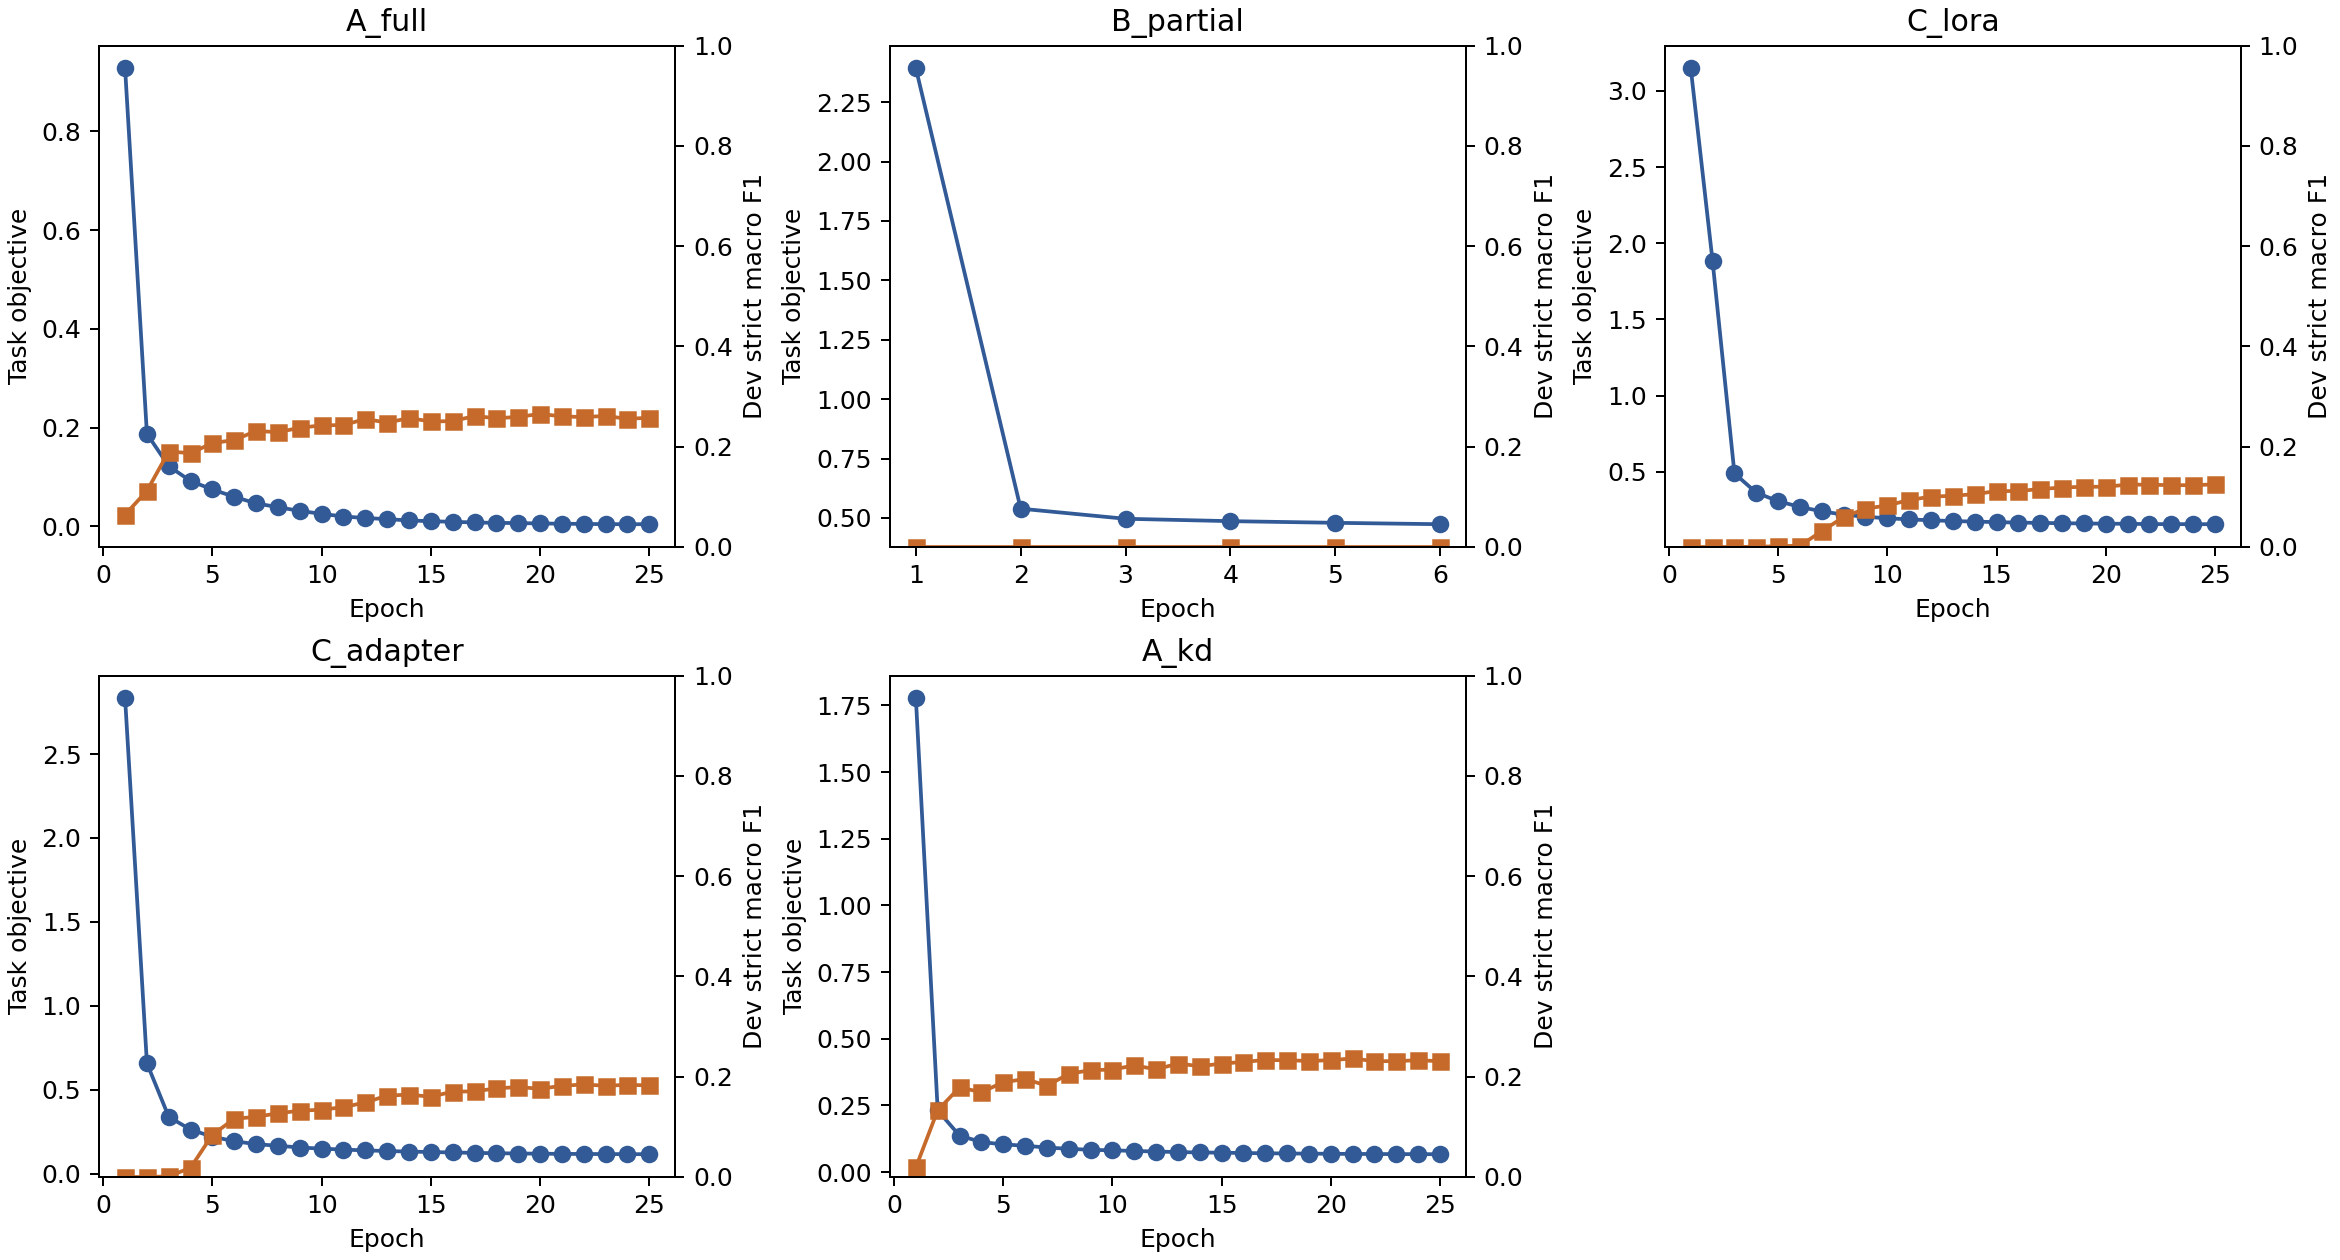

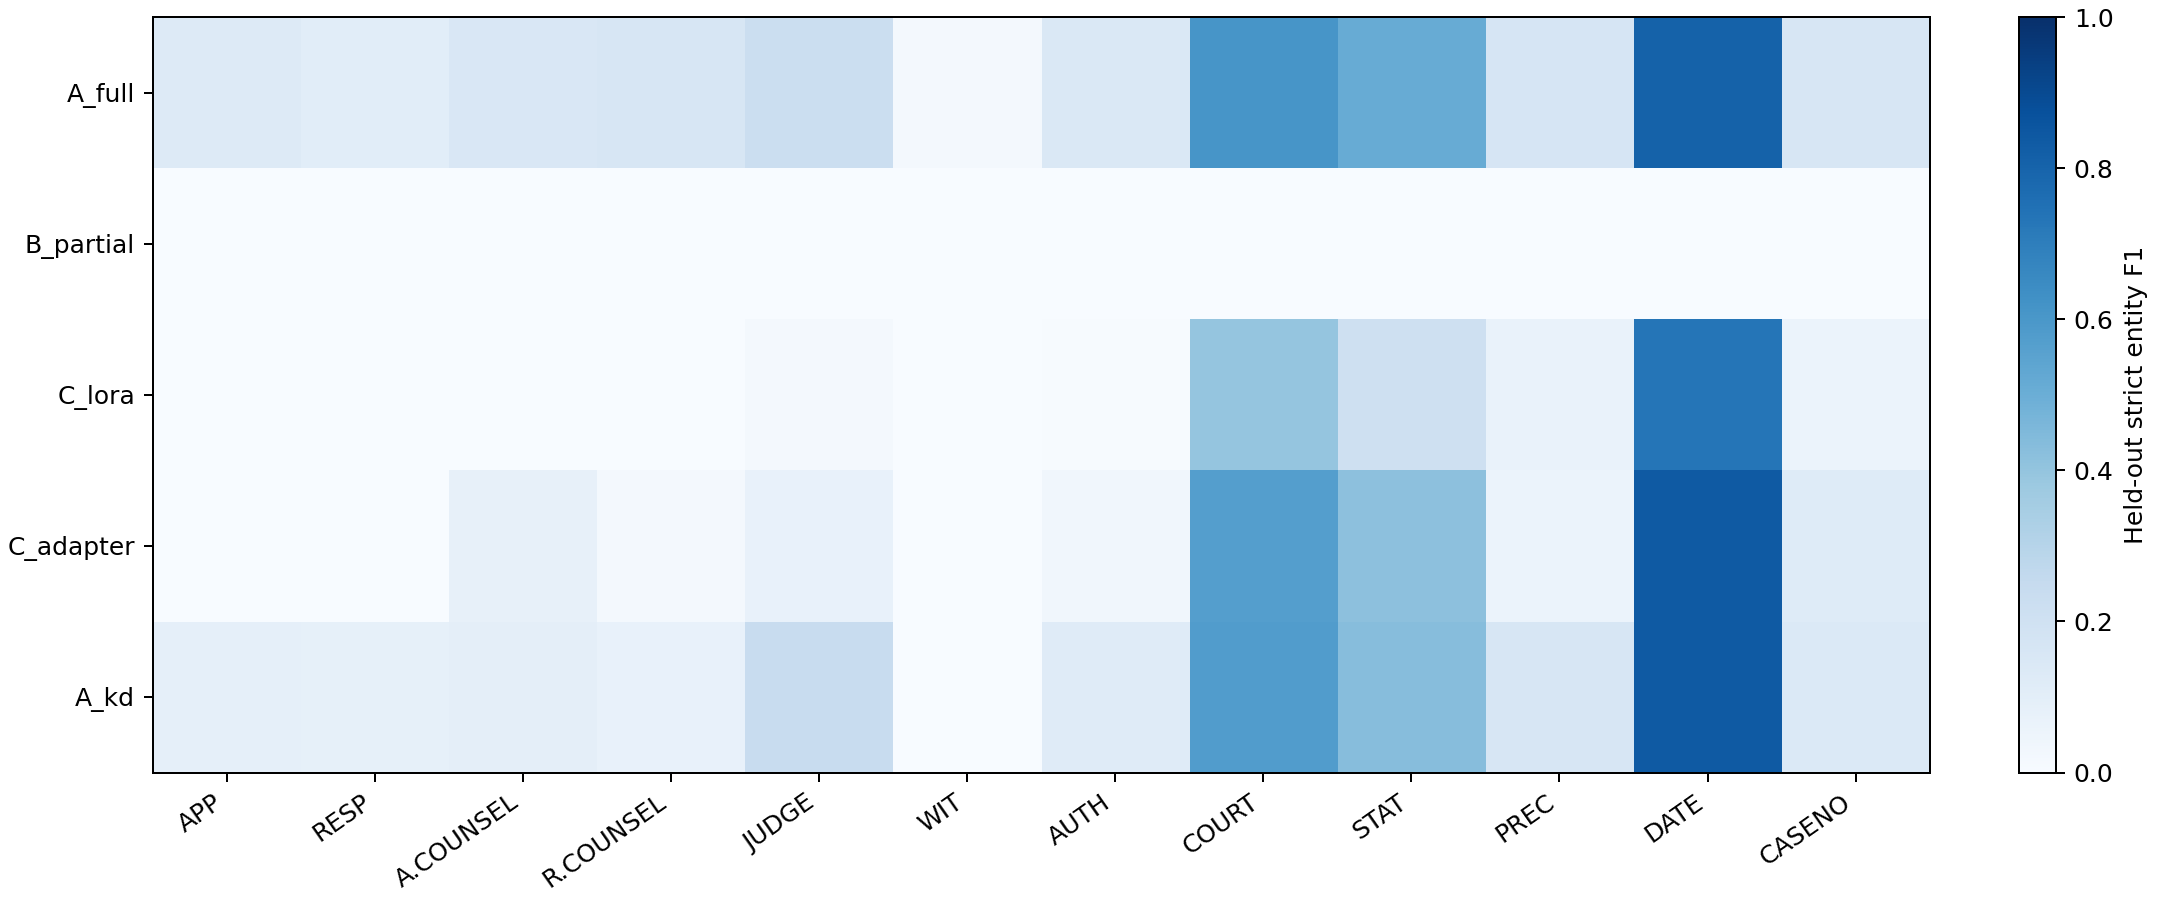

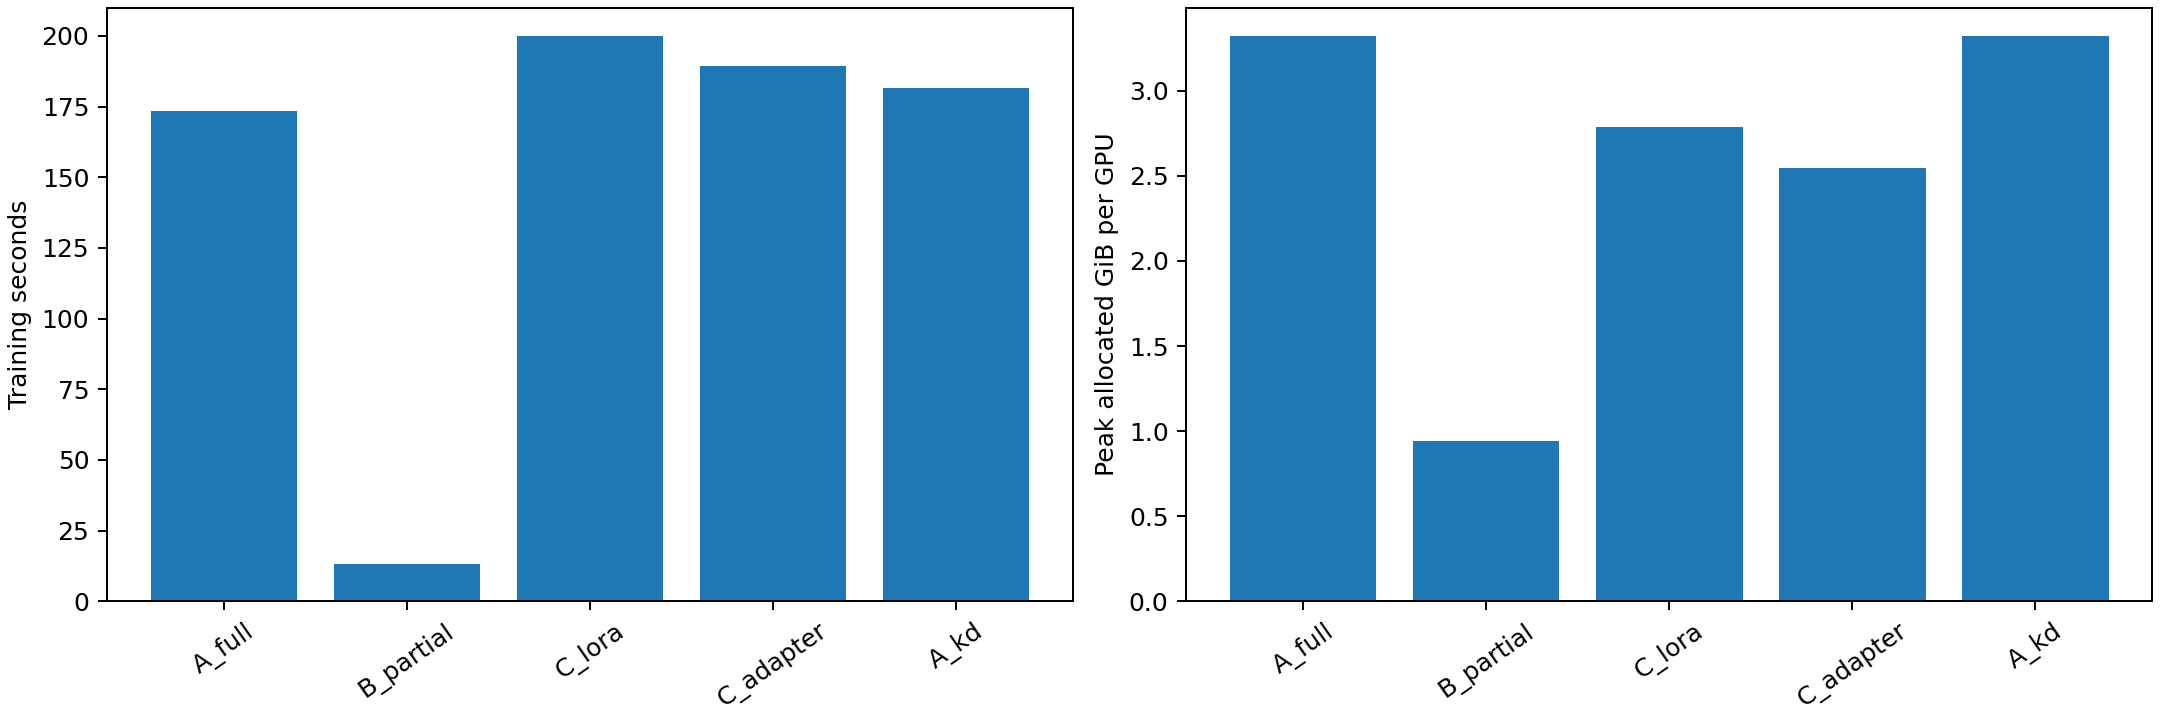

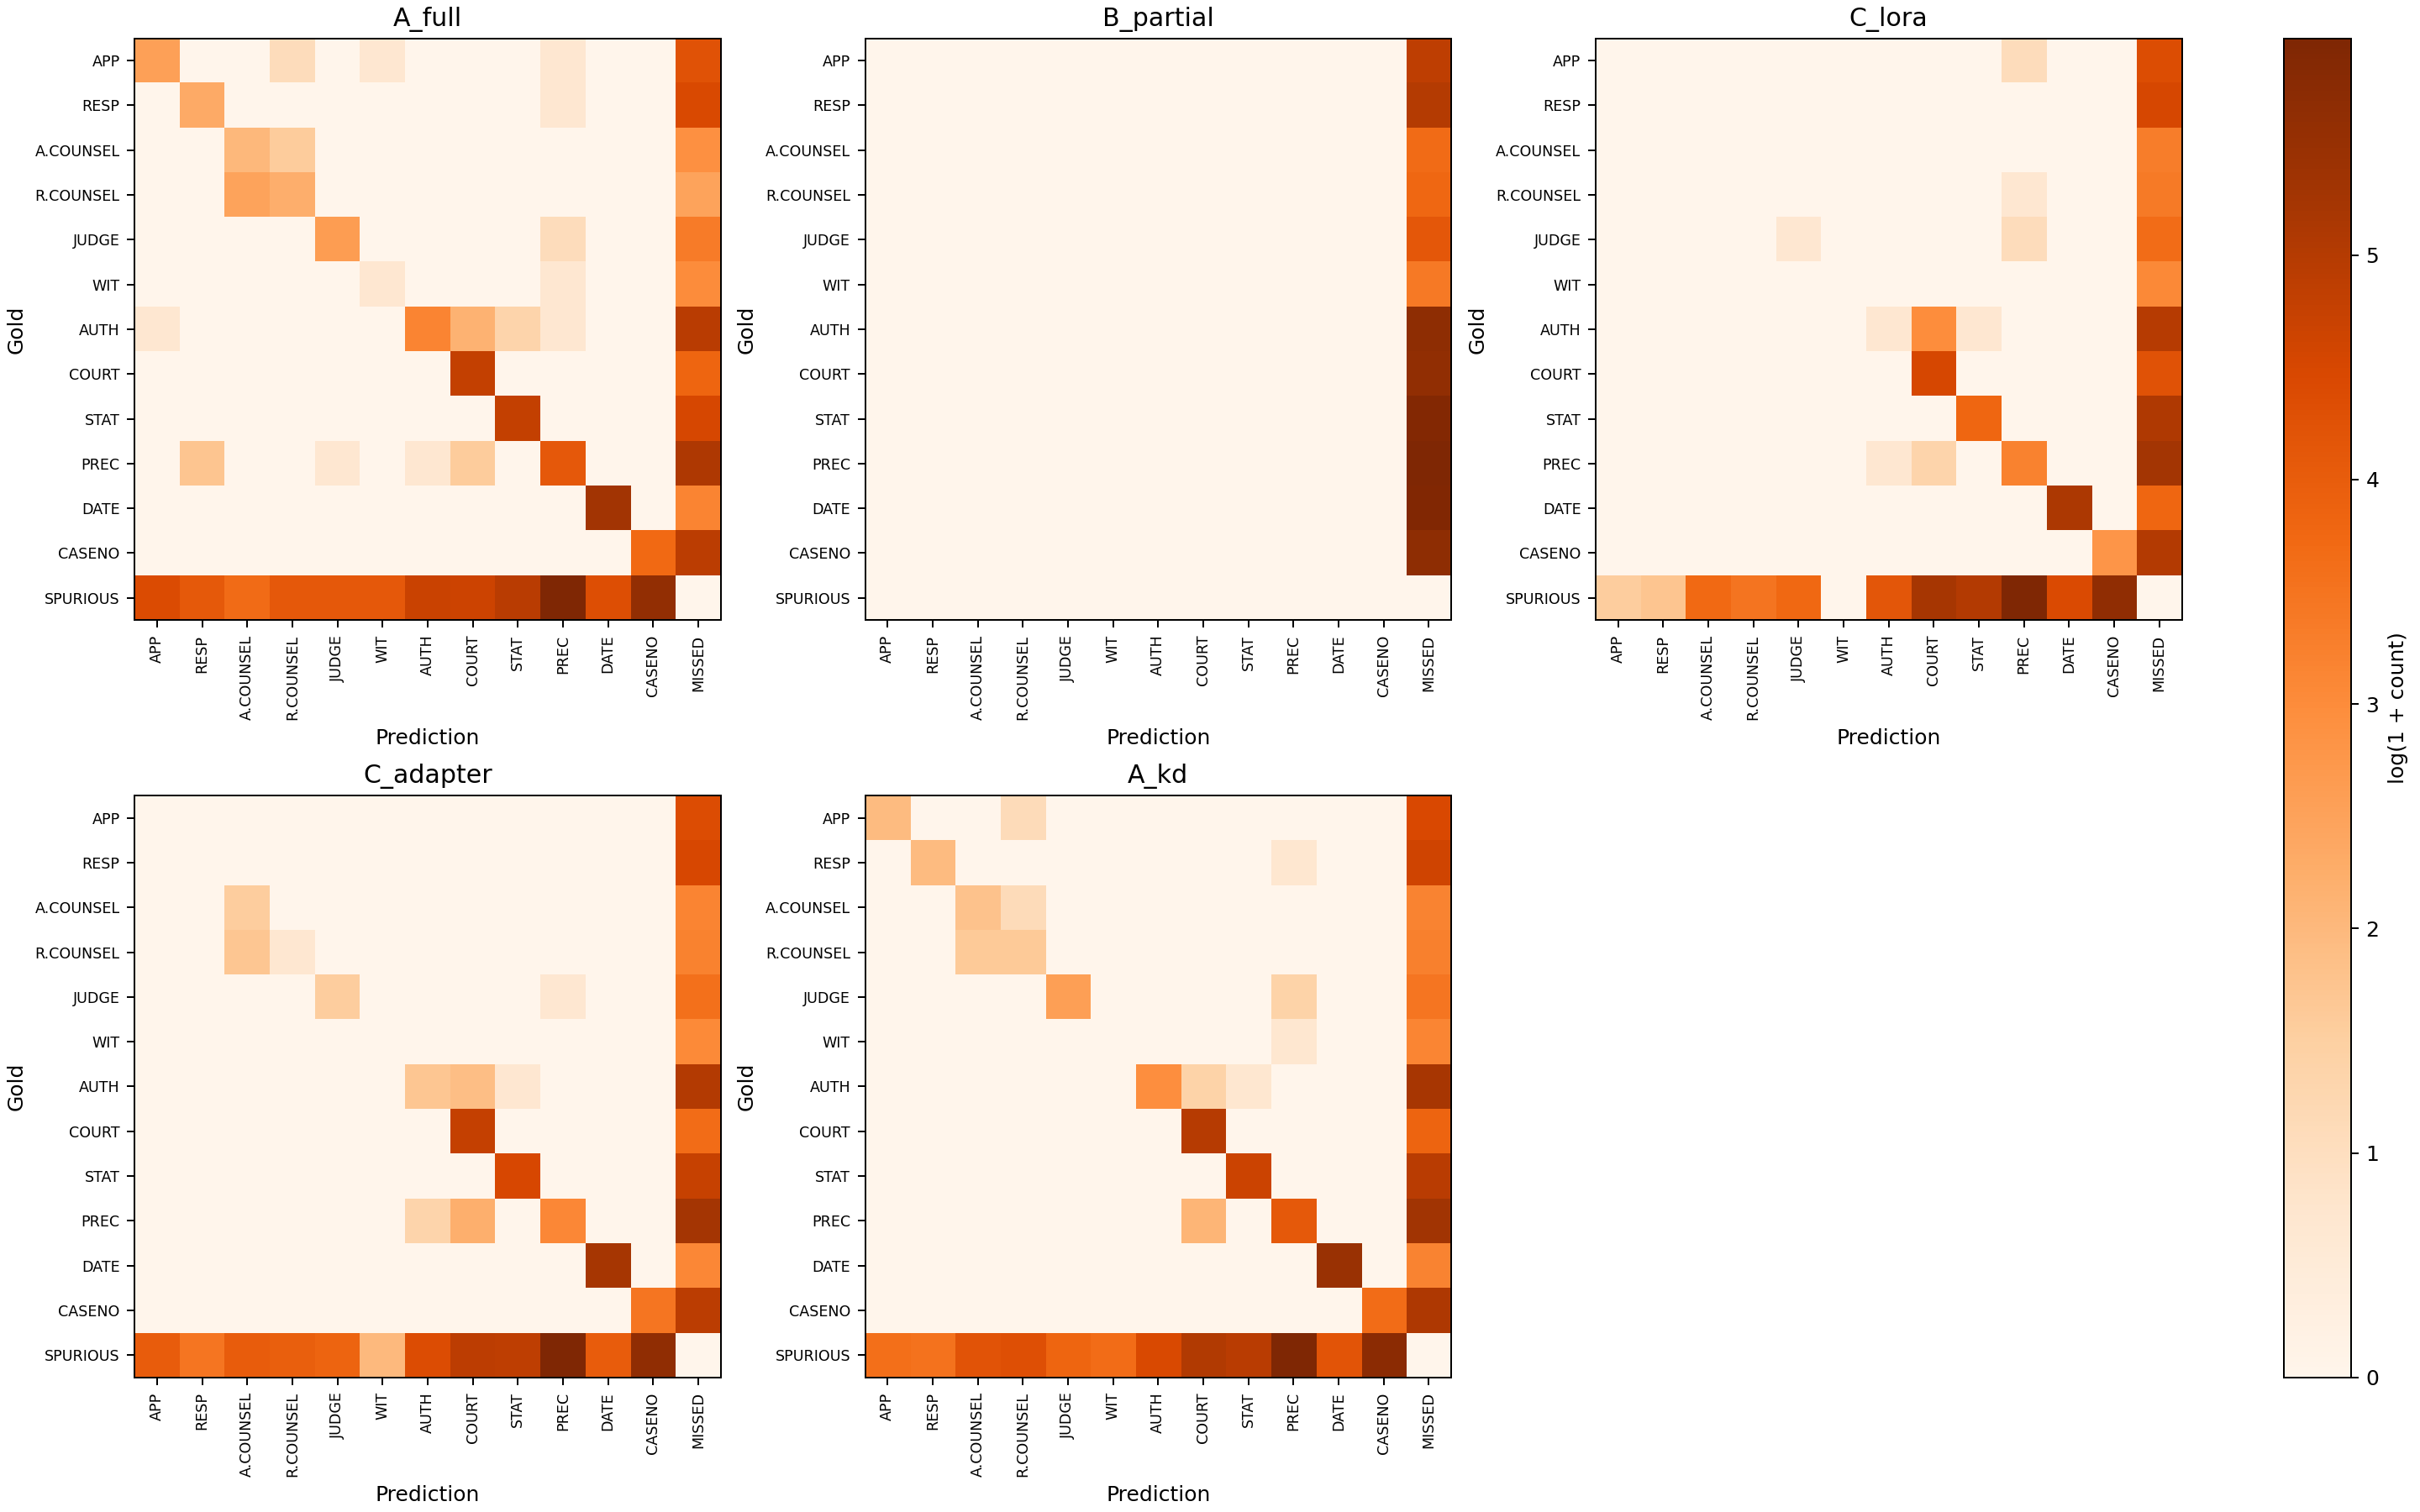

/kaggle/working/cs781-phase2-longer1/results/best_submission.zip

/kaggle/working/cs781-phase2-longer1/results/all_submissions.zip

/kaggle/working/cs781-phase2-longer1/results/results.json

/kaggle/working/cs781-phase2-longer1/results/results.md

/kaggle/working/cs781-phase2-longer1/results/A_full/submission/submission.zip

/kaggle/working/cs781-phase2-longer1/results/B_partial/submission/submission.zip

... (2 outputs left out)

/kaggle/working/cs781-phase2-longer1/results/A_kd/submission/submission.zip

/kaggle/working/cs781-phase2-longer1/results/selected_A_submission.zip

/kaggle/working/cs781-phase2-longer1/results/selected_B_submission.zip

/kaggle/working/cs781-phase2-longer1/results/selected_C_submission.zip

In [22]:
from IPython.display import display, Markdown, Image, FileLink
if RUN_WORKFLOW and results is not None:
    display(Markdown((OUTPUT_DIR / "results.md").read_text()))
    for name in ("training_curves", "per_class_f1", "runtime_memory", "label_confusion"):
        display(Image(filename=str(OUTPUT_DIR / "plots" / (name + ".png"))))
    for path in [OUTPUT_DIR / "best_submission.zip", OUTPUT_DIR / "all_submissions.zip",
                 OUTPUT_DIR / "results.json", OUTPUT_DIR / "results.md"]:
        display(FileLink(str(path)))
    for experiment in EXPERIMENTS:
        display(FileLink(str(OUTPUT_DIR / experiment["name"] / "submission/submission.zip")))
    for family in REQUIRED_FAMILIES:
        display(FileLink(str(OUTPUT_DIR / ("selected_" + family + "_submission.zip"))))
else:
    print("No competition results or submission files have been created in offline mode.")


## Optional: run Model D later


In [23]:
from pathlib import Path

model_dir = Path("/kaggle/input/models/ikrimabadr/modeld/pytorch/default/1")
pt_files = sorted(model_dir.rglob("*.pt"))

for p in pt_files:
    print(p)

if len(pt_files) == 1:
    OPTIONAL_D_CHECKPOINT = str(pt_files[0])
    print("Selected:", OPTIONAL_D_CHECKPOINT)
else:
    print("Choose the exported .pt from phase2_checkpoint, rather than a full resume checkpoint.")
    

/kaggle/input/models/ikrimabadr/modeld/pytorch/default/1/modeldcheckpoint-00003051 (1).pt
Selected: /kaggle/input/models/ikrimabadr/modeld/pytorch/default/1/modeldcheckpoint-00003051 (1).pt


In [24]:
from copy import deepcopy
import gc
import math
from pathlib import Path

from phase2_io import resolve_checkpoints
from phase2_adaptation import load_original, parameter_counts
from phase2_workflow import D_EXPERIMENT, launch

assert PREFLIGHT_COMPLETE, "Run checkpoint/data preflight first."
assert OPTIONAL_D_CHECKPOINT, "Set OPTIONAL_D_CHECKPOINT to your exported D .pt."

# Separate configuration and outputs: only D will run.
d_root = ROOT / "d_only"
d_root.mkdir(parents=True, exist_ok=True)

cfg = checks.read_json(CONFIG_PATH)

d = resolve_checkpoints(
    TOKENIZER_DIR,
    d_root / "phase1_weights",
    overrides={"D": str(OPTIONAL_D_CHECKPOINT)},
    allow_download=False,
    scan_kaggle=False,
    families="D",
)["D"]

original = load_original(d)
d["original_lm_parameters"] = parameter_counts(original)["total"]

window = checks.read_json(
    Path(cfg["cache_dir"]) / "manifest.json"
)["identity"]["window"]

assert math.ceil(window / 8) * 8 <= original.cfg["context_length"]
del original
gc.collect()

d_manifest = d_root / "phase1_manifest.json"
checks.write_json(d_manifest, {"D": d})

cfg["phase1_manifest"] = str(d_manifest)
cfg["output_dir"] = str(d_root / "results")
cfg["experiments"] = [deepcopy(D_EXPERIMENT)]

d_config = d_root / "d_only_config.json"
checks.write_json(d_config, cfg)

results = launch(d_config, RUNTIME, GPU_COUNT)

print(
    "D submission:",
    d_root / "results/D_lorma/submission/submission.zip",
)

D: verified /kaggle/input/models/ikrimabadr/modeld/pytorch/default/1/modeldcheckpoint-00003051 (1).pt (pretraining step 3051)

[1/1] D_lorma: D / lorma
{"experiment": "D_lorma", "family": "D", "method": "lorma", "precision": "fp16", "gpus": 2, "parameters": {"total": 81803673, "trainable": 261785}, "train_windows": 850, "dev_windows": 202, "steps_per_epoch": 27, "phase1_path": "/kaggle/input/models/ikrimabadr/modeld/pytorch/default/1/modeldcheckpoint-00003051 (1).pt"}
D_lorma epoch 1/25 step 10/675 elapsed=5.0s current-run ETA≈331.9s
D_lorma epoch 1/25 step 20/675 elapsed=7.7s current-run ETA≈253.4s
{"experiment": "D_lorma", "epoch": 1, "optimizer_steps": 26, "loss": 2.941629521564751, "training_seconds": 7.697686241000156, "dev_inference_seconds": 2.3467893469999126, "strict_macro_f1": 0.0, "strict_macro_precision": 0.0, "strict_macro_recall": 0.0}
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current contex

In [25]:
%pip -q install "huggingface_hub>=0.34,<1"

Note: you may need to restart the kernel to use updated packages.


In [26]:
from pathlib import Path
from getpass import getpass
from huggingface_hub import HfApi
import hashlib
import json
import tempfile
import shutil

MODEL_D_FOLDER = Path(
    "/kaggle/input/models/ikrimabadr/modeld/pytorch/default/1"
)
REPO_NAME = "cs781-model-d-prefixlm"

# Prefer the compact Phase 2 export over full optimizer/resume checkpoints.
exports = sorted(MODEL_D_FOLDER.rglob("phase2_checkpoint/*.pt"))
candidates = exports or sorted(MODEL_D_FOLDER.rglob("*.pt"))
for p in candidates:
    print(p)

assert len(candidates) == 1, (
    "Multiple or no checkpoints found. Set CHECKPOINT below to the exact exported .pt."
)
CHECKPOINT = candidates[0]

# Use a Hugging Face token with write access; it is not printed or saved.
token = getpass("Hugging Face write token: ")
api = HfApi(token=token)
REPO_ID = f"{api.whoami()['name']}/{REPO_NAME}"
api.create_repo(repo_id=REPO_ID, repo_type="model", private=True, exist_ok=True)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

checkpoint_sha = sha256(CHECKPOINT)
with tempfile.TemporaryDirectory() as tmp:
    stage = Path(tmp)
    shutil.copy2(CHECKPOINT, stage / CHECKPOINT.name)
    # Include export provenance and tokenizer files when present beside the export.
    for p in CHECKPOINT.parent.rglob("*"):
        if p.is_file() and p.suffix in {".json", ".py", ".md", ".txt", ".model"}:
            target = stage / p.relative_to(CHECKPOINT.parent)
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, target)
    (stage / "backup_manifest.json").write_text(json.dumps({
        "checkpoint": CHECKPOINT.name,
        "sha256": checkpoint_sha,
        "bytes": CHECKPOINT.stat().st_size,
        "format": "Custom PyTorch checkpoint; load with the original Model D class."
    }, indent=2))
    commit = api.upload_folder(
        repo_id=REPO_ID, repo_type="model", folder_path=str(stage),
        commit_message="Back up exported CS781 Model D checkpoint"
    )

print("Repository:", f"https://huggingface.co/{REPO_ID}")
print("Checkpoint:", CHECKPOINT.name)
print("SHA-256:", checkpoint_sha)
print("Revision:", commit.oid)

/kaggle/input/models/ikrimabadr/modeld/pytorch/default/1/modeldcheckpoint-00003051 (1).pt


KeyboardInterrupt: Interrupted by user

In [27]:
from pathlib import Path

PHASE = 2  # Change to 3 in the Phase 3 notebook.

# Uses this notebook's active configuration.
BACKUP_CONFIG = Path(CONFIG_PATH)

# Includes optimizer/scheduler states if available.
# False is sufficient for loading models and making predictions.
SAVE_RESUME_STATE = False

print("Configuration:", BACKUP_CONFIG)

Configuration: /kaggle/working/cs781-phase2-longer1/workflow_config.json


In [28]:
import hashlib
import json
import zipfile
from datetime import datetime, timezone
from IPython.display import display, FileLink

def read_json(path):
    return json.loads(Path(path).read_text())

cfg = read_json(BACKUP_CONFIG)
results_dir = Path(cfg["output_dir"])
foundation_manifest_path = Path(cfg["phase1_manifest"])
foundations = read_json(foundation_manifest_path)

runtime_dir = Path(RUNTIME)
tokenizer_dir = Path(TOKENIZER_DIR)

# Archive destination -> original file.
files = {}

def add_file(source, destination):
    source = Path(source)
    if not source.is_file():
        raise FileNotFoundError(f"Required backup file is missing: {source}")
    files[str(destination)] = source

def add_folder(source, destination, skip_names=()):
    source = Path(source)
    if not source.is_dir():
        raise FileNotFoundError(f"Required backup directory is missing: {source}")
    for path in sorted(source.rglob("*")):
        if not path.is_file():
            continue
        relative = path.relative_to(source)
        if "__pycache__" in relative.parts or path.name in skip_names:
            continue
        add_file(path, Path(destination) / relative)

# Require a best checkpoint for every experiment in this configuration.
experiments = cfg["experiments"]
if not experiments:
    raise ValueError("The selected configuration contains no experiments.")

for experiment in experiments:
    checkpoint = results_dir / experiment["name"] / "best.pt"
    if not checkpoint.is_file():
        raise FileNotFoundError(
            f"No trained checkpoint for {experiment['name']}: {checkpoint}"
        )

# Task weights, metrics and predictions.
add_folder(
    results_dir,
    "results",
    skip_names=() if SAVE_RESUME_STATE else ("last.pt",),
)

# Preserve the actual runtime, including any fixes applied in this session.
for path in sorted(runtime_dir.rglob("*.py")):
    if "__pycache__" not in path.parts:
        add_file(path, Path("runtime") / path.relative_to(runtime_dir))

add_folder(tokenizer_dir, "tokenizer")
add_file(BACKUP_CONFIG, "configuration/workflow_config.json")
add_file(foundation_manifest_path, "configuration/phase1_manifest.json")

# PEFT task checkpoints need their original foundation weights.
needed_families = {e["family"] for e in experiments}
missing = needed_families - set(foundations)
if missing:
    raise ValueError(f"Foundation manifest is missing families: {sorted(missing)}")

foundation_locations = {}
for family, info in sorted(foundations.items()):
    source = Path(info["path"])
    if not source.is_file():
        if family in needed_families:
            raise FileNotFoundError(
                f"Original Model {family} weights are missing: {source}"
            )
        continue

    destination = f"phase1_weights/{family}/{source.name}"
    add_file(source, destination)
    foundation_locations[family] = {
        "archive_path": destination,
        "original_path": str(source),
        "recorded_sha256": info.get("sha256"),
    }

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
destination_dir = (
    Path("/kaggle/working")
    if Path("/kaggle/working").is_dir()
    else Path.cwd()
)
BACKUP_ZIP = destination_dir / f"cs781_phase{PHASE}_models_{stamp}.zip"

backup_manifest = {
    "phase": PHASE,
    "created_utc": stamp,
    "experiments": [e["name"] for e in experiments],
    "includes_resume_state": SAVE_RESUME_STATE,
    "foundation_locations": foundation_locations,
    "files": {
        name: {"bytes": path.stat().st_size}
        for name, path in sorted(files.items())
    },
    "restore_note": (
        "Extract the archive and update absolute paths in the configuration "
        "and phase1_manifest.json before using the saved runtime."
    ),
}

# Store without compression: avoids spending CPU time compressing large .pt files.
with zipfile.ZipFile(
    BACKUP_ZIP, "w", compression=zipfile.ZIP_STORED, allowZip64=True
) as archive:
    for index, (name, source) in enumerate(sorted(files.items()), 1):
        archive.write(source, arcname=name)
        if source.suffix == ".pt":
            print(f"[{index}/{len(files)}] Saved {name}")
    archive.writestr(
        "backup_manifest.json",
        json.dumps(backup_manifest, indent=2),
    )

# Record an integrity checksum.
digest = hashlib.sha256()
with BACKUP_ZIP.open("rb") as handle:
    for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
        digest.update(chunk)

BACKUP_SHA256 = digest.hexdigest()
checksum_path = BACKUP_ZIP.with_suffix(".zip.sha256")
checksum_path.write_text(f"{BACKUP_SHA256}  {BACKUP_ZIP.name}\n")

print(f"\nBackup: {BACKUP_ZIP}")
print(f"Size: {BACKUP_ZIP.stat().st_size / 1024**3:.2f} GiB")
print("Experiments:", backup_manifest["experiments"])
print("SHA256:", BACKUP_SHA256)

display(FileLink(str(BACKUP_ZIP)))
display(FileLink(str(checksum_path)))

[3/101] Saved phase1_weights/A/checkpoint-00003051.pt
[4/101] Saved phase1_weights/B/checkpoint-00000762.pt
[5/101] Saved phase1_weights/C/checkpoint-00003051.pt
[6/101] Saved results/A_full/best.pt
[18/101] Saved results/A_kd/best.pt
[30/101] Saved results/B_partial/best.pt
[42/101] Saved results/C_adapter/best.pt
[54/101] Saved results/C_lora/best.pt

Backup: /kaggle/working/cs781_phase2_models_20261019_211809_622412.zip
Size: 3.08 GiB
Experiments: ['A_full', 'B_partial', 'C_lora', 'C_adapter', 'A_kd']
SHA256: f4f267c792cd08de8d95d483fe29b204cab02b1e15dec41fdfdd04e57ba6301d


/kaggle/working/cs781_phase2_models_20261019_211809_622412.zip

/kaggle/working/cs781_phase2_models_20261019_211809_622412.zip.sha256

In [29]:
from getpass import getpass
from huggingface_hub import HfApi

# Prefer a Kaggle secret named HF_TOKEN; otherwise enter a write-access token.
try:
    from kaggle_secrets import UserSecretsClient
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    hf_token = getpass("Hugging Face write-access token: ")

api = HfApi(token=hf_token)
username = api.whoami()["name"]

HF_REPO_ID = f"{username}/cs781-phase{PHASE}-models"
api.create_repo(
    repo_id=HF_REPO_ID,
    repo_type="model",
    private=True,
    exist_ok=True,
)
api.update_repo_visibility(
    repo_id=HF_REPO_ID,
    repo_type="model",
    private=True,
)

remote_path = f"backups/{BACKUP_ZIP.name}"
commit = api.upload_file(
    path_or_fileobj=str(BACKUP_ZIP),
    path_in_repo=remote_path,
    repo_id=HF_REPO_ID,
    repo_type="model",
    commit_message=f"Back up Phase {PHASE} trained models",
)

print("Upload completed.")
print("Repository:", f"https://huggingface.co/{HF_REPO_ID}")
print("Archive path:", remote_path)
print("Commit:", commit.oid)
print("Archive SHA256:", BACKUP_SHA256)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_deprecation.py:131: FutureWarning: 'update_repo_visibility' (from 'huggingface_hub.hf_api') is deprecated and will be removed from version '0.32'. Please use `update_repo_settings` instead.
  warnings.warn(warning_message, FutureWarning)


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Upload completed.
Repository: https://huggingface.co/I-230482/cs781-phase2-models
Archive path: backups/cs781_phase2_models_20261019_211809_622412.zip
Commit: 5af1ea6f2a0f9ad32ff9bc33472de0917754686d
Archive SHA256: f4f267c792cd08de8d95d483fe29b204cab02b1e15dec41fdfdd04e57ba6301d
